# EDA for Competing-Risks Survival Modeling: CAISO Cluster 14-and-Prior and Cluster 15

**Purpose.** Understand the CAISO queue data *as survival data* before any survival model is built. This notebook trains
**no models**. Its job is to answer five questions that decide whether (and how) a competing-risks model can work:

1. Can every project be described by a **time** and an **event** (operation, withdrawal, or still active)?
2. Is the **timeline** trustworthy (snapshot date, missing dates, impossible dates, when records began)?
3. What do the data say about **how and when** projects reach each outcome (nonparametric curves)?
4. Are the **features** usable for survival modeling (leakage, sparsity, drift, effects that change over time)?
5. Given all that, **what can a survival model credibly deliver** for the agentic interconnection-risk screener?

**Who this is written for.** A data scientist with strong supervised/unsupervised ML experience who is new to survival analysis.
Concepts are explained from first principles (Section 0), every section opens with *purpose / why it matters / key terms*, every
result is followed by a plain-language **Interpretation**, and judgment calls are marked **Decision**.

**Background from the earlier work.** A binary classifier ("did the project reach operation before withdrawing?") was built on
projects queued in 2016 or earlier, because newer projects' outcomes were not yet known. Survival analysis is the standard way to
use those unfinished projects instead of discarding them.

**Event coding used throughout** (``event`` column):

| Code | Meaning | What we know |
|---|---|---|
| 0 | Still active (**censored**) | The project survived at least until the snapshot date; its final outcome is unknown |
| 1 | **Reached commercial operation** | Completed sheet; time = queue date to actual online date |
| 2 | **Withdrew** | Withdrawn sheet; time = queue date to withdrawal date |

**Sections**

* **Part A: concepts and data construction.** 0 Primer, 1 Snapshot date, 2 Load and harmonize, 3 Build the survival table,
  4 Left truncation and the observation window, 5 Follow-up and censoring diagnostics.
* **Part B: descriptive survival analysis.** 6 Nonparametric curves, 7 Calendar-time structure, 8 Cluster 15 versus older clusters.
* **Part C: features and model readiness.** 9 Feature EDA for survival, 10 Leakage and eligibility audit, 11 Sample-size and
  event-count feasibility, 12 Evaluation-design feasibility.
* **Part D: conclusions.** 13 Results and recommendations.

In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from IPython.display import display
from scipy import stats

from lifelines import AalenJohansenFitter, CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

sys.path.insert(0, str(Path("..") / "Scripts"))
import caiso_ml_data as cd          # Cluster 14 loader and queue-entry feature logic (from the classifier work)
import caiso_survival_data as sd    # survival table, Cluster 15 harmonization, nonparametric estimators

SEED = 42
C14_PATH = Path("../Data_ML_SQL/CASIO_Cluster_14_and_Prior_Interconnection_Requests.xlsx")
C15_PATH = Path("../Data_ML_SQL/CASIO_Cluster_15_Interconnection_Requests.xlsx")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

EVENT_COLORS = {0: "tab:blue", 1: "tab:green", 2: "tab:red"}
HORIZONS = [1, 2, 3, 5, 8, 10]  # ages (years since queue entry) at which curves are summarized
print("lifelines is used only for cross-checks and Cox models; the nonparametric estimators are in Scripts/caiso_survival_data.py")

lifelines is used only for cross-checks and Cox models; the nonparametric estimators are in Scripts/caiso_survival_data.py


## 0. Primer: survival analysis for a machine-learning practitioner

**Purpose.** Build the vocabulary and intuition used in every later section.

**Why it matters.** Survival data look like ordinary tabular data (one row per project, a few features, an outcome) but have
three properties that break standard supervised learning: outcomes arrive *over time*, many rows are *unfinished*, and some rows were
*never recorded* at all. Treating these as ordinary labels gives biased answers, as the simulation at the end of this section shows.

### 0.1 The core idea: model *when*, not just *whether*

A classifier predicts a label. A survival model predicts a **time-to-event distribution**. Each project has an **age** (time since
queue entry) and, at some age, something ends its stay in the queue.

### 0.2 Key concepts

| Concept | Plain-language meaning | ML analogy |
|---|---|---|
| **Time origin** | The moment the clock starts. Here: the project's **queue date**. | Row timestamp used to define "age" |
| **Event** | What ends observation: operation or withdrawal. | The label |
| **Right-censoring** | The project is still active at the snapshot date. We know it lasted *at least* this long, not how it ends. | A label that is only a lower bound (like "customer still subscribed today") |
| **Left truncation (delayed entry)** | Projects that ended *before* records began were never recorded, so older projects only appear if they survived into the recording period. | Survivorship bias in how the dataset was assembled |
| **Competing risks** | Two (or more) mutually exclusive outcomes; one happening makes the other impossible. | Multi-class label where "which one comes first" matters |
| **Survival function S(t)** | Probability a project is still in the queue (no event of any kind) at age t. | Retention curve |
| **Hazard h(t)** | The instantaneous event rate at age t among projects still in the queue. | Per-period churn rate, conditional on still being a customer |
| **Cumulative hazard H(t)** | Running total of the hazard over age. | Area under the churn-rate curve |
| **Cause-specific hazard h_k(t)** | The rate of outcome k at age t among projects still in the queue. | Churn rate for one reason |
| **Cumulative incidence function CIF_k(t)** | The probability that the *first* event is outcome k *and* it has happened by age t. | "Probability of operating by year t," accounting for withdrawals taking projects out of the running |

### 0.3 The relationships that matter

* With competing events, **S(t) + CIF_operation(t) + CIF_withdrawal(t) = 1** at every age. Each project is, at age t, either still in
  the queue, or has operated, or has withdrawn.
* **The CIF of an outcome is not determined by that outcome's hazard alone.** It depends on the other outcome's hazard too, because a
  withdrawn project can never operate. A high withdrawal hazard in the first two years *lowers* the eventual probability of operation even
  if the operation hazard is unchanged.
* **Cause-specific hazards** describe *how fast* each outcome happens among survivors (good for understanding mechanisms). **CIFs**
  describe *how likely* each outcome is by a given age (good for answering "what are the chances?"). A competing-risks model typically
  estimates cause-specific hazards and converts them to CIFs. The alternative, a **subdistribution (Fine-Gray) hazard**, models the CIF
  directly. Both are options for the later modeling plan.
* **Kaplan-Meier (KM)** estimates S(t) when there is one event type. If you use it for one outcome while *censoring* the competing
  outcome, the estimate behaves as if projects that withdrew were still waiting to operate. That is wrong, and it **overstates** the
  probability of operation. The **Aalen-Johansen (AJ)** estimator is the correct generalization to competing events.

### 0.4 What the picture looks like

The next cell sketches six projects on the *age* scale. Later, the same projects are drawn on the *calendar* scale with a **Lexis
diagram**, the master picture for this notebook.

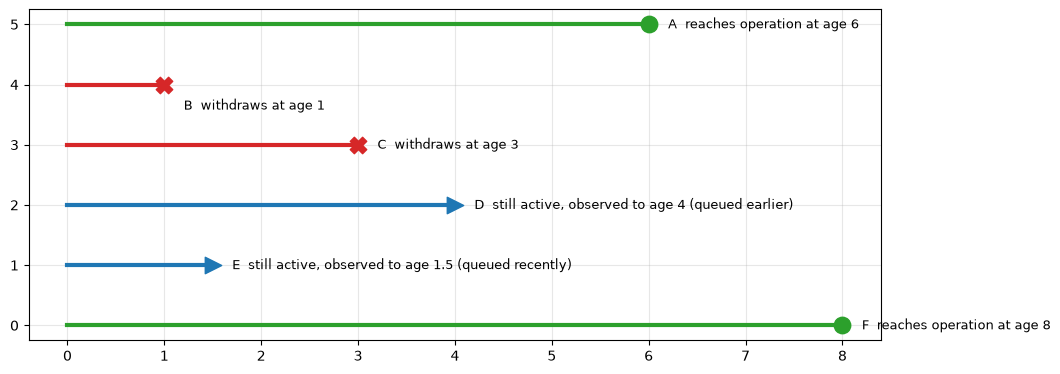

In [ ]:

# Sketch: six projects on the age scale (years since queue entry).
examples = [
    ("A  reaches operation at age 6", 6.0, 1), ("B  withdraws at age 1", 1.0, 2), ("C  withdraws at age 3", 3.0, 2),
    ("D  still active, observed to age 4 (queued earlier)", 4.0, 0), ("E  still active, observed to age 1.5 (queued recently)", 1.5, 0),
    ("F  reaches operation at age 8", 8.0, 1),
]

fig, ax = plt.subplots(figsize=(11, 4.3))
for row, (label, age, event) in enumerate(examples[::-1]):
    ax.plot([0, age], [row, row], color=EVENT_COLORS[event], lw=3)
    marker = {1: "o", 2: "X", 0: ">"}[event]
    ax.scatter([age], [row], s=140, color=EVENT_COLORS[event], marker=marker, zorder=3)
    # Adjust label position for green line ("B  withdraws at age 1"), which is row == 4 in this loop
    if label.startswith("B  withdraws"):
        ax.text(age + 0.2, row - 0.35, label, va="center", fontsize=9)  # move text slightly lower
    else:
        ax.text(age + 0.2, row, label, va="center", fontsize=9)

**Interpretation.**
* Projects **A** and **F** reach operation, but only after 6 and 8 years. Projects **B** and **C** withdraw within 1 to 3 years. Withdrawal is the *fast* exit, operation is the *slow* one.
* Projects **D** and **E** are the heart of the problem. They are neither successes nor failures yet. D has been observed for 4 years and E for only 1.5 years, so they carry different amounts of information.
  Dropping them throws away real information; labeling them "failures" is wrong, because many will operate. Survival methods keep them in the at-risk group for exactly as long as they were observed and then stop (**censoring**).
* The sketch also shows why **age** is the natural clock: every project starts at age 0 on its queue date, whatever the calendar year.

### 0.5 The Lexis diagram: calendar time versus age

A **Lexis diagram** plots *calendar date* on the horizontal axis and *age* on the vertical axis. Every project is a **diagonal line**
that starts at age 0 on its queue date and rises one year of age per calendar year until something ends it. It shows censoring,
truncation, and cluster structure at a glance:

* **Censoring:** lines that reach the **snapshot** (right vertical line) without ending are right-censored.
* **Left truncation:** if records begin on the **window start** (left vertical line), a project that started and ended *before* that date
  is never recorded, so it is missing from the data. A project that started earlier but was still alive at the window start *is*
  recorded, but it enters observation already at a positive age. Counting it as if it entered at age 0 would credit it with survival
  time during which a project like it could have disappeared unseen.

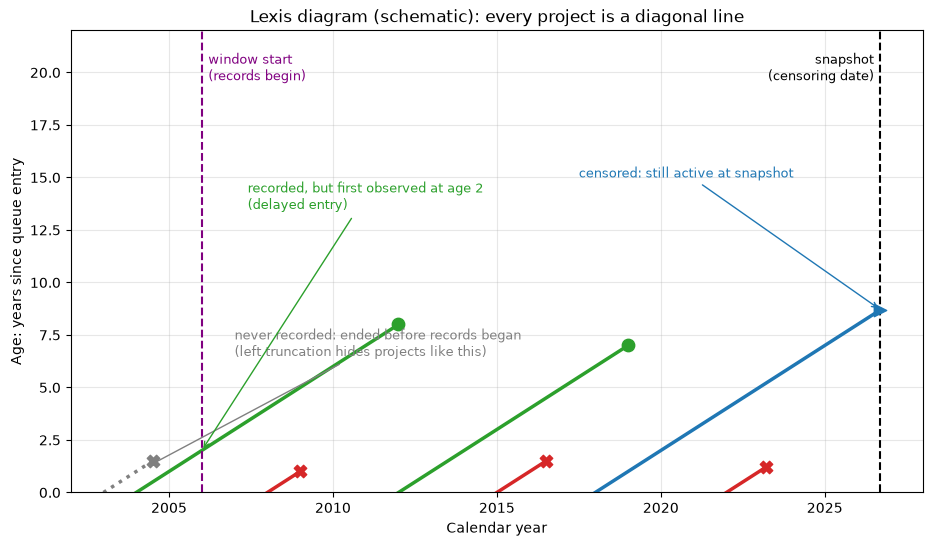

In [3]:
# Schematic Lexis diagram with synthetic projects.
snapshot_x, window_x = 2026.7, 2006.0
lives = [  # (queue year, end year, outcome, recorded?)
    (2003.0, 2004.5, 2, False), (2004.0, 2012.0, 1, True), (2008.0, 2009.0, 2, True),
    (2012.0, 2019.0, 1, True), (2018.0, snapshot_x, 0, True), (2022.0, 2023.2, 2, True), (2015.0, 2016.5, 2, True),
]
fig, ax = plt.subplots(figsize=(11, 6))
for q, end, ev, recorded in lives:
    ax.plot([q, end], [0, end - q], color=EVENT_COLORS[ev] if recorded else "gray", lw=2.5, ls="-" if recorded else ":")
    ax.scatter([end], [end - q], color=EVENT_COLORS[ev] if recorded else "gray", s=80, zorder=3,
               marker={1: "o", 2: "X", 0: ">"}[ev])
ax.axvline(snapshot_x, color="k", ls="--"); ax.axvline(window_x, color="purple", ls="--")
ax.text(snapshot_x - 0.2, 21, "snapshot\n(censoring date)", ha="right", va="top", fontsize=9)
ax.text(window_x + 0.2, 21, "window start\n(records begin)", ha="left", va="top", fontsize=9, color="purple")
ax.annotate("never recorded: ended before records began\n(left truncation hides projects like this)", xy=(2004.3, 1.2), xytext=(2007.0, 6.5),
            arrowprops=dict(arrowstyle="->", color="gray"), color="gray", fontsize=9)
ax.annotate("recorded, but first observed at age 2\n(delayed entry)", xy=(2006.0, 2.0), xytext=(2007.4, 13.5),
            arrowprops=dict(arrowstyle="->", color="tab:green"), color="tab:green", fontsize=9)
ax.annotate("censored: still active at snapshot", xy=(snapshot_x, 8.7), xytext=(2017.5, 15), arrowprops=dict(arrowstyle="->", color="tab:blue"),
            color="tab:blue", fontsize=9)
ax.set(xlim=(2002, 2028), ylim=(0, 22), xlabel="Calendar year", ylabel="Age: years since queue entry",
       title="Lexis diagram (schematic): every project is a diagonal line")
plt.show()

**Interpretation.**
* The diagonal lines show projects aging as calendar time passes. Where a line ends tells us what happened to it.
* The gray dotted project started and ended *before* records began. If a dataset is assembled from files that only began in the window, such a project is **simply absent**, and nothing in the data would tell us it ever existed.
  That is **left truncation**. Because quick withdrawals are the most common outcome, the missing projects are disproportionately quick withdrawals, which makes early cohorts look healthier than they were.
* The green project that began before the window start is recorded, but is only *observed* from age 2. The correct treatment (**delayed entry**) counts it as at risk only from age 2 onward.

### 0.6 Why the naive approaches fail: a simulation

We can only see the consequences of mistakes when we know the truth, so we **simulate** a queue where we do:

* every project has a latent *time to withdrawal* (fast, median about 1.5 years) and a latent *time to operation* (slow, median about
  6.7 years); whichever comes first is what actually happens (the other never happens);
* projects entered the queue at different times, so each is observed for a different length (1 to 10 years) before the snapshot.

We then estimate "the probability a project has reached operation by year 8" four ways and compare with the **true** value (computable
because we also simulated what would happen with unlimited follow-up):

1. **Naive 1 minus KM:** treat withdrawals as censored.
2. **Drop active projects** and compute the operational share among resolved projects (a common ML shortcut).
3. **Label active projects as "not operational"** and compute the operational share of all projects.
4. **Aalen-Johansen** (the correct competing-risks estimator).

,P(operation by year 8)
TRUE value,0.080
1. naive 1 - KM,0.695
2. drop active projects,0.061
3. active labelled not-operational,0.052
4. Aalen-Johansen (ours),0.079
Aalen-Johansen (lifelines),0.079


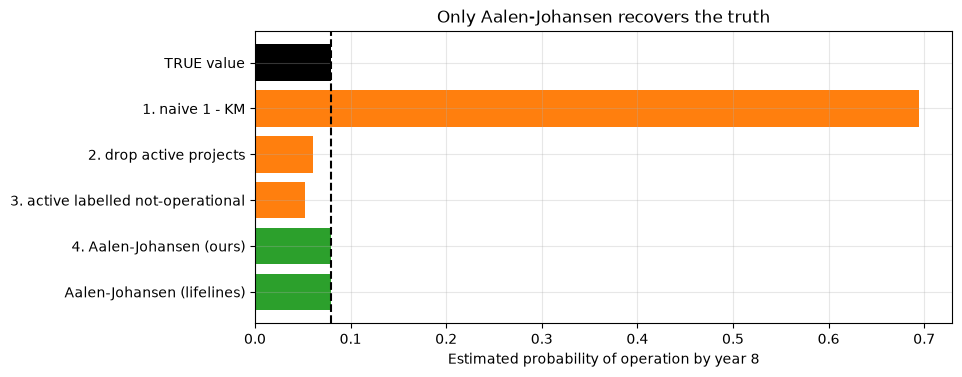

In [4]:
rng = np.random.default_rng(SEED)
N, H = 20000, 8.0
t_wd = rng.exponential(1 / 0.45, N)        # latent time to withdrawal (fast)
t_op = 7.5 * rng.weibull(3.0, N)           # latent time to operation (slow)
first = np.minimum(t_wd, t_op)
cause = np.where(t_op < t_wd, 1, 2)        # what actually happens first
truth = ((cause == 1) & (first <= H)).mean()   # true CIF of operation at age H (no censoring needed: we simulated it)

follow_up = rng.uniform(1, 10, N)          # staggered entry: each project is observed for a different length
obs = np.minimum(first, follow_up)
ev = np.where(first <= follow_up, cause, 0)

naive = 1 - sd.step_value(sd.km_survival(obs, (ev == 1).astype(int))["survival"], H)[0]
dropped = (ev == 1).sum() / (ev > 0).sum()          # operational share among resolved projects only
labelled = (ev == 1).mean()                         # active projects counted as "not operational"
aj = sd.cif_at(obs, ev, 1, H)[0]

# Cross-check our estimator against lifelines.
ajf = AalenJohansenFitter(calculate_variance=False, seed=1).fit(obs, ev, event_of_interest=1)
lf = ajf.cumulative_density_.iloc[:, 0]; lifelines_value = lf[lf.index <= H].iloc[-1]

results = pd.Series({"TRUE value": truth, "1. naive 1 - KM": naive, "2. drop active projects": dropped,
                     "3. active labelled not-operational": labelled, "4. Aalen-Johansen (ours)": aj,
                     "   Aalen-Johansen (lifelines)": lifelines_value}, name="P(operation by year 8)")
display(results.to_frame())
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = ["black", "tab:orange", "tab:orange", "tab:orange", "tab:green", "tab:green"]
ax.barh(results.index[::-1], results.values[::-1], color=colors[::-1])
ax.axvline(truth, color="black", ls="--")
ax.set(xlabel="Estimated probability of operation by year 8", title="Only Aalen-Johansen recovers the truth")
plt.show()

**Interpretation.**
* The true probability of operation by year 8 is **8.0%**. Only the Aalen-Johansen estimator recovers it (7.9%, matching the lifelines implementation to three decimals).
* **Naive 1 minus KM gives 69.5%**, more than eight times too high. When withdrawals are censored, the estimator pretends those projects could still have operated, and so it
  spreads their "future" onto the survivors. This is not a small bias; it is the dominant error when a competing outcome (here withdrawal) is common, as it is in the real queue.
* Dropping unresolved projects (6.1%) and counting them as failures (5.2%) are both biased low, in opposite ways from the naive estimate: they are simply wrong in a different direction, because the active projects are neither failures nor missing at random.
* **Takeaway for this project:** every probability reported from this dataset must come from a competing-risks estimator. In the real data the same mistake gives roughly 34% instead of 9% for operation by year 8 (Section 6).

## 1. Snapshot date

**Purpose.** Establish the date on which the data were exported.

**Why it matters.** The **snapshot date is the censoring date for every active project.** A project that entered the queue on
2020-04-15 and is still active on the snapshot has an observed duration of (snapshot - 2020-04-15), and that is *all* we know about
it. A wrong snapshot would shift every censored duration. The earlier classifier loader discarded the `Report Run Date` column;
here it is read directly.

**Key term.** *Administrative censoring*: censoring caused only by the study ending (the snapshot), not by anything about the project.
It is the benign kind, because it does not depend on the project's prospects.

In [5]:
snapshots = sd.read_snapshot_dates(C14_PATH)
display(pd.DataFrame({"sheet": list(snapshots), "report_run_date": list(snapshots.values())}))
print("Cluster 15 workbook states no snapshot date. Assumed snapshot:", sd.C15_ASSUMED_SNAPSHOT.date(), "(same as Cluster 14).")

,sheet,report_run_date
0,Grid GenerationQueue,2026-09-24
1,Completed Generation Projects,2026-09-24
2,Withdrawn Generation Projects,2026-09-24


Cluster 15 workbook states no snapshot date. Assumed snapshot: 2026-09-24 (same as Cluster 14).


**Interpretation.**
* All three sheets of the Cluster 14-and-prior workbook state **Report Run Date: 09/24/2026**, so that is the censoring date for the 262 active projects.
* The latest dated events in the file are an actual online date of 2026-09-14 and a withdrawal on 2026-09-17: both fall a few days before the snapshot, which is consistent with a queue export on 2026-09-24.
* Cluster 15's latest withdrawal is on 2026-07-14, 72 days before the assumed snapshot. A gap that long is not unusual for that cluster (Section 8.4 shows five-month stretches with no withdrawals), so nothing in the data contradicts the assumption.

**Decision: Cluster 15 snapshot.** The Cluster 15 workbook carries no `Report Run Date`. Its latest dated withdrawal is 2026-07-14, so the
true export is on or after that date. Following the agreed assumption we use the **same snapshot as Cluster 14 (2026-09-24)**. Section 8
quantifies how much this assumption could matter by repeating the key Cluster 15 estimate under 2026-07-14.

## 2. Load and harmonize both workbooks

**Purpose.** Combine the Cluster 14-and-prior workbook (Active, Completed, Withdrawn sheets) and the Cluster 15 workbook (Active and
Withdrawn sheets) into one table with a common set of columns.

**Why it matters.** The two workbooks use different layouts. A survival table needs the same fields, with the same meaning, for every
project, or comparisons across clusters would reflect formatting differences rather than project behavior. Cluster 15 also adds a
new cohort that has only about a year and a half of follow-up.

**Key terms.**
* *Cohort*: the cluster a project belongs to (`C01`..`C15`); serial, fast-track, and transition projects are pooled as `Pre-cluster`.
* *Harmonize*: rename and re-encode columns so the same concept has one name and one set of values.

In [6]:
projects = sd.load_all_projects(C14_PATH, C15_PATH)
counts = (projects.groupby(["source", "source_sheet", "outcome"]).size().rename("projects").reset_index())
display(counts)

latest = projects.groupby("source_sheet").agg(
    snapshot=("snapshot_date", "first"), first_queue_date=("queue_date", "min"), last_queue_date=("queue_date", "max"),
    latest_withdrawal=("withdrawn_date", "max"), latest_online_date=("actual_online_date", "max"))
display(latest)
assert projects["project_id"].is_unique and len(projects) == 2278 + 170

,source,source_sheet,outcome,projects
0,C14 workbook,Completed Generation Projects,operational,252
1,C14 workbook,Grid GenerationQueue,active,262
2,C14 workbook,Withdrawn Generation Projects,withdrawn,1764
3,C15 workbook,C15 Cluster 15,active,86
4,C15 workbook,C15 Withdrawn,withdrawn,84


,snapshot,first_queue_date,last_queue_date,latest_withdrawal,latest_online_date
source_sheet,,,,,
C15 Cluster 15,2026-09-24,2025-02-12,2025-02-12,NaT,NaT
C15 Withdrawn,2026-09-24,2025-02-12,2025-02-12,2026-07-14,NaT
Completed Generation Projects,2026-09-24,1999-11-01,2021-05-03,NaT,2026-09-14
Grid GenerationQueue,2026-09-24,2003-11-18,2021-04-15,NaT,NaT
Withdrawn Generation Projects,2026-09-24,2000-08-09,2023-03-02,2026-09-17,NaT


**Interpretation.**
* The row counts **reconcile exactly with the source workbooks**: 252 operational + 1,764 withdrawn + 262 active in the older workbook, and 86 active + 84 withdrawn in Cluster 15, for **2,448 projects**. No project ID appears in both workbooks, so nothing is double counted.
* Cluster 15 contains a single queue date (2025-02-12) for all 170 projects. There is no variation in entry time within the cohort, which is typical of a cluster-based process and matters for dependence (Section 7).
* Cluster 14 contains a few projects with older queue dates (the earliest is in 2011), which is why it is not a single point in time. All projects in the older workbook have queue dates between 1999 and 2023.

In [7]:
crosswalk = pd.DataFrame([
    ("Project ID", "Queue Position", "Queue Number", "queue_position / project_id", "No ID appears in both workbooks"),
    ("Time origin", "Queue Date", "Queue Date", "queue_date", "All Cluster 15 projects share 2025-02-12"),
    ("Application date", "Interconnection Request Receive Date", "Application Date", "ir_receive_date", "Used only as an alternative time origin"),
    ("Technology", "Type-1..3 and Fuel-1..3 (separate columns)", "Generation/Fuel 1..3 ('Type/Fuel' string)", "type_i, fuel_i", "Split on '/' for Cluster 15"),
    ("Capacity", "Net MWs to Grid; MW-1..3", "NET MW POI; NET MW 1..3", "net_mw_to_grid, mw_i", ""),
    ("Location", "County, State, Utility", "PROJECT COUNTY, Project State, PTO", "county, state, utility", "' County' suffix stripped for Cluster 15"),
    ("Interconnection point", "Station or Transmission Line (text)", "POI (text) and Voltage kV (number)", "poi_station, poi_kv", "kV parsed from text (C14) or read directly (C15)"),
    ("Requested online date", "Proposed On-line Date (as filed with IR)", "Requested COD", "proposed_online_date", ""),
    ("Service type", "Full Capacity / Partial / Energy Only", "Service Type (long phrases)", "service_type", "Collapsed to the Cluster 14 vocabulary"),
    ("Study process", "Study Process (C01..C14, Serial LGIP, ...)", "(absent)", "study_process", "Set to 'C15' for all Cluster 15 projects"),
    ("Withdrawal date", "Withdrawn Date (Withdrawn sheet)", "Withdrawal Date (Withdrawn sheet)", "withdrawn_date", "Event date for event = 2"),
    ("Actual online date", "Actual On-line Date (Completed sheet)", "(none: no operational projects yet)", "actual_online_date", "Event date for event = 1"),
    ("Post-entry milestones", "Study status columns, IA status, TPD, off-peak deliverability", "(absent)", "excluded", "Not queue-entry information; see Section 10"),
    ("Cluster 15 only", "-", "Project Number, Study Area", "kept as extra columns", "Not used"),
], columns=["Concept", "Cluster 14-and-prior header", "Cluster 15 header", "Harmonized name", "Note"])
with pd.option_context("display.max_colwidth", 70):
    display(crosswalk)

fields = ["queue_date", "ir_receive_date", "proposed_online_date", "net_mw_to_grid", "fuel_1", "type_1", "service_type", "county",
          "state", "utility", "poi_station", "voltage_kv", "study_process", "withdrawn_date", "actual_online_date",
          "ia_status", "phase1_study", "phase2_study"]
availability = projects.groupby("source")[fields].apply(lambda g: g.notna().mean()).T
display(availability)

,Concept,Cluster 14-and-prior header,Cluster 15 header,Harmonized name,Note
0,Project ID,Queue Position,Queue Number,queue_position / project_id,No ID appears in both workbooks
1,Time origin,Queue Date,Queue Date,queue_date,All Cluster 15 projects share 2025-02-12
2,Application date,Interconnection Request Receive Date,Application Date,ir_receive_date,Used only as an alternative time origin
3,Technology,Type-1..3 and Fuel-1..3 (separate columns),Generation/Fuel 1..3 ('Type/Fuel' string),"type_i, fuel_i",Split on '/' for Cluster 15
4,Capacity,Net MWs to Grid; MW-1..3,NET MW POI; NET MW 1..3,"net_mw_to_grid, mw_i",
5,Location,"County, State, Utility","PROJECT COUNTY, Project State, PTO","county, state, utility",' County' suffix stripped for Cluster 15
6,Interconnection point,Station or Transmission Line (text),POI (text) and Voltage kV (number),"poi_station, poi_kv",kV parsed from text (C14) or read directly (C15)
7,Requested online date,Proposed On-line Date (as filed with IR),Requested COD,proposed_online_date,
8,Service type,Full Capacity / Partial / Energy Only,Service Type (long phrases),service_type,Collapsed to the Cluster 14 vocabulary
9,Study process,"Study Process (C01..C14, Serial LGIP, ...)",(absent),study_process,Set to 'C15' for all Cluster 15 projects


source,C14 workbook,C15 workbook
queue_date,1.000,1.000
ir_receive_date,0.996,1.000
proposed_online_date,1.000,1.000
net_mw_to_grid,1.000,1.000
fuel_1,0.998,1.000
type_1,1.000,1.000
service_type,0.826,1.000
county,0.998,1.000
state,0.998,1.000
utility,0.999,1.000


**Interpretation.**
* Every concept needed for survival modeling (queue date, outcome dates, size, technology, location, voltage, service type, requested online date) exists in **both** workbooks under different names, and all of them are now harmonized.
* **Only Cluster 15 has an explicit voltage** column; for older projects voltage is parsed from the station text, and that is why `poi_kv` is 4% missing overall (mostly older projects) and 0% missing for Cluster 15.
* **`service_type` is missing for 17% of the older workbook** (the table shows 82.6% available). Section 9.1 shows that this is an era artifact (older records), not random.
* **The post-entry milestone fields (study results, agreement status) are 0% available for Cluster 15.** A model that used them could never score a Cluster 15 project, a second reason, beyond leakage, to keep them out (Section 10).

In [8]:
# How Cluster 15's combined technology strings were mapped to the Cluster 14 type/fuel vocabulary.
c15 = projects[projects["cohort"] == "C15"]
mapping = (c15.groupby(["generation_fuel_1", "type_1", "fuel_1"]).size().rename("projects").reset_index()
           .sort_values("projects", ascending=False))
display(mapping)
print("Cluster 15 service types after mapping:", c15["service_type"].value_counts().to_dict())

,generation_fuel_1,type_1,fuel_1,projects
3,Storage/Battery,Storage,Battery,94
2,Photovoltaic/Solar,Photovoltaic,Solar,70
5,Wind Turbine/Wind,Wind Turbine,Wind Turbine,3
0,Biomass/Biofuel,Biomass,Biofuel,1
1,Hydro/Pumped-Storage Hydro,Hydro,Pumped-Storage hydro,1
4,Storage/Compressed Air,Storage,Compressed Air,1


Cluster 15 service types after mapping: {'Full Capacity': 115, 'Energy Only': 55}


**Interpretation.**
* Cluster 15 is **55% batteries (94 of 170 as the first component), 41% solar (70), 2% wind, and a few unusual fuels**. After mapping, battery storage is `Storage` + `Battery`, exactly as in Cluster 14, so one `has_storage` definition works for both.
* One Cluster 15 fuel (`Compressed Air`) does not exist in earlier data. A model using fuel as a category will meet it as an unseen level; it needs a rule for rare or new categories (Section 9.7).
* Service types collapse cleanly to the older vocabulary (115 Full Capacity, 55 Energy Only). Cluster 15 has no Partial Capacity projects at all.

**Decision: technology mapping.** Cluster 15's `Type/Fuel` strings are split on `/`, with fuel names aligned to Cluster 14's spelling
(`Wind` becomes `Wind Turbine`, `Pumped-Storage Hydro` becomes `Pumped-Storage hydro`). A battery is `Storage` + `Battery`, exactly as in
Cluster 14. New fuels that only exist in Cluster 15 (`Compressed Air`, `Biomass`) are kept as their own values.

## 3. Build the survival table (the core step)

**Purpose.** Turn each project into one row of a **survival table** with the three things every survival method needs: how long the
project was observed (**duration**), what ended the observation (**event**), and the date information needed to check both.

**Why it matters.** Everything downstream depends on this table being right. It is where a mistake (a wrong snapshot date, an event
coded backwards, an impossible date) silently corrupts every curve and model.

**How each field is built** (`sd.build_survival_table`):

| Field | Definition |
|---|---|
| Time origin | `queue_date` |
| End date | Withdrawal date (withdrawn), actual online date (operational), or the snapshot date (active) |
| `duration_years` | (end date - queue date) / 365.25 |
| `event` | 0 active (censored), 1 operation, 2 withdrawal |

**Data-quality flags** are added, never silently repaired: `event_date_missing` (a resolved project has no dated event),
`duration_nonpositive` (the event is dated on or before the queue date), and `event_after_snapshot` (must be zero).

**Key term.** *Time origin*: the event that starts the clock. Choosing it is a modeling decision, discussed after the table is built.

In [9]:
raw_table = sd.build_survival_table(projects)
display(raw_table.head(8))

flags = raw_table[["event_date_missing", "duration_nonpositive", "event_after_snapshot"]].sum().to_frame("projects")
display(flags)

events_by_cohort = (pd.crosstab(raw_table["cohort"], raw_table["event"].map(sd.EVENT_LABELS))
                    .assign(total=lambda d: d.sum(axis=1)))
display(events_by_cohort)
display(events_by_cohort.sum().to_frame("all cohorts").T)

,project_id,queue_position,cohort,source,outcome,queue_date,queue_year,snapshot_date,event,event_date,end_date,duration_days,duration_years,event_date_missing,duration_nonpositive,event_after_snapshot
0,22,22,Pre-cluster,C14 workbook,active,2003-11-18,2003,2026-09-24,0,NaT,2026-09-24,8346.000,22.850,False,False,False
1,32,32,Pre-cluster,C14 workbook,active,2004-05-24,2004,2026-09-24,0,NaT,2026-09-24,8158.000,22.335,False,False,False
2,54,54,Pre-cluster,C14 workbook,active,2005-01-12,2005,2026-09-24,0,NaT,2026-09-24,7925.000,21.697,False,False,False
3,61,61,Pre-cluster,C14 workbook,active,2005-03-30,2005,2026-09-24,0,NaT,2026-09-24,7848.000,21.487,False,False,False
4,72,72,Pre-cluster,C14 workbook,active,2005-06-21,2005,2026-09-24,0,NaT,2026-09-24,7765.000,21.259,False,False,False
5,81,81,Pre-cluster,C14 workbook,active,2005-09-13,2005,2026-09-24,0,NaT,2026-09-24,7681.000,21.029,False,False,False
6,96,96,Pre-cluster,C14 workbook,active,2006-03-01,2006,2026-09-24,0,NaT,2026-09-24,7512.000,20.567,False,False,False
7,100,100,Pre-cluster,C14 workbook,active,2006-04-05,2006,2026-09-24,0,NaT,2026-09-24,7477.000,20.471,False,False,False


,projects
event_date_missing,52
duration_nonpositive,4
event_after_snapshot,0


event,active (censored),operation,withdrawal,total
cohort,,,,
C01,2,5,18,25
C02,1,12,44,57
C03,1,7,40,48
C04,5,13,171,189
C05,1,5,70,76
C06,3,10,48,61
C07,6,12,64,82
C08,9,24,88,121
C09,11,18,96,125


event,active (censored),operation,withdrawal,total
all cohorts,348,252,1848,2448


**Interpretation.**
* The table reconciles: **252 operations + 1,848 withdrawals + 348 active = 2,448** (1,848 = 1,764 + 84 withdrawals, 348 = 262 + 86 active). Nothing was lost or double counted.
* The three data-quality flags show the dates are largely usable: **52 projects have a known outcome but no event date**, **4 have an event dated on or before the queue date**, and **none has an event dated after the snapshot**.
* The cohort table already tells the story the rest of the notebook develops. Early cohorts (Pre-cluster, C01 to C08) have a healthy number of operations; **Cluster 13 has 3 and Cluster 14 has 0**, simply because they have not had time. Cluster 14 has 104 active projects and 255 withdrawals, and Cluster 15 has 86 active and 84 withdrawn.
* "Pre-cluster" (serial, fast-track, and transition projects) holds 669 projects and **116 of the 252 operations**, so a large share of everything we know about *operation* comes from this older group.

queue_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2015,2016,2017,2018,2019,2020,2021
event,,,,,,,,,,,,,,,,
operation,0,0,0,0,0,0,2,0,1,2,2,1,2,1,1,1
withdrawal,3,1,1,4,20,8,1,1,0,0,0,0,0,0,0,0


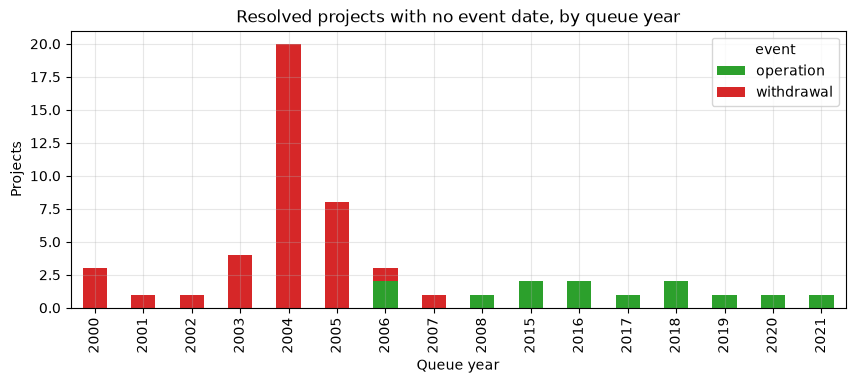

Projects whose event is dated on or before the queue date:


,project_id,cohort,outcome,queue_date,event_date,duration_days
294,98,Pre-cluster,operational,2006-03-09,2005-12-31,-68.000
426,1040,C07,operational,2014-04-30,2014-01-03,-117.000
570,101,Pre-cluster,withdrawn,2006-04-07,2006-04-07,0.000
1047,643AB,C03,withdrawn,2010-07-31,2010-07-26,-5.000


In [10]:
# Where are the missing event dates? (They are resolved projects whose duration cannot be computed.)
missing_dates = raw_table[raw_table["event_date_missing"]]
by_year = pd.crosstab(missing_dates["queue_year"], missing_dates["event"].map(sd.EVENT_LABELS))
display(by_year.T)

fig, ax = plt.subplots(figsize=(10, 3.6))
by_year.plot(kind="bar", stacked=True, ax=ax, color=["tab:green", "tab:red"][: by_year.shape[1]])
ax.set(title="Resolved projects with no event date, by queue year", xlabel="Queue year", ylabel="Projects")
plt.show()

print("Projects whose event is dated on or before the queue date:")
display(raw_table.loc[raw_table["duration_nonpositive"], ["project_id", "cohort", "outcome", "queue_date", "event_date", "duration_days"]])

**Interpretation.**
* **39 of the 52 missing event dates are withdrawals queued in 2003 to 2005**, the same early period where records are known to be thin (Section 4). They do not matter much once those years are treated as truncated.
* **The other 13 are operational projects, and 10 of them were queued in 2015 to 2021.** This matters: these are the few recent success stories, and they have no actual online date recorded. Dropping them removes about 10% of the operations in the post-2013 era, the era that the screener most resembles.
  The sensitivity analysis in Section 6.5 shows that dropping versus imputing changes the overall curves by about one point at most, but for a **model of operation in the recent regime** these 10 projects matter. Recovering their dates (for example from other CAISO or public sources) is a worthwhile follow-up.
* The four non-positive durations are individual recording errors (an online date 68 or 117 days before the queue date, a withdrawal 5 days before, and one on the same day). Each is set to one day and flagged.

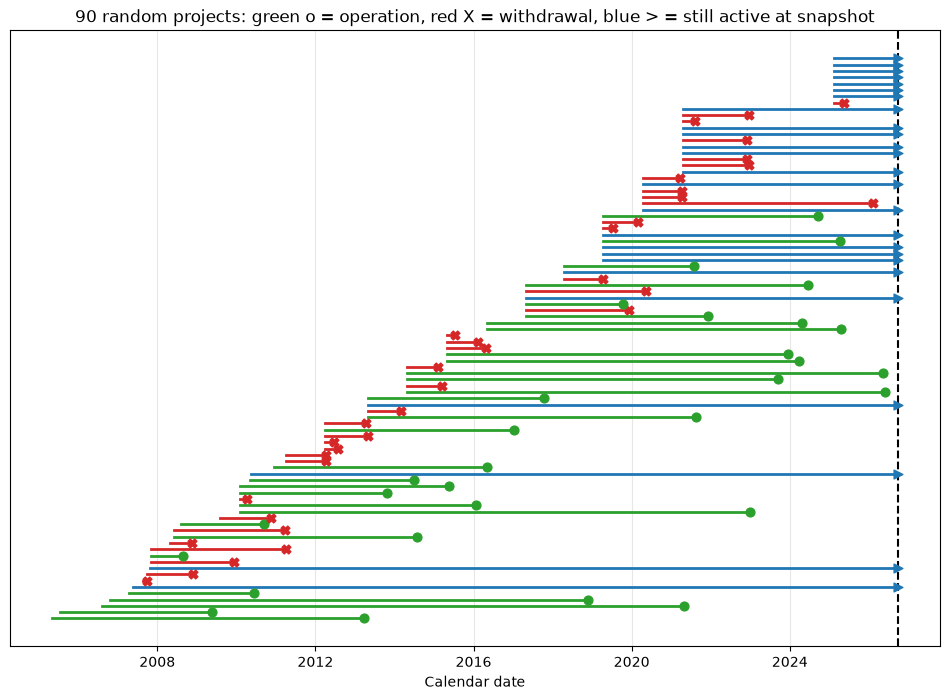

In [11]:
# Swimlane view: a random sample of 90 projects on the calendar axis (sorted by queue date).
rng = np.random.default_rng(SEED)
pick = np.concatenate([rng.choice(raw_table.index[(raw_table["event"] == ev) & ~raw_table["event_date_missing"]], n, replace=False)
                       for ev, n in [(2, 35), (1, 30), (0, 25)]])
sample = raw_table.loc[pick].sort_values("queue_date").reset_index()
fig, ax = plt.subplots(figsize=(12, 8))
for row, r in sample.iterrows():
    ax.plot([r["queue_date"], r["end_date"]], [row, row], color=EVENT_COLORS[r["event"]], lw=2)
    ax.scatter([r["end_date"]], [row], color=EVENT_COLORS[r["event"]], marker={1: "o", 2: "X", 0: ">"}[r["event"]], s=40, zorder=3)
ax.axvline(sd.C15_ASSUMED_SNAPSHOT, color="k", ls="--")
ax.set(yticks=[], xlabel="Calendar date", title="90 random projects: green o = operation, red X = withdrawal, blue > = still active at snapshot")
plt.show()

**Interpretation.**
* Red lines (withdrawals) are short, green lines (operations) are long, and blue lines (active) run all the way to the snapshot, which is the pattern the earlier hazard-based reasoning predicts.
* Projects entered in waves. Lines beginning at the same date are in the same cluster and tend to end in similar patterns, a visual preview of the dependence discussed in Section 7.
* The very oldest blue lines (queued 2003 to 2006) are projects that have been in the queue for 20 years. They are real, but they are unusual survivors from a different regime.

In [12]:
# Repairs and exclusions, with counts at every step so nothing disappears silently.
table = sd.repair_durations(raw_table)                     # non-positive durations -> 1 day (flagged)
print("Durations repaired:", int(table["duration_repaired"].sum()))
table_all = sd.resolve_missing_event_dates(table, "drop")  # main choice: drop unknown-time events (sensitivity in Section 6)
print(f"Projects before: {len(table)}; after dropping unknown event dates: {len(table_all)} "
      f"(dropped {len(table) - len(table_all)}: "
      f"{int(((table['event'] == 2) & table['event_date_missing']).sum())} withdrawals, "
      f"{int(((table['event'] == 1) & table['event_date_missing']).sum())} operations)")
print(table_all["event"].map(sd.EVENT_LABELS).value_counts().to_dict())

Durations repaired: 4
Projects before: 2448; after dropping unknown event dates: 2396 (dropped 52: 39 withdrawals, 13 operations)
{'withdrawal': 1809, 'active (censored)': 348, 'operation': 239}


**Decisions in this section.**

1. **Time origin = `queue_date`.** Alternatives: the interconnection-request receipt date (Cluster 14) or Application Date (Cluster 15).
   We choose the queue date because (a) every project in a cluster shares one queue date, which keeps the clock aligned within a cluster;
   (b) the receipt date has recording problems (165 projects have a receipt date later than their queue date, 150 of them on the withdrawn sheet); (c) it is the date the project formally entered the process the cluster rules govern. Section 6.5 tests how much
   the alternative origin changes the results.
2. **Missing event dates: drop (main), impute (sensitivity).** A project with a known outcome but no date has an *unknown* duration. Dropping
   the 52 affected projects (39 withdrawals, mostly queued 2003 to 2005, and 13 operations, 10 of them queued 2015 to 2021) is simplest.
   Section 6.5 repeats the main estimates after imputing the median duration instead. **Flag for the modeling plan:** the 10 recent operations
   are about 10% of all post-2013 operations, so recovering their online dates would help the operation model.
3. **Non-positive durations are set to 1 day** and flagged. They are a handful of recording errors; a zero or negative time would break the estimators.

## 4. Left truncation and the observation window

**Purpose.** Decide *which calendar period of the data can be trusted* and how to handle projects that entered before it.

**Why it matters.** Survival estimators assume that, at any age, the projects in the data are a fair sample of the projects that were
at risk. If early records exist only for projects that survived into the recording period, then early cohorts look unrealistically
healthy: the quick withdrawals are missing. Left truncation is the most dangerous issue in this dataset because it does not show up as a
missing value anywhere; it shows up as *absences*.

**What to look for.**
1. *Person-years at risk per calendar year*: if records were complete from the start, the amount of observed queue time should grow
   smoothly as the queue grows.
2. *Earliest recorded event*: no projects can have ended before records began.
3. *Early-life withdrawal share by queue year*: withdrawals are fast (about half happen within 18 months), so a queue year whose projects
   show far fewer quick withdrawals than later years is likely missing the quickly withdrawn projects.

**Key terms.** *Window start*: the date records begin. *Delayed entry*: counting a project in the at-risk group only from the age it had on
the window start. *Person-years at risk*: the total time all projects spent in the queue; the denominator of every hazard.

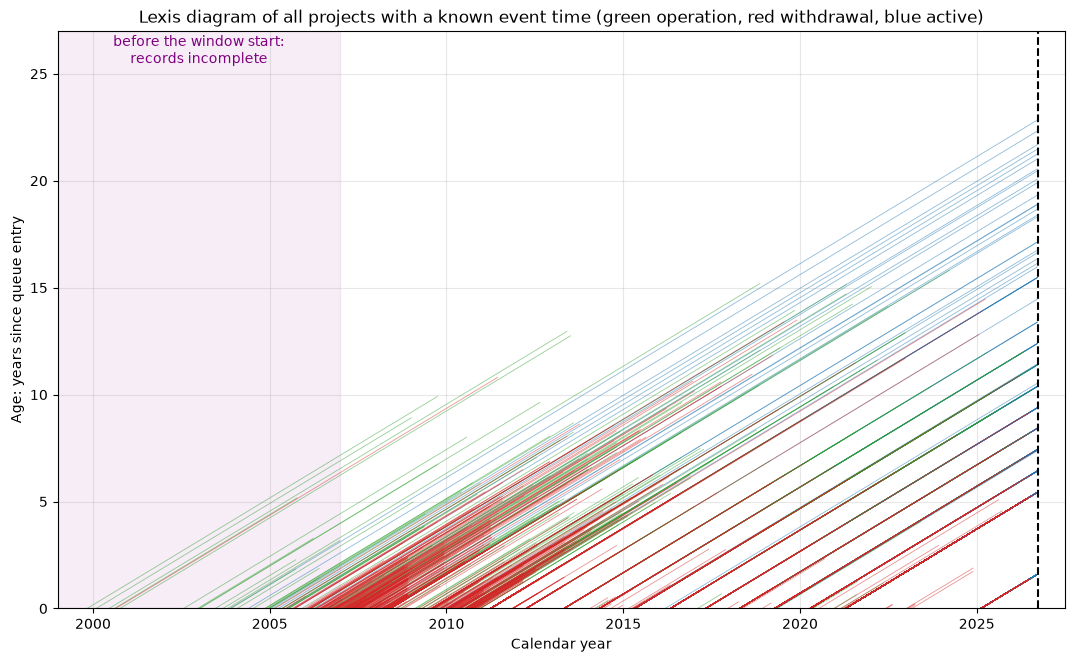

In [13]:
# Real Lexis diagram: every project is a diagonal line from (queue date, age 0) to (end date, age at end).
lex = table_all.copy()
to_year = lambda s: s.dt.year + (s.dt.dayofyear - 1) / 365.25
segments = [[(a, 0.0), (b, c)] for a, b, c in zip(to_year(lex["queue_date"]), to_year(lex["end_date"]), lex["duration_years"])]
fig, ax = plt.subplots(figsize=(13, 7.5))
ax.add_collection(LineCollection(segments, colors=[EVENT_COLORS[e] for e in lex["event"]], linewidths=0.6, alpha=0.5))
ax.axvline(to_year(pd.Series([pd.Timestamp("2026-09-24")])).iloc[0], color="k", ls="--")
ax.axvspan(1999, 2007, color="purple", alpha=0.07)
ax.text(2003, 25.5, "before the window start:\nrecords incomplete", ha="center", color="purple", fontsize=10)
ax.set(xlim=(1999, 2027.5), ylim=(0, 27), xlabel="Calendar year", ylabel="Age: years since queue entry",
       title="Lexis diagram of all projects with a known event time (green operation, red withdrawal, blue active)")
plt.show()

**Interpretation.**
* Each line is one project. The **dense red wedge from 2007 to 2013** is the early queue, where most projects withdrew within a year or two. The **blue lines reaching the dashed snapshot** are the active projects. Green lines are operations.
* The shaded region before 2007 is nearly empty: very few lines exist there, and the ones that do rise steeply from the left because they are early projects that were still alive in 2007. That emptiness is what **left truncation** looks like in real data.
* The parallel "stripes" of dense lines are clusters (many projects sharing a queue date). Because every project in a stripe is exposed to the same calendar events, projects in the same stripe are not independent.

,person_years,operations,withdrawals,withdrawals_per_person_year
calendar_year,,,,
2002,6.475,0,0,0.000
2003,11.253,0,0,0.000
2004,17.489,0,0,0.000
2005,34.229,4,0,0.000
2006,70.078,5,6,0.086
2007,165.593,0,27,0.163
2008,281.596,1,180,0.639
2009,225.098,9,37,0.164
2010,330.817,10,75,0.227


Earliest dated events in the whole file:


,project_id,cohort,outcome,queue_date,event_date
271,19,Pre-cluster,operational,2003-06-18,2005-09-30
274,23,Pre-cluster,operational,2003-11-24,2005-10-01
265,4,Pre-cluster,operational,2000-08-08,2005-10-14
294,98,Pre-cluster,operational,2006-03-09,2005-12-31
554,71,Pre-cluster,withdrawn,2005-06-15,2006-01-11


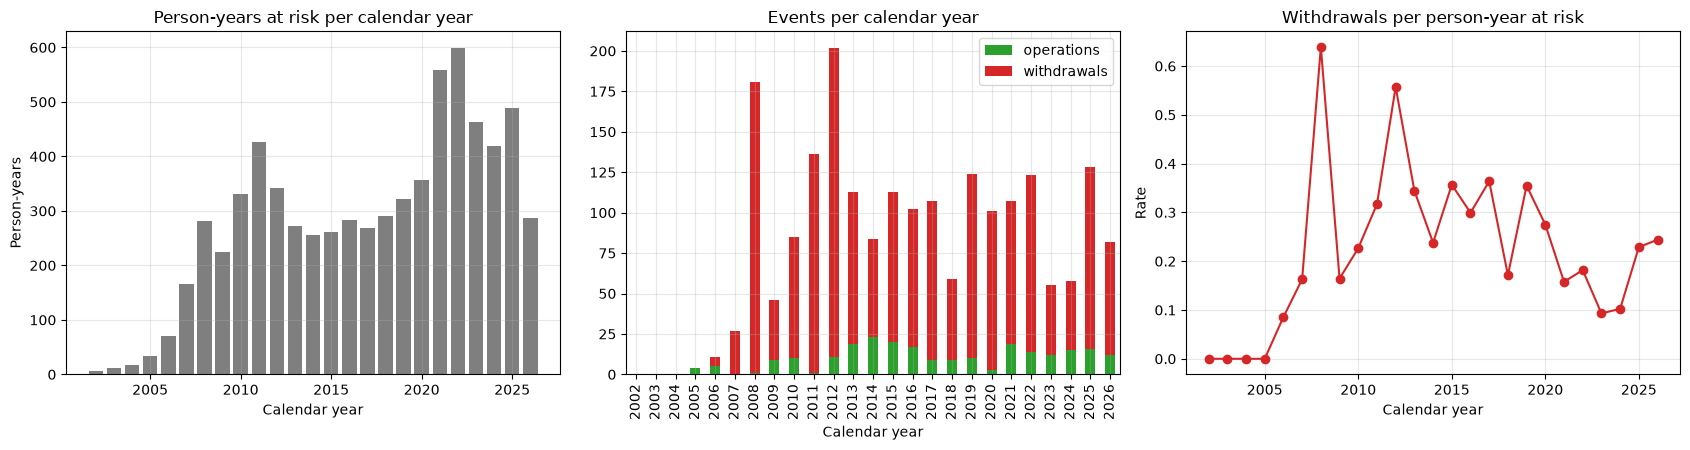

In [14]:
def calendar_exposure(tab, years):
    # Person-years at risk and event counts per calendar year.
    rows = []
    for year in years:
        lo, hi = pd.Timestamp(f"{year}-01-01"), pd.Timestamp(f"{year + 1}-01-01")
        start, end = tab["queue_date"].clip(lower=lo), tab["end_date"].clip(upper=hi)
        person_years = ((end - start).dt.days.clip(lower=0)).sum() / sd.DAYS_PER_YEAR
        ended = tab[(tab["event"] > 0) & (tab["end_date"] >= lo) & (tab["end_date"] < hi)]
        rows.append({"calendar_year": year, "person_years": person_years, "operations": int((ended["event"] == 1).sum()),
                     "withdrawals": int((ended["event"] == 2).sum())})
    out = pd.DataFrame(rows).set_index("calendar_year")
    out["withdrawals_per_person_year"] = out["withdrawals"] / out["person_years"]
    return out


cal = calendar_exposure(table_all, range(2002, 2027))
display(cal.loc[2002:2012])

first_events = table_all.groupby("queue_year").agg(projects=("event", "size"), first_event=("event_date", "min"))
print("Earliest dated events in the whole file:")
display(table_all.loc[table_all["event_date"].nsmallest(5).index, ["project_id", "cohort", "outcome", "queue_date", "event_date"]])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].bar(cal.index, cal["person_years"], color="tab:gray")
axes[0].set(title="Person-years at risk per calendar year", xlabel="Calendar year", ylabel="Person-years")
cal[["operations", "withdrawals"]].plot(kind="bar", stacked=True, ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set(title="Events per calendar year", xlabel="Calendar year")
axes[2].plot(cal.index, cal["withdrawals_per_person_year"], marker="o", color="tab:red")
axes[2].set(title="Withdrawals per person-year at risk", xlabel="Calendar year", ylabel="Rate")
plt.tight_layout(); plt.show()

**Interpretation.**
* **Observed time grows from almost nothing to usable levels between 2005 and 2008:** 6 person-years in 2002, 34 in 2005, 70 in 2006, 166 in 2007, and 282 in 2008. A real queue with hundreds of projects would produce far more time than that in 2002 to 2006, so the early records are **incomplete**.
* **No withdrawal at all is recorded before 2006**, and only 6 in 2006, even though withdrawals are the most common outcome (about 1,800 across the file). Operations appear from late 2005 (earliest actual online date: 2005-09-30).
* The withdrawal rate per person-year jumps in 2008 (0.64, driven by a mass withdrawal in November 2008) and then ranges between about 0.16 and 0.56 through 2012. So **the dataset effectively begins in 2006 to 2007**.
* This is the evidence for a **window start of 2007-01-01**: before that date, the data are a record of survivors, not of the queue.

queue_year,1999,2000,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012
projects,1.000,5.000,2.000,7.000,9.000,22.000,76.000,133.000,180.000,66.000,212.000,207.000,66.000
withdrew_within_18_months,0.000,0.000,0.000,0.000,0.000,0.045,0.184,0.444,0.650,0.409,0.476,0.725,0.773


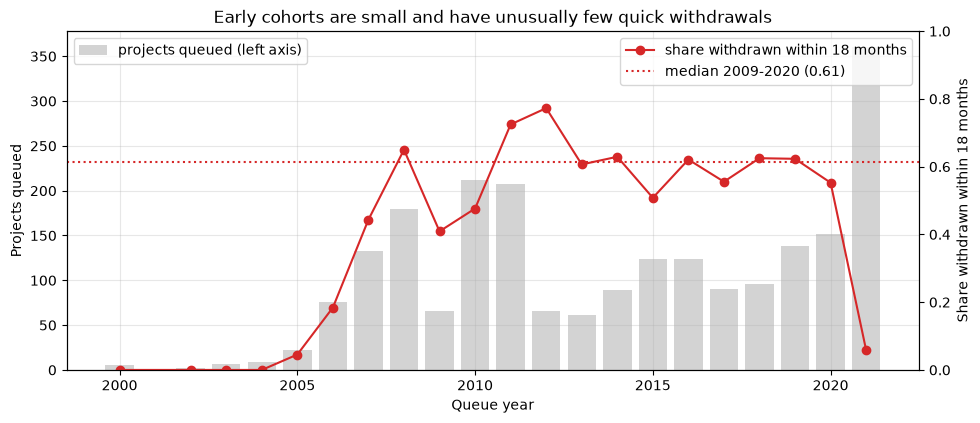

In [15]:
# Early-life withdrawal share by queue year: of the projects queued that year, what fraction withdrew within 18 months?
by_queue_year = table_all.groupby("queue_year").agg(projects=("event", "size"))
by_queue_year["withdrew_within_18_months"] = table_all.assign(w=lambda d: (d["event"] == 2) & (d["duration_years"] <= 1.5)) \
    .groupby("queue_year")["w"].mean()
modern = by_queue_year.loc[2009:2020, "withdrew_within_18_months"]
display(by_queue_year.loc[1999:2012].T)

fig, ax1 = plt.subplots(figsize=(11, 4.4))
sub = by_queue_year.loc[2000:2021]
ax1.bar(sub.index, sub["projects"], color="lightgray", label="projects queued (left axis)")
ax2 = ax1.twinx()
ax2.plot(sub.index, sub["withdrew_within_18_months"], marker="o", color="tab:red", label="share withdrawn within 18 months")
ax2.axhline(modern.median(), color="tab:red", ls=":", label=f"median 2009-2020 ({modern.median():.2f})")
ax2.grid(False)
ax1.set(xlabel="Queue year", ylabel="Projects queued"); ax2.set(ylabel="Share withdrawn within 18 months", ylim=(0, 1))
ax1.legend(loc="upper left"); ax2.legend(loc="upper right")
ax1.set_title("Early cohorts are small and have unusually few quick withdrawals")
plt.show()

**Interpretation.**
* Queue years 1999 to 2004 have between 1 and 9 projects each and **none of them withdrew within 18 months**. That cannot be the true behavior of the queue; withdrawals within 18 months are 41% to 77% of every queue year from 2007 through 2012. Quick withdrawals from those years were simply never recorded.
* 2005 (4.5%) and 2006 (18%) are partially truncated. **For 2007 the share (44%) is within the normal range** (41% to 77% for 2007 to 2012), though the variation from year to year is large, which is real and cluster-driven (Section 7).
* So the cutoff at **2007-01-01** is consistent with both the person-year evidence and this cohort-level evidence.

**Candidate ways to handle the early period.** We compare five options and see how much each changes the answers:

* **A. Ignore truncation:** keep everything, every project enters at age 0 (the naive treatment).
* **B. Delayed entry from 2006-01-01** and **C. delayed entry from 2007-01-01:** keep older projects but count them as at risk only from the
  age they had on that date; projects that ended before the window start are dropped (they should not be in the data at all).
* **D. Restrict to projects queued on or after 2007-01-01** and **E. restrict to 2008-01-01 or later:** simplest and safest, but
  discards the older projects (including some of the few operational successes).

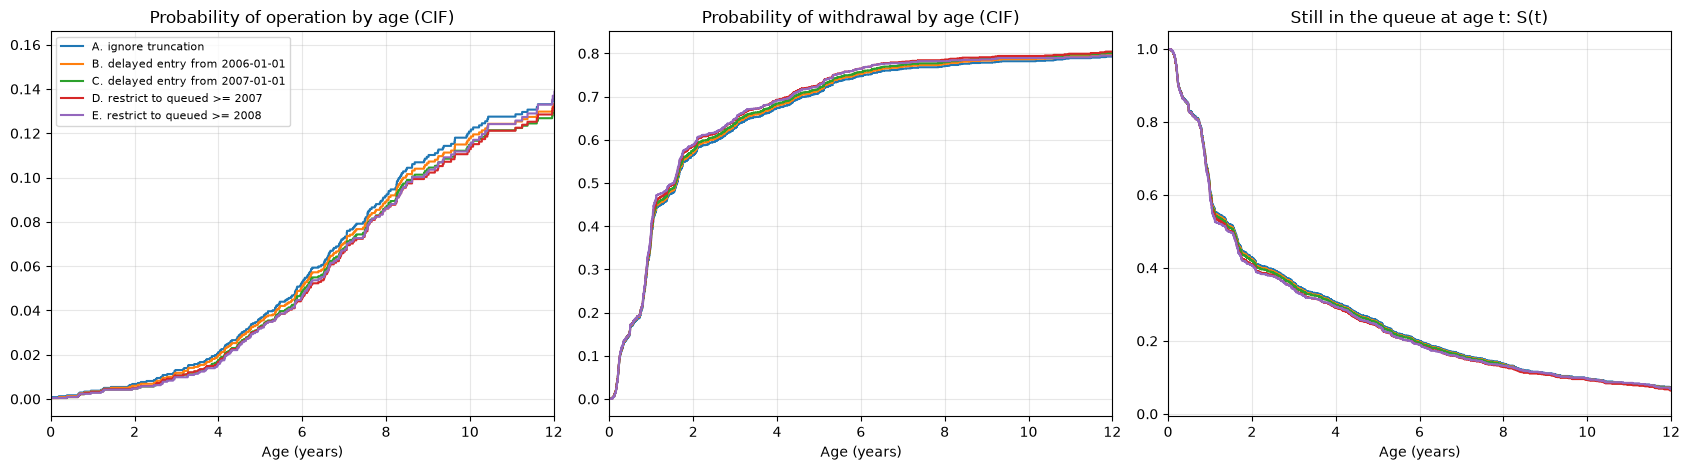

,projects,operations,withdrawals,CIF_op@1y,CIF_wd@1y,CIF_op@3y,CIF_wd@3y,CIF_op@5y,CIF_wd@5y,CIF_op@10y,CIF_wd@10y
option,,,,,,,,,,,
A. ignore truncation,2396,239,1809,0.004,0.382,0.013,0.627,0.036,0.709,0.121,0.782
B. delayed entry from 2006-01-01,2392,235,1809,0.003,0.387,0.012,0.633,0.035,0.715,0.118,0.787
C. delayed entry from 2007-01-01,2381,230,1803,0.003,0.391,0.011,0.638,0.033,0.719,0.115,0.791
D. restrict to queued >= 2007,2274,197,1739,0.003,0.397,0.011,0.647,0.032,0.728,0.113,0.794
E. restrict to queued >= 2008,2141,182,1624,0.003,0.404,0.010,0.649,0.032,0.726,0.114,0.789


In [16]:
options = {
    "A. ignore truncation": sd.apply_window(table_all, None, "none"),
    "B. delayed entry from 2006-01-01": sd.apply_window(table_all, pd.Timestamp("2006-01-01"), "delayed_entry"),
    "C. delayed entry from 2007-01-01": sd.apply_window(table_all, pd.Timestamp("2007-01-01"), "delayed_entry"),
    "D. restrict to queued >= 2007": sd.apply_window(table_all, pd.Timestamp("2007-01-01"), "restrict"),
    "E. restrict to queued >= 2008": sd.apply_window(table_all, pd.Timestamp("2008-01-01"), "restrict"),
}
ages = np.linspace(0, 12, 241)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
rows = []
for name, tab in options.items():
    d, e, ent = tab["duration_years"].values, tab["event"].values, tab["entry_years"].values
    cif_op, cif_wd = sd.aj_cif(d, e, 1, ent), sd.aj_cif(d, e, 2, ent)
    axes[0].step(cif_op.index, cif_op["cif"], where="post", label=name)
    axes[1].step(cif_wd.index, cif_wd["cif"], where="post", label=name)
    axes[2].step(cif_op.index, cif_op["survival_any"], where="post", label=name)
    row = {"option": name, "projects": len(tab), "operations": int((e == 1).sum()), "withdrawals": int((e == 2).sum())}
    for h in [1, 3, 5, 10]:
        row[f"CIF_op@{h}y"] = sd.cif_at(d, e, 1, h, ent)[0]
        row[f"CIF_wd@{h}y"] = sd.cif_at(d, e, 2, h, ent)[0]
    rows.append(row)
axes[0].set(title="Probability of operation by age (CIF)", xlabel="Age (years)", xlim=(0, 12))
axes[1].set(title="Probability of withdrawal by age (CIF)", xlabel="Age (years)", xlim=(0, 12))
axes[2].set(title="Still in the queue at age t: S(t)", xlabel="Age (years)", xlim=(0, 12))
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
window_effects = pd.DataFrame(rows).set_index("option")
display(window_effects)

**Interpretation.**
* **The curves are close under all five options.** The probability of withdrawal by one year moves between 0.382 (ignore truncation) and 0.404 (restrict to 2008 or later), and the probability of operation by year 10 moves between 0.113 and 0.121. In other words, truncation is real but **its measurable effect on the aggregate curves is about one percentage point**.
* The direction is as expected: ignoring truncation gives the lowest early withdrawal probability (the missing quick withdrawals) and the highest long-run operation probability (the survivors).
* Because the effect is small on average, the choice is **driven by principle rather than outcome**: delayed entry from 2007 is the only option that is both correct about when records began and keeps the older operations. A model with a feature that interacts with era could still be affected more than these averages suggest.

**Decision: observation window.** We use **option C: delayed entry from 2007-01-01**. The evidence is in the three figures above: events
before 2007 are almost absent, observed time before 2007 is tiny, and the 2005-2006 queue cohorts have far fewer quick withdrawals than
every cohort from 2007 on. The first full year of credible event density is 2007. Delayed entry (not restriction) is chosen because it
keeps the 2000-2006 projects that were still alive in 2007, which include a meaningful share of all operational projects, while counting
them at risk only from their age on 2007-01-01. Option D (restrict) is kept as the robustness check in Section 6.5.

This is a **modeling assumption**, not a fact: it assumes every project alive on 2007-01-01 was recorded. If that is false, early ages for the
oldest cohorts remain slightly biased. The estimators we will use in the modeling plan must support delayed entry (Cox models do; some
machine-learning survival models do not), which is a real constraint on model choice.

In [17]:
WINDOW_START = pd.Timestamp("2007-01-01")
surv = sd.apply_window(table_all, WINDOW_START, "delayed_entry")
sd.assert_survival_table(surv)
print(f"Window start {WINDOW_START.date()}: {len(table_all)} -> {len(surv)} projects "
      f"({len(table_all) - len(surv)} dropped because they ended before the window start).")

# Attach queue-entry features and groupings used in all later sections.
features = sd.engineer_survival_features(projects)
ERA_BINS = [0, 2008, 2012, 2016, 2023, 2100]
ERA_LABELS = ["queued <=2008", "2009-2012", "2013-2016", "2017-2023", "2025 (Cluster 15)"]
analysis = surv.join(features)
analysis["era"] = pd.cut(analysis["queue_year"], ERA_BINS, labels=ERA_LABELS)
analysis["tech_group"] = analysis["fuel_1"].where(analysis["fuel_1"].isin(["Solar", "Battery", "Natural Gas", "Wind Turbine"]), "Other")

print(analysis.groupby("era")["event"].value_counts().unstack(fill_value=0).rename(columns=sd.EVENT_LABELS))
print("analysis table:", analysis.shape)

Window start 2007-01-01: 2396 -> 2381 projects (15 dropped because they ended before the window start).
event              active (censored)  operation  withdrawal
era                                                        
queued <=2008                     16         64         340
2009-2012                         13         72         466
2013-2016                         31         61         306
2017-2023                        202         33         607
2025 (Cluster 15)                 86          0          84
analysis table: (2381, 40)


## 5. Follow-up and censoring diagnostics

**Purpose.** Measure how long each cohort has actually been observed, and check that censoring is the benign (administrative) kind.

**Why it matters.** A cohort can only show an event that is *possible within its follow-up*. If operation typically takes about 6 years, a
cohort with 3 years of follow-up has almost no operations by construction, not because projects fail. Survival methods handle that, but
only if the censoring is **non-informative**: the reason a project is censored must not be related to its prospects. Administrative
censoring (cut off at the snapshot) satisfies that.

**Key terms.**
* *Potential follow-up*: the longest a project could be observed (snapshot minus queue date).
* *Reverse Kaplan-Meier*: the Kaplan-Meier estimator with the roles swapped (censoring is the "event"), the standard way to summarize
  median follow-up without being fooled by early events.
* *Number at risk*: how many projects are still under observation at a given age; when it is small, estimates at that age are unreliable.

All 348 active projects are censored exactly at the snapshot date (administrative censoring).


,projects,active_share,median_potential_followup_years,reverse_KM_median_followup,share_with_5y_potential_followup
era,,,,,
queued <=2008,420,0.038,18.958,20.090,1.000
2009-2012,551,0.024,15.775,15.986,1.000
2013-2016,398,0.078,11.403,11.403,1.000
2017-2023,842,0.240,6.442,6.442,0.993
2025 (Cluster 15),170,0.506,1.613,1.613,0.000


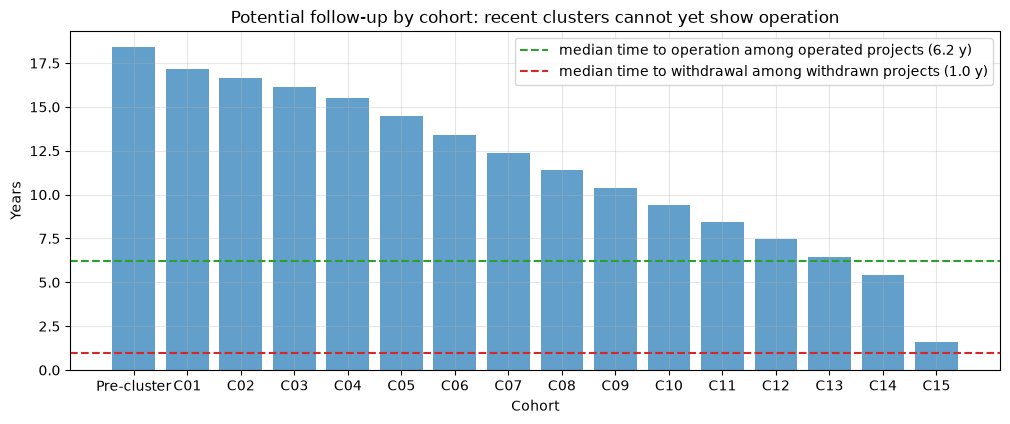

In [18]:
# 1. Censoring is administrative: every active project is observed exactly until the snapshot.
active = analysis[analysis["event"] == 0]
assert (active["end_date"] == active["snapshot_date"]).all()
assert np.allclose(active["duration_days"], (active["snapshot_date"] - active["queue_date"]).dt.days)
print(f"All {len(active)} active projects are censored exactly at the snapshot date (administrative censoring).")

# 2. Potential follow-up and reverse-KM median follow-up by era.
analysis["potential_followup_years"] = (analysis["snapshot_date"] - analysis["queue_date"]).dt.days / sd.DAYS_PER_YEAR
rows = []
for era, grp in analysis.groupby("era"):
    rev = sd.km_survival(grp["duration_years"].values, (grp["event"] == 0).astype(int).values, grp["entry_years"].values)
    median = rev.index[rev["survival"] <= 0.5][0] if (rev["survival"] <= 0.5).any() else np.nan
    rows.append({"era": era, "projects": len(grp), "active_share": (grp["event"] == 0).mean(),
                 "median_potential_followup_years": grp["potential_followup_years"].median(),
                 "reverse_KM_median_followup": median,
                 "share_with_5y_potential_followup": (grp["potential_followup_years"] >= 5).mean()})
followup = pd.DataFrame(rows).set_index("era")
display(followup)

# 3. Potential follow-up by cohort versus the typical time to each outcome.
median_op = analysis.loc[analysis["event"] == 1, "duration_years"].median()
median_wd = analysis.loc[analysis["event"] == 2, "duration_years"].median()
cohort_order = ["Pre-cluster"] + [f"C{i:02d}" for i in range(1, 16)]
fu = analysis.groupby("cohort")["potential_followup_years"].median().reindex(cohort_order)
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.bar(fu.index, fu.values, color="tab:blue", alpha=0.7)
ax.axhline(median_op, color="tab:green", ls="--", label=f"median time to operation among operated projects ({median_op:.1f} y)")
ax.axhline(median_wd, color="tab:red", ls="--", label=f"median time to withdrawal among withdrawn projects ({median_wd:.1f} y)")
ax.set(title="Potential follow-up by cohort: recent clusters cannot yet show operation", ylabel="Years", xlabel="Cohort")
ax.legend()
plt.show()

**Interpretation.**
* **All 348 active projects are censored exactly at the snapshot:** censoring is administrative. Nothing about a project's prospects decides whether it is censored; only its queue date does. This is the best case for standard survival methods.
* Follow-up differs a lot by era. Projects queued 2008 or earlier have a median potential follow-up of 19 years (4% still active); **2017 to 2023 has 6.4 years (24% active); Cluster 15 has 1.6 years (51% active)**.
* The bar chart makes the central modeling issue visible: only cohorts older than about Cluster 8 have had long enough to show the typical time to operation (dashed green, about 6 years). **Recent cohorts cannot yet have operated**, so for those cohorts "operation" is mostly unobservable, not unlikely.
* The reverse Kaplan-Meier median equals the potential follow-up for recent eras, confirming that censoring is determined by queue date alone.

In [19]:
# Number at risk by age and era (projects still under observation at that age).
ages_at_risk = [0.25, 1, 2, 3, 5, 8, 10, 15]
risk = {}
for era, grp in analysis.groupby("era"):
    risk[era] = [int(((grp["entry_years"] < a) & (grp["duration_years"] >= a)).sum()) for a in ages_at_risk]
risk_table = pd.DataFrame(risk, index=[f"age >= {a}y" for a in ages_at_risk]).T
display(risk_table)

# Events per age band, by cause.
bands = [0, 0.5, 1, 2, 3, 5, 8, 12, 25]
band_rows = []
for lo, hi in zip(bands[:-1], bands[1:]):
    inside = analysis[(analysis["duration_years"] > lo) & (analysis["duration_years"] <= hi)]
    band_rows.append({"age_band": f"{lo}-{hi}y", "operations": int((inside["event"] == 1).sum()),
                      "withdrawals": int((inside["event"] == 2).sum()), "censored": int((inside["event"] == 0).sum())})
display(pd.DataFrame(band_rows).set_index("age_band").T)

,age >= 0.25y,age >= 1y,age >= 2y,age >= 3y,age >= 5y,age >= 8y,age >= 10y,age >= 15y
queued <=2008,300,223,191,145,105,57,38,20
2009-2012,509,343,192,145,89,29,24,12
2013-2016,333,181,151,123,95,64,43,0
2017-2023,771,571,397,373,270,37,0,0
2025 (Cluster 15),155,108,0,0,0,0,0,0


age_band,0-0.5y,0.5-1y,1-2y,2-3y,3-5y,5-8y,8-12y,12-25y
operations,2,5,4,13,50,90,50,16
withdrawals,395,515,426,139,182,116,25,5
censored,0,0,86,0,0,171,53,38


**Interpretation.**
* The number at risk tells us **where curves can be trusted**. For 2017 to 2023 projects, 270 are still observed at age 5 but only 37 at age 8 and none at age 10. For Cluster 15, 108 projects are observed at age 1 and none at age 2.
* The age bands show the competing-risks structure in counts: **withdrawals dominate before year 3 (1,475 of the 1,803)** and **operations dominate after year 3** (206 of 230 operations occur after year 3; only 11 before year 2).
* All 86 censored projects in the 1 to 2 year band are Cluster 15. So any claim about Cluster 15 beyond about 1.6 years is an extrapolation.
* Rule used in this notebook: curves are drawn only where at least 20 projects are at risk.

In [20]:
# Is the group of still-active projects unusual within its own cluster? (Compare active vs resolved within each cluster.)
rows = []
for cohort, grp in analysis.groupby("cohort"):
    act, res = grp[grp["event"] == 0], grp[grp["event"] > 0]
    if len(act) >= 10 and len(res) >= 10:
        rows.append({"cohort": cohort, "active": len(act), "resolved": len(res),
                     "storage_share_active": act["has_storage"].mean(), "storage_share_resolved": res["has_storage"].mean(),
                     "mean_log_mw_active": act["log_net_mw"].mean(), "mean_log_mw_resolved": res["log_net_mw"].mean(),
                     "median_kv_active": act["poi_kv"].median(), "median_kv_resolved": res["poi_kv"].median()})
display(pd.DataFrame(rows).set_index("cohort"))

,active,resolved,storage_share_active,storage_share_resolved,mean_log_mw_active,mean_log_mw_resolved,median_kv_active,median_kv_resolved
cohort,,,,,,,,
C09,11,112,0.818,0.366,4.801,4.786,230.000,230.000
C10,14,74,0.857,0.527,4.967,4.611,230.000,230.000
C11,17,75,0.882,0.773,4.685,5.080,230.000,230.000
C12,30,105,0.933,0.895,5.666,5.223,230.000,230.000
C13,36,110,0.861,0.927,5.375,5.197,230.000,230.000
C14,104,255,0.990,0.957,5.566,5.268,230.000,230.000
C15,86,84,0.756,0.929,5.568,5.518,230.000,230.000
Pre-cluster,22,589,0.909,0.037,4.469,4.391,179.000,115.000


**Interpretation.**
* Within each recent cluster, **active projects are larger and more often storage than the resolved ones** (for example Cluster 9: 82% storage among active projects versus 37% among resolved; Cluster 10: 86% versus 53%).
* That is not a sign of informative censoring. Censoring here is purely administrative (every active project is cut at the snapshot). The difference arises because **larger, storage-heavy projects leave the queue more slowly**, so they are over-represented among the survivors. This is consistent with the hazard ratios in Section 9 and is exactly what a survival model is built to handle.
* It does mean that a method that looked only at *resolved* projects would learn a skewed picture: the resolved projects are the smaller, faster-leaving ones. This is the same selection effect that makes the binary classifier's "drop unresolved" shortcut risky.

# Part B: Descriptive survival analysis

## 6. Nonparametric curves: what the data say before any model

**Purpose.** Estimate, with no model and no assumptions about the shape of the curves, how long projects stay in the queue, how likely
each outcome is by each age, and how the rate of each outcome changes with age.

**Why it matters.** These curves are the "ground truth" a later model has to reproduce. They also show whether the competing-risks
structure is real (is withdrawal really so much faster than operation?) and whether there is enough signal at the ages that matter.

**Key terms.**
* *Kaplan-Meier (KM)*: the standard estimator of S(t), the probability of being event-free at age t.
* *Aalen-Johansen (AJ) CIF*: the correct estimate of "probability of outcome k by age t" with competing outcomes (Section 0).
* *Piecewise (life-table) hazard*: events per person-year of exposure within an age band. Reads like a per-year churn rate.
* *Number at risk*: projects still under observation; curves are only plotted where at least 20 are at risk.

All estimates in Sections 6 to 8 use the **main analysis table** (delayed entry from 2007-01-01; 2,381 projects including Cluster 15).

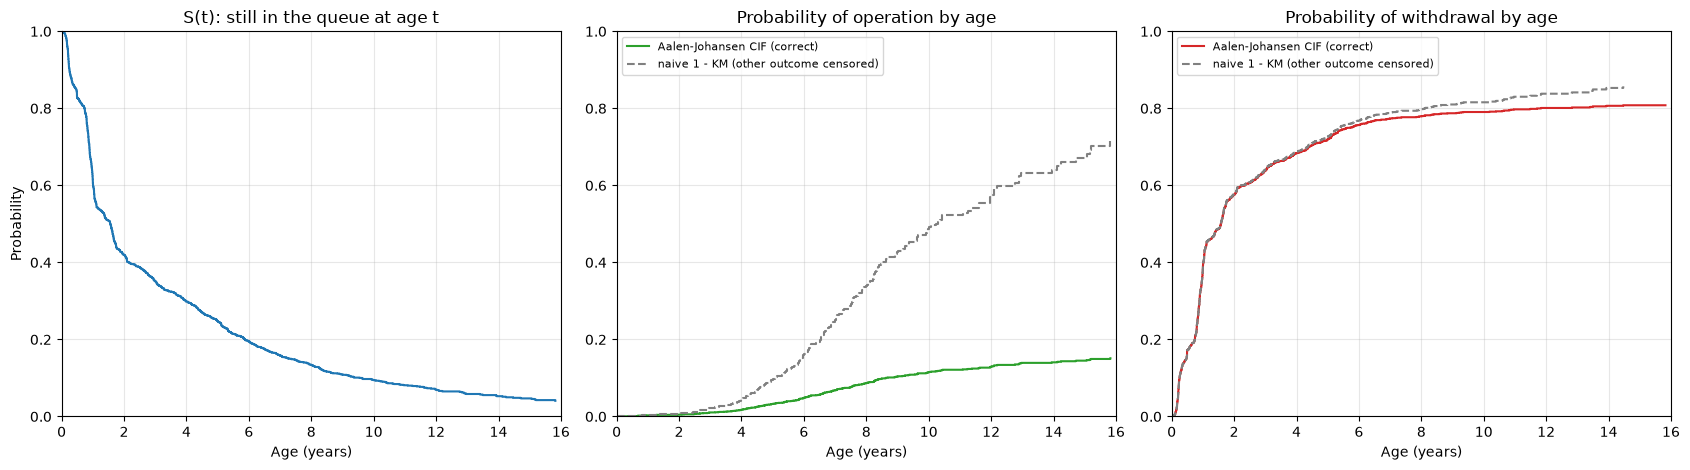

estimate  ci_lower  ci_upper  naive_1_minus_KM  at_risk
cause      age_years                                                         
operation  1.000         0.003     0.001     0.006             0.004     1426
           2.000         0.005     0.003     0.008             0.007      931
           3.000         0.011     0.007     0.015             0.022      786
           5.000         0.033     0.026     0.040             0.096      559
           8.000         0.087     0.074     0.101             0.339      187
           10.000        0.115     0.102     0.131             0.486      105
withdrawal 1.000         0.391     0.372     0.410             0.392     1426
           2.000         0.576     0.555     0.594             0.577      931
           3.000         0.638     0.618     0.659             0.641      786
           5.000         0.719     0.702     0.737             0.726      559
           8.000         0.779     0.764     0.794             0.797      187
           10.000        0.791     0.774     0.807             0.816      105

S(t) at horizons: {1: 0.606, 2: 0.42, 3: 0.351, 5: 0.248, 8: 0.134, 10: 0.095}
Median time in queue (S(t) = 0.5): 1.56 years


In [21]:
MIN_RISK = 20  # curves are trimmed where fewer than this many projects remain under observation


def arrs(tab):
    # (duration, event, entry) arrays for a survival table.
    return tab["duration_years"].to_numpy(), tab["event"].to_numpy(), tab["entry_years"].to_numpy()


def at_risk_at(tab, age):
    d, e, ent = arrs(tab)
    return int(((ent < age) & (d >= age)).sum())


def trimmed_curve(tab, cause, min_risk=MIN_RISK):
    # AJ CIF of `cause`, trimmed to the ages where at least `min_risk` projects are at risk.
    curve = sd.aj_cif(*arrs(tab)[:2], cause, arrs(tab)[2])
    keep = curve["n_risk"].fillna(np.inf) >= min_risk
    return curve[keep]


def cif_summary(tab, cause, ages, min_risk=MIN_RISK):
    # CIF at each age; NaN when fewer than `min_risk` projects are at risk at that age.
    values = sd.cif_at(*arrs(tab)[:2], cause, ages, arrs(tab)[2])
    return [v if at_risk_at(tab, a) >= min_risk else np.nan for v, a in zip(values, ages)]


d_all, e_all, ent_all = arrs(analysis)

# --- 6.1 Overall: time in the queue and the two outcome curves.
km_any = sd.km_survival(d_all, (e_all > 0).astype(int), ent_all)
cif_op, cif_wd = sd.aj_cif(d_all, e_all, 1, ent_all), sd.aj_cif(d_all, e_all, 2, ent_all)
naive_op = 1 - sd.km_survival(d_all, (e_all == 1).astype(int), ent_all)["survival"]
naive_wd = 1 - sd.km_survival(d_all, (e_all == 2).astype(int), ent_all)["survival"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
trim = lambda c: c[c["n_risk"].fillna(np.inf) >= MIN_RISK]
axes[0].step(km_any.index, km_any["survival"], where="post", color="tab:blue")
axes[0].set(title="S(t): still in the queue at age t", xlabel="Age (years)", ylabel="Probability", xlim=(0, 16), ylim=(0, 1))
for ax, cif, naive, name, color in [(axes[1], cif_op, naive_op, "operation", "tab:green"), (axes[2], cif_wd, naive_wd, "withdrawal", "tab:red")]:
    c = trim(cif)
    ax.step(c.index, c["cif"], where="post", color=color, label="Aalen-Johansen CIF (correct)")
    ax.step(naive.index, naive.values, where="post", color="gray", ls="--", label="naive 1 - KM (other outcome censored)")
    ax.set(title=f"Probability of {name} by age", xlabel="Age (years)", xlim=(0, 16), ylim=(0, 1)); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

# Horizon summary with bootstrap intervals (projects resampled independently: intervals are optimistic because
# projects within one cluster are correlated).
rows = []
for cause, name in [(1, "operation"), (2, "withdrawal")]:
    ci = sd.bootstrap_cif_at(d_all, e_all, cause, HORIZONS, ent_all, n_boot=300, seed=SEED)
    naive = (naive_op if cause == 1 else naive_wd)
    ci["cause"] = name
    ci["naive_1_minus_KM"] = [sd.step_value(naive, h)[0] for h in HORIZONS]
    ci["at_risk"] = [at_risk_at(analysis, h) for h in HORIZONS]
    rows.append(ci)
horizon_table = pd.concat(rows).set_index(["cause", "age_years"])
display(horizon_table)
print("S(t) at horizons:", {h: round(float(sd.step_value(km_any['survival'], h)[0]), 3) for h in HORIZONS})
print("Median time in queue (S(t) = 0.5):", km_any.index[km_any["survival"] <= 0.5][0].round(2), "years")

**Interpretation.**
* **Time in the queue is short for most projects:** the median project leaves (by any route) after **1.56 years**; 61% remain at 1 year, 35% at 3 years, 25% at 5 years, and 9.5% at 10 years.
* **Withdrawal:** 39% of projects have withdrawn by age 1 (95% interval about 37% to 41%), 64% by age 3, 72% by age 5, and 79% by age 10.
* **Operation:** 0.3% by age 1, 1.1% by age 3, **3.3% by age 5, 8.7% by age 8, and 11.5% by age 10**. Operation is rare and late, with essentially no operations before year 3.
* **The naive curves are wrong exactly where it matters.** The naive operation curve reads 34% at 8 years versus the correct 8.7%, and 49% at 10 years versus 11.5%. For withdrawal, the two curves are almost the same, because operation is too rare to disturb it. This asymmetry (the naive estimate is badly wrong for the rare outcome and almost right for the common one) is typical of competing risks.
* Intervals from the bootstrap are narrow, but they treat projects as independent. With clusters sharing shocks the true uncertainty is larger.

,person_years,events_op,hazard_per_year_op,events_wd,hazard_per_year_wd
band,,,,,
0.0-0.5y,1056.715,2,0.002,395,0.374
0.5-1.0y,890.983,5,0.006,515,0.578
1.0-2.0y,1147.529,4,0.003,426,0.371
2.0-3.0y,858.141,13,0.015,139,0.162
3.0-5.0y,1339.965,50,0.037,182,0.136
5.0-8.0y,947.248,90,0.095,116,0.122
8.0-12.0y,433.949,50,0.115,25,0.058
12.0-25.0y,225.292,16,0.071,5,0.022


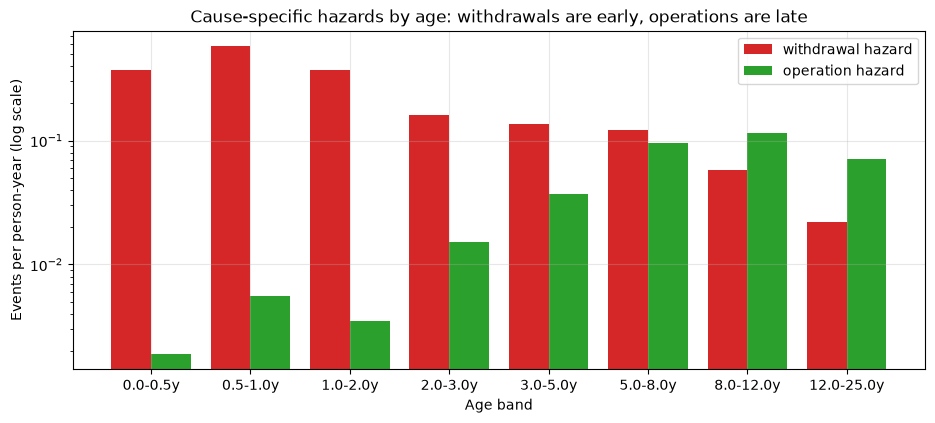

In [22]:
# --- 6.2 Cause-specific hazards by age band (events per person-year at risk).
BANDS = [0, 0.5, 1, 2, 3, 5, 8, 12, 25]
haz_op = sd.piecewise_hazard(d_all, e_all, 1, BANDS, ent_all)
haz_wd = sd.piecewise_hazard(d_all, e_all, 2, BANDS, ent_all)
haz = haz_op.merge(haz_wd, on=["age_from", "age_to", "person_years"], suffixes=("_op", "_wd"))
haz["band"] = haz["age_from"].astype(str) + "-" + haz["age_to"].astype(str) + "y"
display(haz[["band", "person_years", "events_op", "hazard_per_year_op", "events_wd", "hazard_per_year_wd"]].set_index("band"))

x = np.arange(len(haz))
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(x - 0.2, haz["hazard_per_year_wd"], 0.4, color="tab:red", label="withdrawal hazard")
ax.bar(x + 0.2, haz["hazard_per_year_op"], 0.4, color="tab:green", label="operation hazard")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(haz["band"])
ax.set(xlabel="Age band", ylabel="Events per person-year (log scale)", title="Cause-specific hazards by age: withdrawals are early, operations are late")
ax.legend(); plt.show()

**Interpretation.**
* **The withdrawal hazard is highest in the first two years (0.37 to 0.58 per project-year)**, then falls: 0.16 in years 2 to 3, 0.14 in years 3 to 5, 0.12 in years 5 to 8, and 0.06 after year 8. Of projects still in the queue, roughly a third to a half leave through withdrawal every year early on.
* **The operation hazard goes the other way:** under 0.01 per year before year 2, 0.04 in years 3 to 5, 0.10 in years 5 to 8, and **0.115 in years 8 to 12**. A project that survives to 8 years faces a much higher yearly chance of operating than one in its first year.
* The hazards are **not monotone and not smooth**; the early withdrawal hazard rises from 0.37 in the first half-year to 0.58 in the second half, then drops. This argues against a single parametric (Weibull) shape.
* The probability of operation by year 5 (3.3%) is low *because* so many projects withdraw before they could reach the operation hazard, which is the CIF/hazard relationship from Section 0.
* **Implication for the screener:** a project's risk depends on its age. A model that ignores age (the binary classifier) cannot tell a 6-month-old project from an 8-year-old one with the same features.

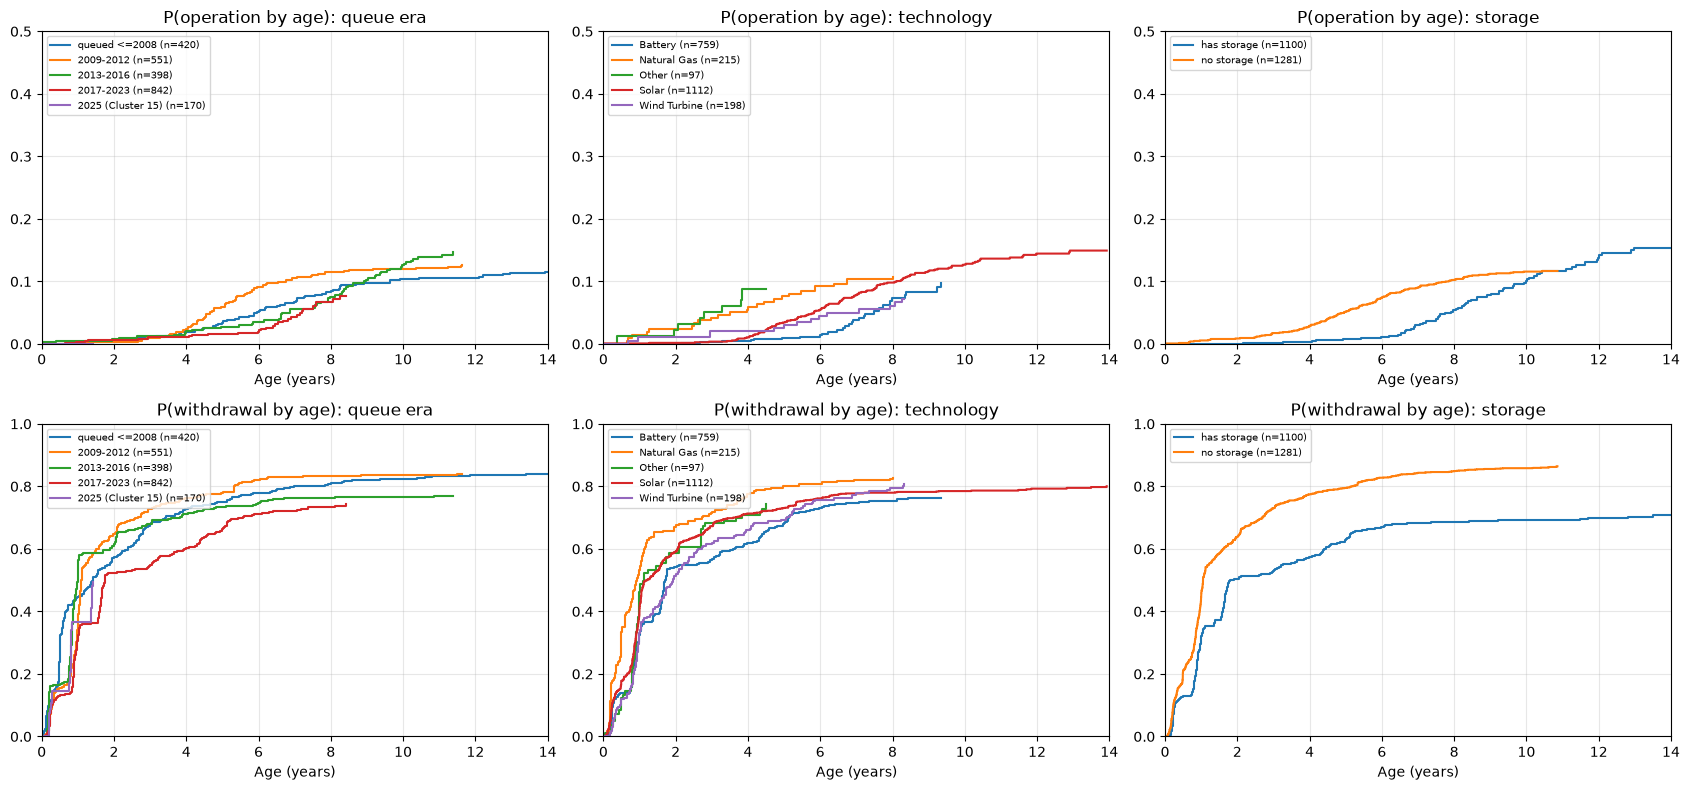

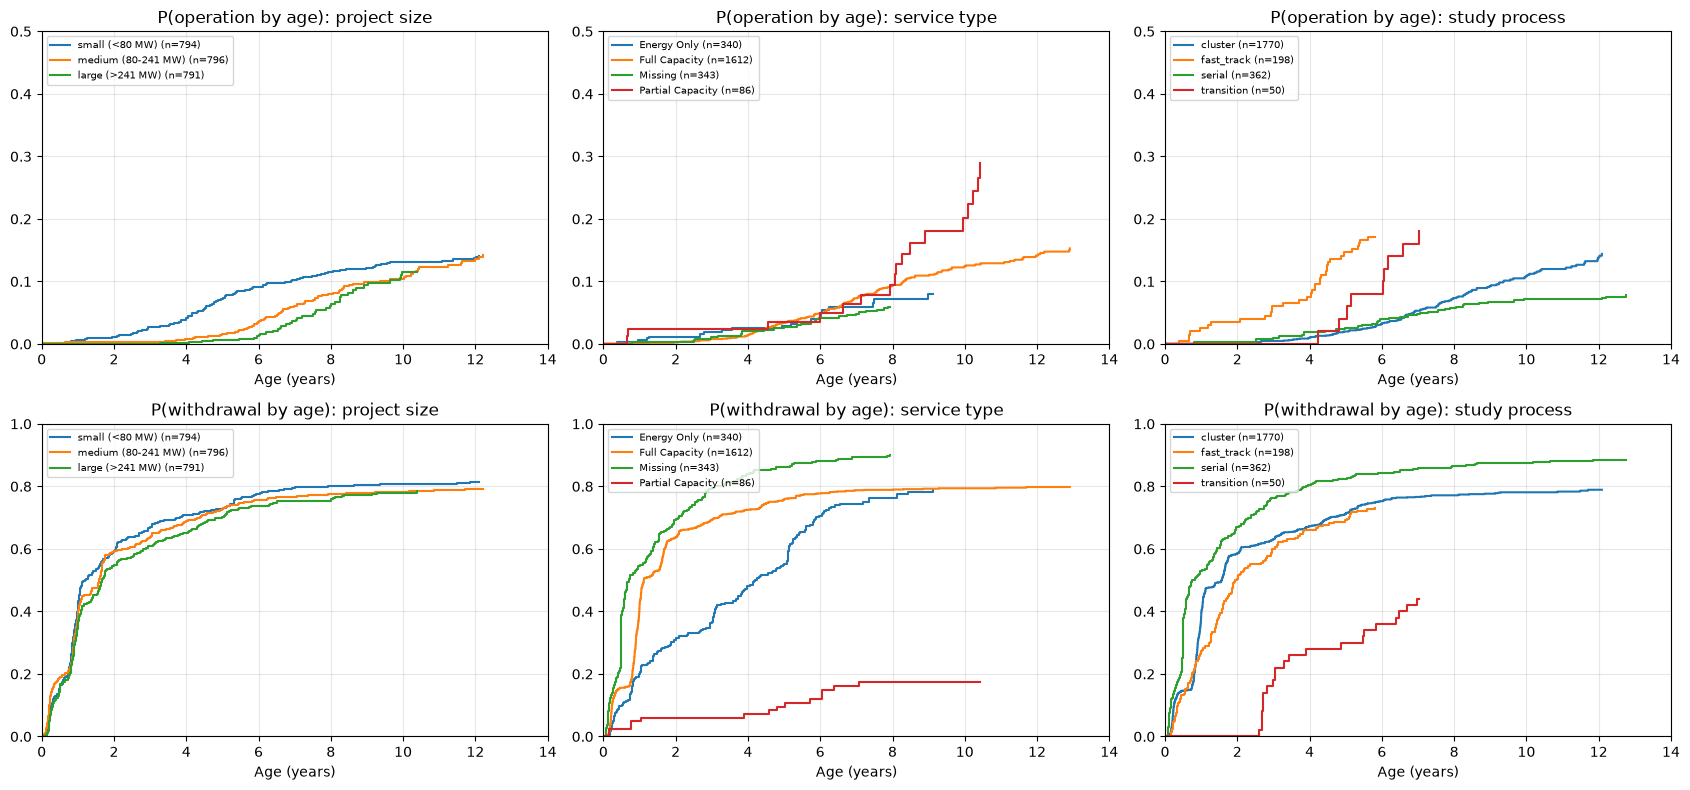

,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
era,,,,,,,,,,,,
queued <=2008,420,64,340,16,0.445,0.570,0.749,0.807,0.003,0.003,0.034,0.083
2009-2012,551,72,466,13,0.376,0.648,0.779,0.833,0.002,0.004,0.060,0.114
2013-2016,398,61,306,31,0.540,0.613,0.734,0.764,0.005,0.008,0.028,0.075
2017-2023,842,33,607,202,0.318,0.523,0.663,0.733,0.004,0.006,0.017,0.066
2025 (Cluster 15),170,0,84,86,0.365,NaN,NaN,NaN,0.000,NaN,NaN,NaN


,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
tech_group,,,,,,,,,,,,
Battery,759,37,543,179,0.333,0.543,0.680,0.753,0.000,0.000,0.010,0.073
Natural Gas,215,33,176,6,0.532,0.671,0.800,0.824,0.015,0.025,0.076,0.104
Other,97,15,74,8,0.464,0.586,NaN,NaN,0.012,0.022,NaN,NaN
Solar,1112,128,851,133,0.410,0.592,0.731,0.780,0.001,0.002,0.034,0.098
Wind Turbine,198,17,159,22,0.331,0.515,0.693,0.795,0.011,0.011,0.030,0.061


,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
storage_label,,,,,,,,,,,,
has storage,1100,73,720,307,0.318,0.505,0.629,0.685,0.000,0.000,0.008,0.054
no storage,1281,157,1083,41,0.456,0.639,0.795,0.848,0.006,0.009,0.052,0.102


,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
size_tercile,,,,,,,,,,,,
small (<80 MW),794,107,637,50,0.418,0.592,0.729,0.800,0.006,0.011,0.073,0.115
medium (80-241 MW),796,78,599,119,0.392,0.590,0.727,0.775,0.003,0.003,0.016,0.080
large (>241 MW),791,45,567,179,0.364,0.546,0.702,0.755,0.000,0.000,0.006,0.061


,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
service_type,,,,,,,,,,,,
Energy Only,340,19,238,83,0.204,0.307,0.548,0.763,0.006,0.012,0.029,0.073
Full Capacity,1612,157,1242,213,0.422,0.637,0.758,0.789,0.001,0.003,0.034,0.093
Missing,343,34,309,0,0.545,0.694,0.861,NaN,0.003,0.003,0.028,NaN
Partial Capacity,86,20,14,52,0.048,0.060,0.095,0.176,0.024,0.024,0.036,0.095


,projects,operations,withdrawals,active,P(wd by 1y),P(wd by 2y),P(wd by 5y),P(wd by 8y),P(op by 1y),P(op by 2y),P(op by 5y),P(op by 8y)
study_group,,,,,,,,,,,,
cluster,1770,127,1317,326,0.394,0.585,0.712,0.771,0.001,0.002,0.020,0.073
fast_track,198,42,150,6,0.273,0.505,0.692,NaN,0.025,0.035,0.146,NaN
other,1,1,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
serial,362,42,309,11,0.529,0.669,0.825,0.864,0.003,0.003,0.026,0.058
transition,50,18,27,5,0.000,0.000,0.300,NaN,0.000,0.000,0.040,NaN


In [23]:
# --- 6.3 CIFs by group (trimmed to ages with >= 20 projects at risk).
tercile_edges = analysis["log_net_mw"].quantile([1 / 3, 2 / 3]).to_numpy()
analysis["size_tercile"] = pd.cut(analysis["log_net_mw"], [-np.inf, *tercile_edges, np.inf],
                                  labels=[f"small (<{np.exp(tercile_edges[0]):.0f} MW)",
                                          f"medium ({np.exp(tercile_edges[0]):.0f}-{np.exp(tercile_edges[1]):.0f} MW)",
                                          f"large (>{np.exp(tercile_edges[1]):.0f} MW)"])
analysis["storage_label"] = np.where(analysis["has_storage"] == 1, "has storage", "no storage")


def group_curves(ax_op, ax_wd, column, title):
    for level, grp in analysis.groupby(column, observed=True):
        if len(grp) < 30:
            continue
        for ax, cause in [(ax_op, 1), (ax_wd, 2)]:
            c = trimmed_curve(grp, cause)
            ax.step(c.index, c["cif"], where="post", label=f"{level} (n={len(grp)})")
    ax_op.set(title=f"P(operation by age): {title}", ylim=(0, 0.5)); ax_wd.set(title=f"P(withdrawal by age): {title}", ylim=(0, 1))
    for ax in (ax_op, ax_wd):
        ax.set(xlabel="Age (years)", xlim=(0, 14)); ax.legend(fontsize=7, loc="upper left")


fig, axes = plt.subplots(2, 3, figsize=(17, 8))
group_curves(axes[0, 0], axes[1, 0], "era", "queue era")
group_curves(axes[0, 1], axes[1, 1], "tech_group", "technology")
group_curves(axes[0, 2], axes[1, 2], "storage_label", "storage")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
group_curves(axes[0, 0], axes[1, 0], "size_tercile", "project size")
group_curves(axes[0, 1], axes[1, 1], "service_type", "service type")
group_curves(axes[0, 2], axes[1, 2], "study_group", "study process")
plt.tight_layout(); plt.show()

SUMMARY_AGES = [1, 2, 5, 8]
def group_table(column):
    rows = []
    for level, grp in analysis.groupby(column, observed=True):
        row = {column: level, "projects": len(grp), "operations": int((grp["event"] == 1).sum()),
               "withdrawals": int((grp["event"] == 2).sum()), "active": int((grp["event"] == 0).sum())}
        for a, v in zip(SUMMARY_AGES, cif_summary(grp, 2, SUMMARY_AGES)):
            row[f"P(wd by {a}y)"] = v
        for a, v in zip(SUMMARY_AGES, cif_summary(grp, 1, SUMMARY_AGES)):
            row[f"P(op by {a}y)"] = v
        rows.append(row)
    return pd.DataFrame(rows).set_index(column)

for col in ["era", "tech_group", "storage_label", "size_tercile", "service_type", "study_group"]:
    display(group_table(col))

**Interpretation.**
* **Storage** is the largest single separator: projects with storage have lower withdrawal (50% by 2 years versus 64%) and **lower operation probability (5.4% versus 10.2% by year 8)**. Low withdrawal and low operation together mean that storage projects *stay in the queue longer*, which is why they are heavily represented among the active projects.
* **Size:** large projects (> 241 MW) almost never reach operation within 5 years (0.6%) while small ones (< 80 MW) reach it in 7.3% of cases; withdrawal differs less (70% versus 73% by year 5).
* **Technology:** gas has the highest operation probability by year 5 (7.6%) and batteries the lowest (1.0%), but battery projects are almost all recent (most have not had time).
* **Service type:** Partial Capacity projects hardly ever withdraw (9.5% by year 5) and are mostly still active; Energy Only projects withdraw more slowly at first (31% by year 2 versus 64% for Full Capacity). The "Missing" level is almost entirely old projects (see Section 9.1).
* **Process:** fast-track projects operate far more often (14.6% by year 5) than cluster-process projects (2.0%); "transition" projects have no withdrawals in the first two years.
* **Era (the first panel):** operation by year 8 is 8% for projects queued up to 2008, 11% for 2009 to 2012, 7.5% for 2013 to 2016, and 6.6% for 2017 to 2023. The recent cohorts are not clearly worse; they simply have little data at age 8.
* **Caution:** these are marginal comparisons. Storage, size, and era are strongly related (Section 7.5), so the differences above mix real effects with composition. Section 9 separates them.

,projects,queue_year,active,P(wd by 0.5y),P(wd by 1y),P(wd by 1.5y),P(wd by 3y),P(op by 3y),P(op by 5y),P(op by 8y)
cohort,,,,,,,,,,
Pre-cluster,611,2008.000,22,0.252,0.390,0.473,0.656,0.026,0.066,0.119
C01,25,2009.000,2,0.120,0.160,NaN,NaN,NaN,NaN,NaN
C02,57,2010.000,1,0.193,0.404,0.526,0.596,0.000,NaN,NaN
C03,48,2010.000,1,0.167,0.333,NaN,NaN,NaN,NaN,NaN
C04,189,2011.000,5,0.116,0.476,0.725,0.794,0.000,0.016,NaN
C05,76,2012.000,1,0.303,0.447,NaN,NaN,NaN,NaN,NaN
C06,61,2013.000,3,0.213,0.574,0.607,NaN,NaN,NaN,NaN
C07,82,2014.000,6,0.098,0.598,0.622,0.720,0.024,NaN,NaN
C08,119,2015.000,9,0.202,0.487,0.513,0.630,0.000,0.000,0.059


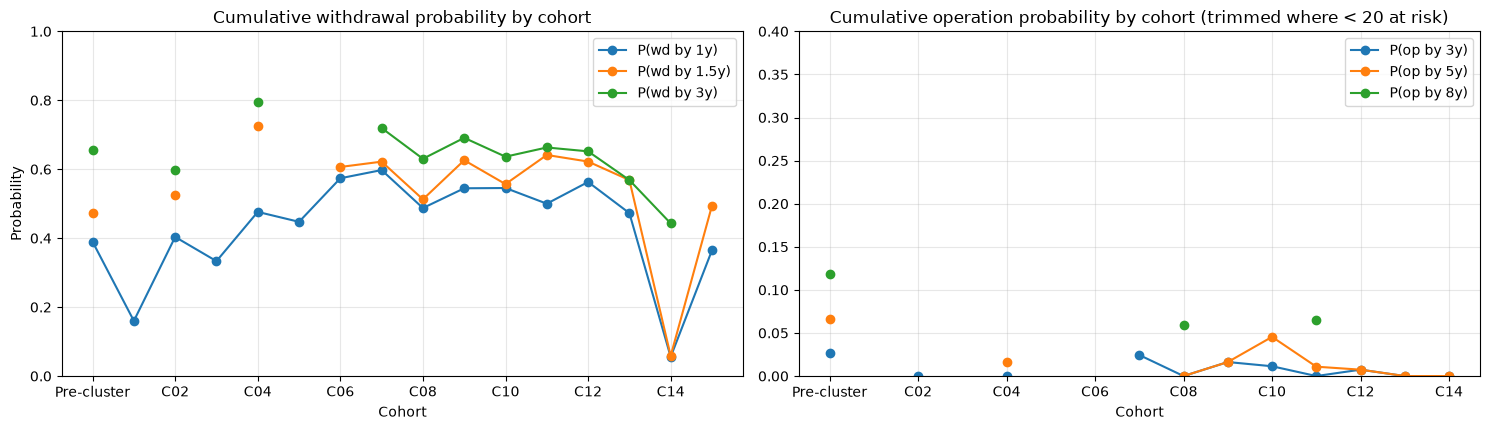

In [24]:
# --- 6.4 By cohort (cluster): early withdrawal and eventual operation.
rows = []
for cohort in cohort_order:
    grp = analysis[analysis["cohort"] == cohort]
    if len(grp) < 20:
        continue
    row = {"cohort": cohort, "projects": len(grp), "queue_year": grp["queue_year"].median(), "active": int((grp["event"] == 0).sum())}
    for a, v in zip([0.5, 1, 1.5, 3], cif_summary(grp, 2, [0.5, 1, 1.5, 3])):
        row[f"P(wd by {a}y)"] = v
    for a, v in zip([3, 5, 8], cif_summary(grp, 1, [3, 5, 8])):
        row[f"P(op by {a}y)"] = v
    rows.append(row)
cohort_table = pd.DataFrame(rows).set_index("cohort")
display(cohort_table)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
cohort_table[["P(wd by 1y)", "P(wd by 1.5y)", "P(wd by 3y)"]].plot(ax=axes[0], marker="o")
axes[0].set(title="Cumulative withdrawal probability by cohort", xlabel="Cohort", ylabel="Probability", ylim=(0, 1))
cohort_table[["P(op by 3y)", "P(op by 5y)", "P(op by 8y)"]].plot(ax=axes[1], marker="o")
axes[1].set(title="Cumulative operation probability by cohort (trimmed where < 20 at risk)", xlabel="Cohort", ylim=(0, 0.4))
plt.tight_layout(); plt.show()

**Interpretation.**
* **The early withdrawal probability varies a lot by cohort:** between 16% (C01) and 60% (C07) by age 1, and between 47% and 73% by age 1.5 for the cohorts with enough data (excluding Cluster 14). It is not a stable property of "the queue".
* **Cluster 14 is an outlier: only 5.6% had withdrawn by age 1 or 1.5, but 44% had by age 3.** Its withdrawals were bunched at about 1.6 to 1.8 years (November 2022 to January 2023). The earlier clusters' bunching came earlier.
* **Cluster 15 sits at 36.5% by age 1 and 49% by age 1.5,** lower than Clusters 10 to 13 (47% to 56% by age 1) but not wildly different, and with follow-up that ends at 1.6 years.
* Together these show that **age alone does not determine withdrawal timing**: the cluster's process milestones do. This is the biggest threat to a single age-based hazard model and the reason Section 13 recommends stratifying the baseline hazard.
* Operation probabilities by cohort are mostly missing (shown as blank) because fewer than 20 projects are at risk at those ages. In the recent clusters (C13 and later) there is essentially nothing to estimate.

### 6.5 Sensitivity of the main curves to data decisions

Every decision in Sections 3 and 4 was a judgment call. Here we redo the key estimates under reasonable alternatives and see which
conclusions move. A conclusion that survives all alternatives is robust; one that does not should be treated as uncertain.

| Scenario | What changes |
|---|---|
| Base | Delayed entry 2007-01-01; drop projects with an unknown event date; origin = queue date |
| Impute missing dates | The 52 projects with an unknown event date are kept, with the median duration of their outcome group |
| Restrict, queued >= 2007 | Projects queued before the window are removed instead of delayed-entry |
| Origin = earlier of request-receipt and queue dates | The clock starts when the request was received |
| Without Cluster 15 | Cluster 15 excluded |
| Without Pre-cluster | Serial, fast-track, and transition projects excluded (only C01+ cluster-process projects) |

In [25]:
def build_scenario(kind):
    if kind == "base":
        return analysis
    if kind == "impute":
        t = sd.apply_window(sd.resolve_missing_event_dates(sd.repair_durations(raw_table), "impute_median"), WINDOW_START, "delayed_entry")
        return t
    if kind == "restrict":
        return sd.apply_window(table_all, WINDOW_START, "restrict")
    if kind == "origin":
        t = analysis.copy()
        origin = pd.concat([t["queue_date"], projects.loc[t.index, "ir_receive_date"]], axis=1).min(axis=1)
        shift = (t["queue_date"] - origin).dt.days / sd.DAYS_PER_YEAR
        t["duration_years"] = t["duration_years"] + shift
        t["entry_years"] = ((WINDOW_START - origin).dt.days / sd.DAYS_PER_YEAR).clip(lower=0)
        return t
    if kind == "no_c15":
        return analysis[analysis["cohort"] != "C15"]
    if kind == "no_precluster":
        return analysis[analysis["cohort"] != "Pre-cluster"]


scenarios = {"Base": "base", "Impute missing dates": "impute", "Restrict, queued >= 2007": "restrict",
             "Origin = earlier of receipt/queue": "origin", "Without Cluster 15": "no_c15", "Without Pre-cluster": "no_precluster"}
metric_spec = [("P(wd by 1y)", 2, 1), ("P(wd by 3y)", 2, 3), ("P(wd by 5y)", 2, 5), ("P(op by 3y)", 1, 3), ("P(op by 5y)", 1, 5), ("P(op by 10y)", 1, 10)]
sens_rows = {}
for label, kind in scenarios.items():
    tab = build_scenario(kind)
    sens_rows[label] = {name: sd.cif_at(*arrs(tab)[:2], cause, age, arrs(tab)[2])[0] for name, cause, age in metric_spec}
    sens_rows[label]["projects"] = len(tab)
sensitivity = pd.DataFrame(sens_rows).T
display(sensitivity)
spread = sensitivity.drop(columns="projects").agg(lambda s: s.max() - s.min())
display(spread.to_frame("range across scenarios (percentage points as fractions)").T)

,P(wd by 1y),P(wd by 3y),P(wd by 5y),P(op by 3y),P(op by 5y),P(op by 10y),projects
Base,0.391,0.638,0.719,0.011,0.033,0.115,2381.000
Impute missing dates,0.389,0.649,0.727,0.010,0.032,0.116,2433.000
"Restrict, queued >= 2007",0.397,0.647,0.728,0.011,0.032,0.113,2274.000
Origin = earlier of receipt/queue,0.365,0.633,0.715,0.011,0.033,0.116,2381.000
Without Cluster 15,0.393,0.639,0.720,0.011,0.033,0.115,2211.000
Without Pre-cluster,0.394,0.631,0.712,0.005,0.020,0.109,1770.000


,P(wd by 1y),P(wd by 3y),P(wd by 5y),P(op by 3y),P(op by 5y),P(op by 10y)
range across scenarios (percentage points as fractions),0.032,0.018,0.016,0.006,0.013,0.008


**Interpretation.**
* **The headline curves are robust to data handling:** across all six scenarios, the probability of withdrawal by 3 and 5 years moves by at most 1.8 percentage points, and the probability of operation by 10 years by 0.8 points.
* The **largest movement (3.2 points, withdrawal by year 1)** comes from changing the time origin to the earlier of request-receipt and queue dates (36.5% versus 39.1%). That is expected: the clock starts earlier, so events happen at a larger age.
* **Imputing the 52 missing dates changes nothing material** (withdrawal by 3 years 64.9% versus 63.8%).
* **Excluding the Pre-cluster projects cuts the operation estimates by 40% to 55% (2.0% versus 3.3% by year 5; 0.5% versus 1.1% by year 3),** because 116 of 252 operations are Pre-cluster projects. The cluster-process projects alone have a much lower probability of reaching operation, which is a warning about the regime shift: the "typical" operation probability depends heavily on which process era the data come from.
* Excluding Cluster 15 changes nothing, as expected for a cohort with 84 early events.

## 7. Calendar-time structure

**Purpose.** Check whether outcomes depend not only on a project's *age* but also on the *calendar date*, and whether projects of one
cluster share events in bursts.

**Why it matters.** Standard survival models assume each project's event risk depends on its covariates and its age. In the CAISO
queue, rule changes (cluster process reforms, study deadlines, deposit requirements) hit **every project in a cluster at the same
calendar date**. If events come in bursts on specific dates, then:
1. projects within a cluster are *not independent* (standard errors are too small unless clustered);
2. many event times are *tied* (identical dates), which most estimators handle approximately;
3. a model trained on past calendar periods may not predict a future period with different rules.

**Key terms.** *Cohort effect*: all projects in a cohort share a shock. *Ties*: several events at the identical time.
*Period effect*: risk depends on calendar date.

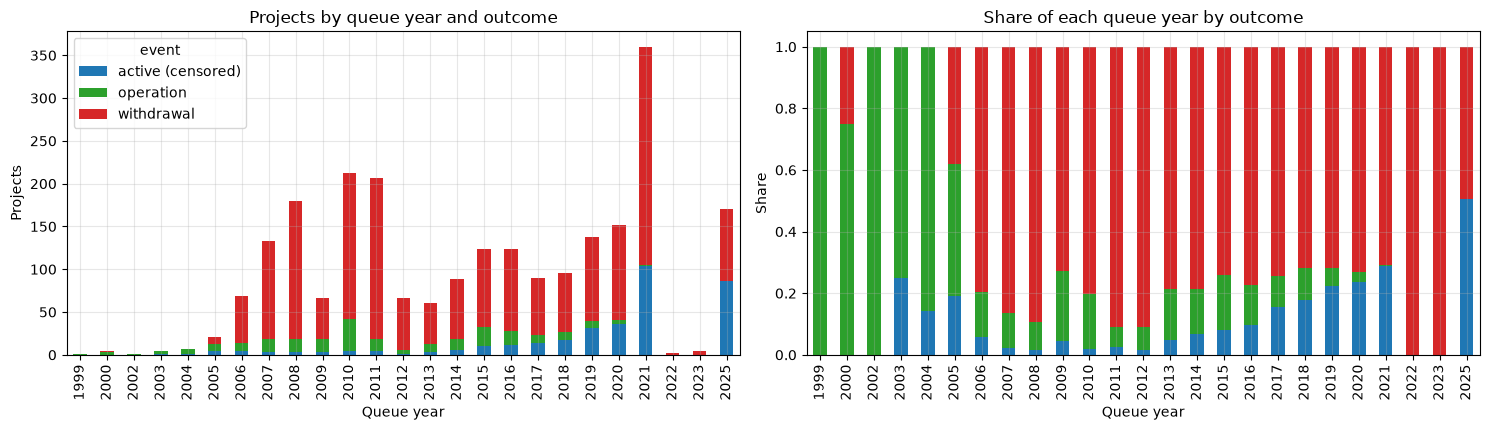

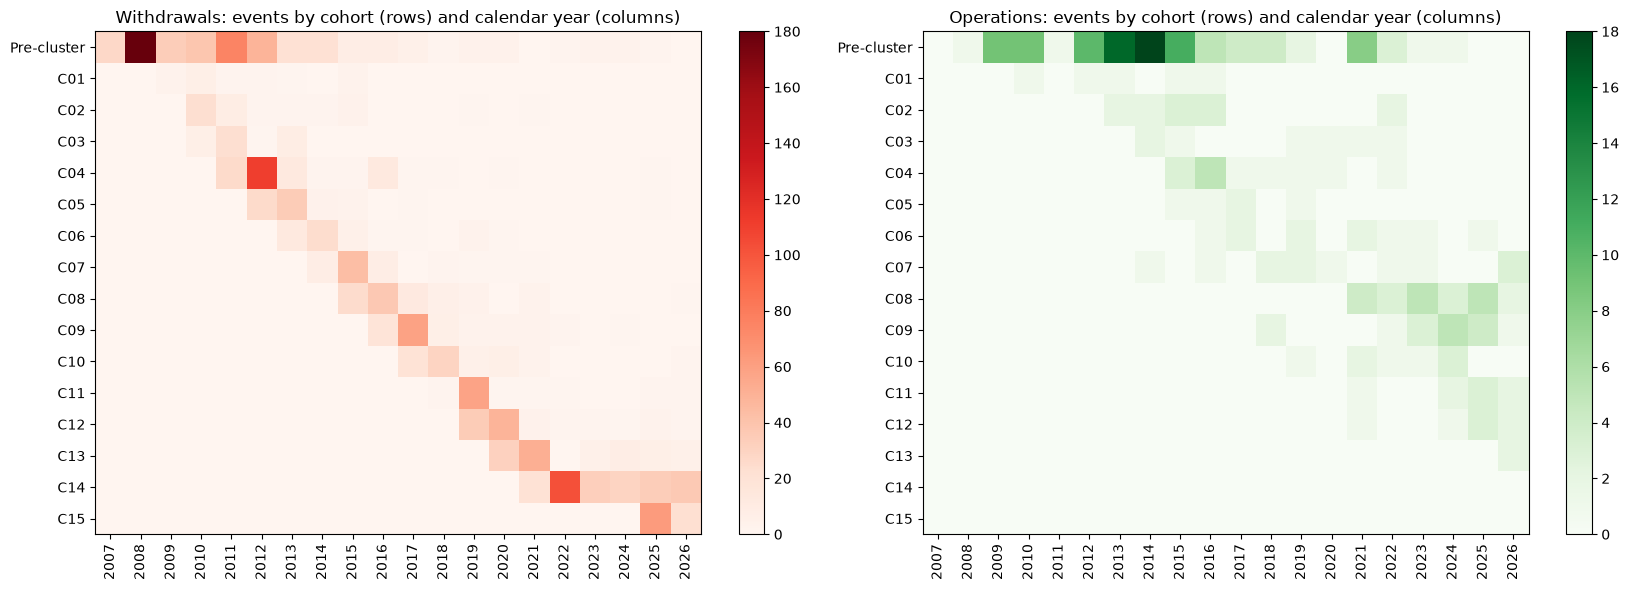

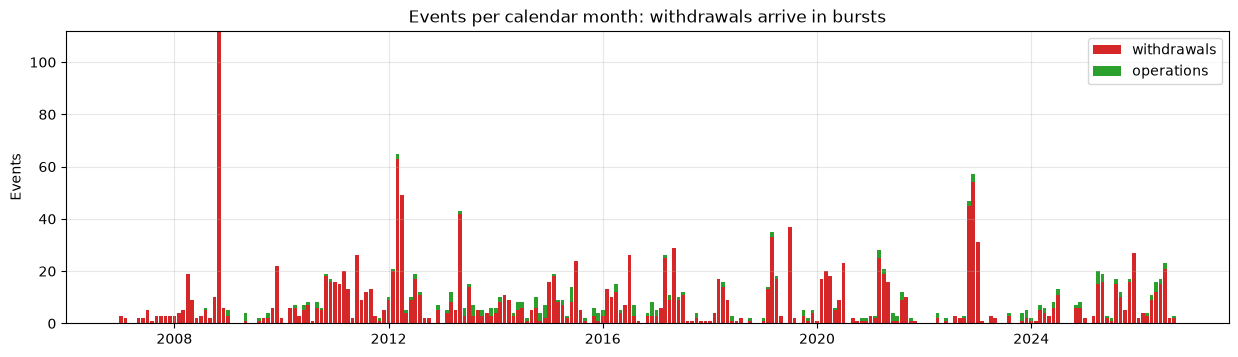

Withdrawals: 1803; distinct withdrawal dates: 909; largest same-day group: 64 on 2008-11-26
Share of withdrawals in the busiest 12 calendar months (of 204 active months): 30.4%
Share of all event dates tied with at least one other event of the same cause: 69.1%


event_date,2008-11,2012-03,2022-12,2012-04,2022-11,2013-05,2019-07,2019-03,2023-01,2017-05
withdrawals,112,63,54,49,45,42,37,33,31,29


In [26]:
# --- 7.1 Outcomes by queue year.
by_year = pd.crosstab(analysis["queue_year"], analysis["event"].map(sd.EVENT_LABELS))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
by_year.plot(kind="bar", stacked=True, ax=axes[0], color=["tab:blue", "tab:green", "tab:red"])
axes[0].set(title="Projects by queue year and outcome", xlabel="Queue year", ylabel="Projects")
(by_year.div(by_year.sum(axis=1), axis=0)).plot(kind="bar", stacked=True, ax=axes[1], color=["tab:blue", "tab:green", "tab:red"], legend=False)
axes[1].set(title="Share of each queue year by outcome", xlabel="Queue year", ylabel="Share")
plt.tight_layout(); plt.show()

# --- 7.2 Calendar bursts: events by cohort and calendar year.
cal_year = analysis["end_date"].dt.year
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, ev, name, cmap in [(axes[0], 2, "Withdrawals", "Reds"), (axes[1], 1, "Operations", "Greens")]:
    mat = pd.crosstab(analysis.loc[analysis["event"] == ev, "cohort"], cal_year[analysis["event"] == ev]).reindex(cohort_order).fillna(0)
    mat = mat.reindex(columns=range(2007, 2027), fill_value=0)
    im = ax.imshow(mat.values, aspect="auto", cmap=cmap)
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns, rotation=90); ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
    ax.set(title=f"{name}: events by cohort (rows) and calendar year (columns)"); ax.grid(False); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

# Monthly event counts over calendar time: bursts rather than a steady trickle.
months = pd.period_range("2007-01", "2026-09", freq="M")
monthly_counts = pd.DataFrame({"withdrawals": analysis.loc[analysis["event"] == 2, "event_date"].dt.to_period("M").value_counts(),
                               "operations": analysis.loc[analysis["event"] == 1, "event_date"].dt.to_period("M").value_counts()}).reindex(months, fill_value=0)
fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(months.to_timestamp(), monthly_counts["withdrawals"], width=25, color="tab:red", label="withdrawals")
ax.bar(months.to_timestamp(), monthly_counts["operations"], width=25, color="tab:green", label="operations", bottom=monthly_counts["withdrawals"])
ax.set(title="Events per calendar month: withdrawals arrive in bursts", ylabel="Events"); ax.legend(); plt.show()

# --- 7.3 Ties and bursts.
wd = analysis[analysis["event"] == 2]
dates = wd["event_date"].value_counts()
monthly = wd["event_date"].dt.to_period("M").value_counts()
print(f"Withdrawals: {len(wd)}; distinct withdrawal dates: {dates.size}; largest same-day group: {dates.iloc[0]} on {dates.index[0].date()}")
print(f"Share of withdrawals in the busiest 12 calendar months (of {monthly.size} active months): {monthly.head(12).sum() / len(wd):.1%}")
print(f"Share of all event dates tied with at least one other event of the same cause: {(wd['event_date'].map(dates) > 1).mean():.1%}")
display(monthly.head(10).rename("withdrawals").to_frame().T)

**Interpretation.**
* The cohort-by-year heatmap shows **a bright diagonal: each cluster loses most of its projects in a short span of calendar time after it enters.** The withdrawals of one cluster are concentrated in one or two years, then it largely goes quiet.
* The monthly bars confirm it: **withdrawals arrive in spikes.** The single busiest month is November 2008 (112 withdrawals, 64 on 2008-11-26 alone), followed by March and April 2012 (63 and 49), and November and December 2022 (45 and 54, Cluster 14).
* **The busiest 12 months hold 30% of all withdrawals,** and **69% of withdrawals share an exact date with at least one other withdrawal.** The data do not state the cause; the pattern is consistent with study-deposit or cluster-process deadlines that force all projects of a cluster to decide at once.
* Operations are much less bursty (green, spread over the years), although they too cluster by cohort.
* **Consequences for modeling:** (1) standard errors must be clustered (projects in one cluster move together), (2) there are many tied event times (the estimator used here handles ties exactly, and Cox models use the Efron method), and (3) a model fitted on past calendar periods encodes past milestone timing, which may not repeat.

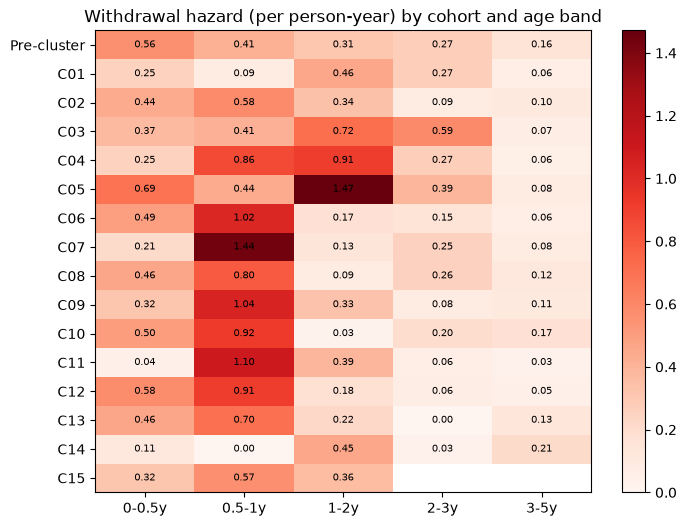

,projects,storage_share,solar_share,hybrid_share,median_mw,median_kv,share_energy_only,share_cluster_process
era,,,,,,,,
queued <=2008,420,0.055,0.417,0.052,161.997,230.000,0.031,0.000
2009-2012,551,0.036,0.815,0.056,29.000,115.000,0.220,0.719
2013-2016,398,0.447,0.523,0.204,92.870,220.000,0.098,0.970
2017-2023,842,0.874,0.249,0.428,201.000,230.000,0.133,0.971
2025 (Cluster 15),170,0.841,0.412,0.365,301.000,230.000,0.324,1.000


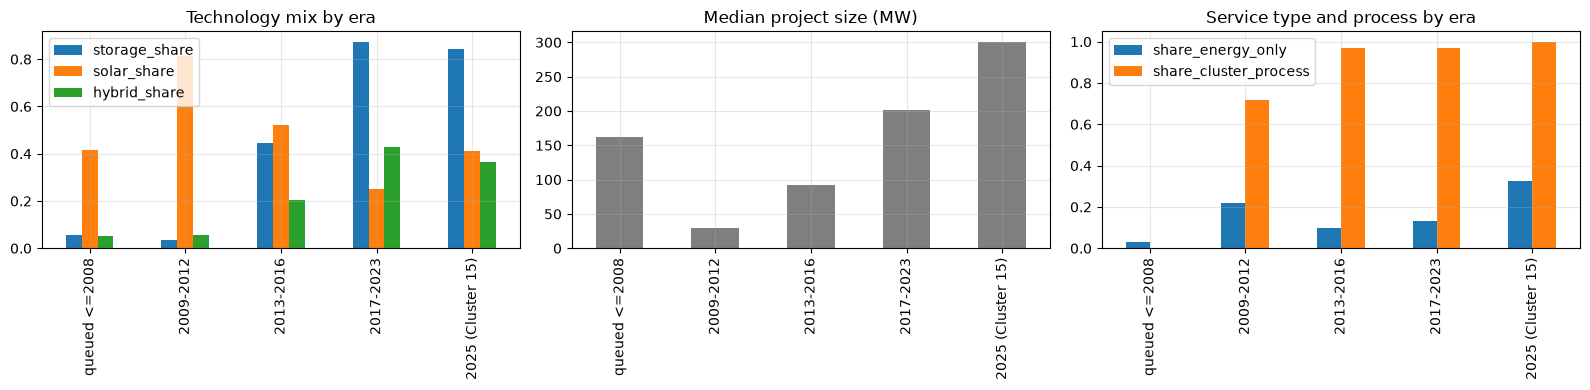

In [27]:
# --- 7.4 Calendar-time risk: early withdrawal hazard by cohort and by calendar year of queue entry.
rows = []
for cohort in cohort_order:
    grp = analysis[analysis["cohort"] == cohort]
    if len(grp) < 20:
        continue
    for lo, hi in [(0, 0.5), (0.5, 1), (1, 2), (2, 3), (3, 5)]:
        h = sd.piecewise_hazard(*arrs(grp)[:2], 2, [lo, hi], arrs(grp)[2]).iloc[0]
        rows.append({"cohort": cohort, "band": f"{lo}-{hi}y", "hazard": h["hazard_per_year"] if h["person_years"] > 5 else np.nan})
haz_map = pd.DataFrame(rows).pivot(index="cohort", columns="band", values="hazard").reindex(cohort_order).dropna(how="all")
haz_map = haz_map[["0-0.5y", "0.5-1y", "1-2y", "2-3y", "3-5y"]]
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(haz_map.values, aspect="auto", cmap="Reds"); ax.grid(False)
ax.set_xticks(range(haz_map.shape[1])); ax.set_xticklabels(haz_map.columns); ax.set_yticks(range(len(haz_map))); ax.set_yticklabels(haz_map.index)
for i in range(haz_map.shape[0]):
    for j in range(haz_map.shape[1]):
        if not np.isnan(haz_map.values[i, j]):
            ax.text(j, i, f"{haz_map.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Withdrawal hazard (per person-year) by cohort and age band"); plt.colorbar(im, ax=ax); plt.show()

# --- 7.5 Era composition: the mix of project types changes sharply over time.
comp = analysis.groupby("era", observed=True).agg(projects=("event", "size"), storage_share=("has_storage", "mean"), solar_share=("is_solar", "mean"),
                                                  hybrid_share=("is_hybrid", "mean"), median_mw=("log_net_mw", lambda s: np.exp(s.median())),
                                                  median_kv=("poi_kv", "median"), share_energy_only=("service_type", lambda s: (s == "Energy Only").mean()),
                                                  share_cluster_process=("study_group", lambda s: (s == "cluster").mean()))
display(comp)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
comp[["storage_share", "solar_share", "hybrid_share"]].plot(kind="bar", ax=axes[0]); axes[0].set(title="Technology mix by era", xlabel="")
comp["median_mw"].plot(kind="bar", ax=axes[1], color="tab:gray"); axes[1].set(title="Median project size (MW)", xlabel="")
comp[["share_energy_only", "share_cluster_process"]].plot(kind="bar", ax=axes[2]); axes[2].set(title="Service type and process by era", xlabel="")
plt.tight_layout(); plt.show()

**Interpretation.**
* **The hazard heatmap confirms the cohort-specific timing:** most clusters from C04 to C12 have their peak withdrawal hazard in the second half of the first year (0.8 to 1.4 per project-year at ages 0.5 to 1), whereas **Cluster 14 has a hazard of 0.00 in that band and peaks at ages 1 to 2 (0.45)**. Cluster 15 is in between (0.32 and 0.57 in the first two half-years).
* **The project mix changes enormously across eras.** Storage share rises from 5% (up to 2008) and 4% (2009 to 2012) to 45% (2013 to 2016), 87% (2017 to 2023), and 84% (Cluster 15). Median project size goes from 29 MW (2009 to 2012, small solar) to 201 MW (2017 to 2023) and 301 MW (Cluster 15). Energy-only service is 3%, then 22% in 2009 to 2012, and 32% in Cluster 15.
* The "cluster process" share goes from 0% to 72% to 97% and 100%. So **era, technology, size, and rule regime move together**: almost every feature is also an era marker.
* **Implication:** a model that learns "storage means slow" is partly learning "recent means slow," and the answer for Cluster 15 depends on which of those two it really learned. The era-confounding analysis in Section 9.8 quantifies this.

## 8. Cluster 15 versus the older clusters

**Purpose.** Determine whether Cluster 15 looks like the earlier clusters, and how much it can contribute to a model.

**Why it matters.** Cluster 15 is the newest cohort and the one the screener will most resemble, but it has only about 1.6 years of
follow-up, no operations, and 84 withdrawals. It can speak only about *early withdrawal*. Whether pooling it with older clusters is
safe depends on whether its projects look like theirs (**covariate shift**) and whether it behaves like them early on.

**Key terms.**
* *Covariate shift*: the feature mix differs between two groups, even if the outcome mechanism is the same.
* *Standardized mean difference (SMD)*: difference in means divided by the pooled standard deviation. Rule of thumb: |SMD| > 0.2 is
  noticeable, > 0.5 is large.
* *Adversarial validation*: train a classifier to tell the two groups apart. An AUC near 0.5 means they look alike; near 1.0 means
  they are easy to tell apart.

,C15 mean,C09-C14 mean,C01-C08 + pre-cluster mean,SMD vs C09-C14,SMD vs C14 alone
log_net_mw,5.543,5.160,4.332,0.400,0.204
poi_kv,320.229,214.391,174.504,0.766,0.746
requested_horizon_years,4.886,3.984,3.362,0.746,0.789
n_components,1.371,1.426,1.084,-0.110,-0.017
is_solar,0.412,0.311,0.591,0.211,0.506
is_hybrid,0.365,0.415,0.081,-0.102,-0.023
has_storage,0.841,0.823,0.143,0.049,-0.434
poi_is_line,0.112,0.130,0.256,-0.057,-0.099


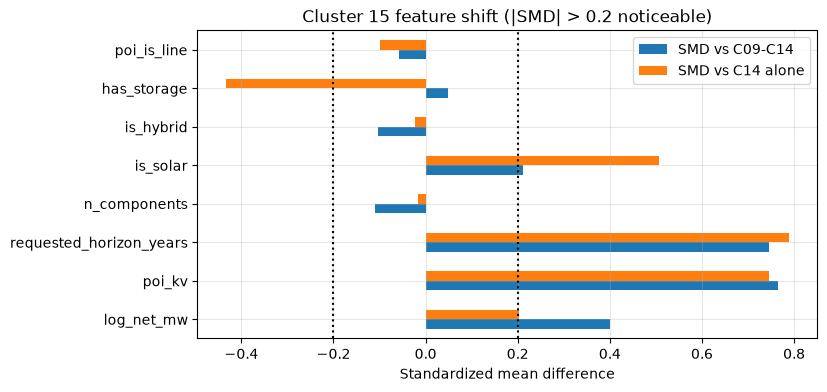

,C15,C14,C09-C13
fuel_1,,,
Battery,0.553,0.769,0.505
Solar,0.412,0.187,0.387
Wind Turbine,0.018,0.025,0.086
Biofuel,0.006,0.000,0.003
Compressed Air,0.006,0.000,0.000
Pumped-Storage hydro,0.006,0.006,0.007


,C15,C14,C09-C13
service_type,,,
Full Capacity,0.676,0.833,0.827
Energy Only,0.324,0.128,0.115
Missing,0.000,0.003,0.000
Partial Capacity,0.000,0.036,0.058


,C15,C14,C09-C13
utility,,,
PGAE,0.424,0.515,0.524
SCE,0.341,0.315,0.300
GLW,0.094,0.022,0.024
LSPC,0.065,0.000,0.000
SDGE,0.053,0.114,0.118
DCRT,0.012,0.025,0.019


,C15,C14,C09-C13
state,,,
CA,0.865,0.922,0.901
NV,0.094,0.031,0.048
AZ,0.041,0.039,0.045
ID,0.000,0.006,0.000
MX,0.000,0.003,0.007


Category values in Cluster 15 never seen in earlier clusters: {'fuel_1': ['Compressed Air'], 'utility': ['HWT', 'LSPC', 'WAPA'], 'county': ['KING', 'KINGS AND FRESNO', 'TIJUANA, MEXICO'], 'state': []}


In [28]:
# --- 8.1 Feature distribution: Cluster 15 vs recent clusters (C09-C14) vs all earlier projects.
recent_cohorts = [f"C{i:02d}" for i in range(9, 15)]
is15 = analysis["cohort"] == "C15"
recent = analysis["cohort"].isin(recent_cohorts)
old = ~is15 & ~recent
num_cols = ["log_net_mw", "poi_kv", "requested_horizon_years", "n_components"] + sd.SURVIVAL_BINARY[:3] + ["poi_is_line"]


def smd(a, b):
    a, b = a.dropna(), b.dropna()
    pooled = np.sqrt((a.var() + b.var()) / 2)
    return (a.mean() - b.mean()) / pooled if pooled > 0 else np.nan


shift = pd.DataFrame({"C15 mean": analysis.loc[is15, num_cols].mean(), "C09-C14 mean": analysis.loc[recent, num_cols].mean(),
                      "C01-C08 + pre-cluster mean": analysis.loc[old, num_cols].mean(),
                      "SMD vs C09-C14": [smd(analysis.loc[is15, c], analysis.loc[recent, c]) for c in num_cols],
                      "SMD vs C14 alone": [smd(analysis.loc[is15, c], analysis.loc[analysis["cohort"] == "C14", c]) for c in num_cols]})
display(shift)
fig, ax = plt.subplots(figsize=(8, 4))
shift[["SMD vs C09-C14", "SMD vs C14 alone"]].plot(kind="barh", ax=ax)
ax.axvline(0.2, color="k", ls=":"); ax.axvline(-0.2, color="k", ls=":"); ax.set(title="Cluster 15 feature shift (|SMD| > 0.2 noticeable)", xlabel="Standardized mean difference")
plt.show()

for col in ["fuel_1", "service_type", "utility", "state"]:
    t = pd.DataFrame({"C15": analysis.loc[is15, col].value_counts(normalize=True), "C14": analysis.loc[analysis["cohort"] == "C14", col].value_counts(normalize=True),
                      "C09-C13": analysis.loc[analysis["cohort"].isin(recent_cohorts[:-1]), col].value_counts(normalize=True)}).fillna(0)
    display(t.sort_values("C15", ascending=False).head(6))
unseen = {col: sorted(set(analysis.loc[is15, col].dropna()) - set(analysis.loc[~is15, col].dropna())) for col in ["fuel_1", "utility", "county", "state"]}
print("Category values in Cluster 15 never seen in earlier clusters:", unseen)

**Interpretation.**
* **Cluster 15 differs from Clusters 9 to 14 on three dimensions:** higher voltage (mean 320 kV versus 214, SMD 0.77, driven by 66 of the 170 projects at 500 kV versus 12% for Cluster 14), a longer requested timeline (4.9 years versus 4.0, SMD 0.75), and larger projects (SMD 0.40). Differences in technology mix are moderate.
* **Versus Cluster 14 alone**, Cluster 15 has more solar (41% versus 19% as first fuel) and fewer batteries (55% versus 77%), more energy-only service (32% versus 13%), and **no Partial Capacity projects** (about 13 had it in Cluster 14).
* **New categories:** Compressed Air (1 project), three utilities never seen before (WAPA, HWT, LSPC) and 7.6% of Cluster 15 projects belong to a utility with no history (11 of them LSPC), plus 9.4% in Nevada (versus 3% in Cluster 14). A model must have a rule for categories it has never seen.
* The shifts in kV and timeline are likely real (a different mix of projects) rather than a parsing artifact: the same parsing finds 500 kV projects in Cluster 14, just fewer of them.

In [29]:
# --- 8.2 Adversarial validation: can a classifier tell Cluster 15 from older projects using queue-entry features alone?
cat_cols = ["fuel_1", "type_1", "service_type", "utility", "state", "study_group"]  # county dropped: too sparse for this check
num_feat = ["log_net_mw", "n_components", "poi_kv", "requested_horizon_years", "is_solar", "is_hybrid", "has_storage", "poi_is_line"]
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder


def make_adversary():
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num_feat),
                             ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), cat_cols)])
    return Pipeline([("pre", pre), ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))])


def adversarial_auc(positive, negative, label):
    sub = analysis[positive | negative]
    y = positive[positive | negative].astype(int).to_numpy()
    probs = cross_val_predict(make_adversary(), sub[num_feat + cat_cols], y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    return {"comparison": label, "n_positive": int(y.sum()), "n_negative": int((1 - y).sum()), "AUC": roc_auc_score(y, probs)}


coh = analysis["cohort"]
adv = pd.DataFrame([
    adversarial_auc(is15, recent, "C15 vs C09-C14"),
    adversarial_auc(is15, coh == "C14", "C15 vs C14"),
    adversarial_auc(coh == "C14", coh.isin(recent_cohorts[:-1]), "C14 vs C09-C13 (benchmark: adjacent clusters)"),
    adversarial_auc(coh == "C13", coh.isin(recent_cohorts[:-2]), "C13 vs C09-C12 (benchmark)"),
    adversarial_auc(coh == "C12", coh.isin(recent_cohorts[:-3]), "C12 vs C09-C11 (benchmark)"),
]).set_index("comparison")
display(adv)

# Which features separate C15 from C14? (permutation importance on a held-out split)
from sklearn.model_selection import train_test_split
sub = analysis[is15 | (coh == "C14")]
y = is15[is15 | (coh == "C14")].astype(int)
Xtr, Xte, ytr, yte = train_test_split(sub[num_feat + cat_cols], y, test_size=0.3, stratify=y, random_state=SEED)
model = make_adversary().fit(Xtr, ytr)
imp = permutation_importance(model, Xte, yte, scoring="roc_auc", n_repeats=20, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=num_feat + cat_cols).sort_values(ascending=False)
print(f"Held-out AUC (C15 vs C14): {roc_auc_score(yte, model.predict_proba(Xte)[:, 1]):.3f}")
display(importance.head(8).to_frame("drop in AUC when shuffled"))

,n_positive,n_negative,AUC
comparison,,,
C15 vs C09-C14,170,943,0.887
C15 vs C14,170,359,0.866
C14 vs C09-C13 (benchmark: adjacent clusters),359,584,0.759
C13 vs C09-C12 (benchmark),146,438,0.743
C12 vs C09-C11 (benchmark),135,303,0.787


Held-out AUC (C15 vs C14): 0.853


,drop in AUC when shuffled
requested_horizon_years,0.152
poi_kv,0.117
service_type,0.022
n_components,0.011
is_hybrid,0.010
log_net_mw,0.009
utility,0.007
fuel_1,0.004


**Interpretation.**
* A classifier can tell Cluster 15 from Clusters 9 to 14 with **AUC 0.89** (0.87 against Cluster 14 alone, 0.85 held out), meaning that the queue-entry features alone reveal which cluster a project belongs to with high accuracy.
* **The benchmarks put that in context:** adjacent *older* clusters can also be told apart (AUC 0.74 to 0.79) simply because the queue evolves. Cluster 15 is **more distinguishable than the usual cluster-to-cluster drift, but not an order of magnitude more.**
* The features that separate Cluster 15 are **requested timeline and voltage** (shuffling either costs 0.12 to 0.15 AUC), well ahead of service type and size. Those two features are therefore the ones where a model trained on older clusters will be extrapolating when it scores Cluster 15.
* **What this means:** covariate shift is real and moderate, and it means model validation must be done on later clusters (not a random split), but it is not so large that Cluster 15 cannot be pooled with the older projects.

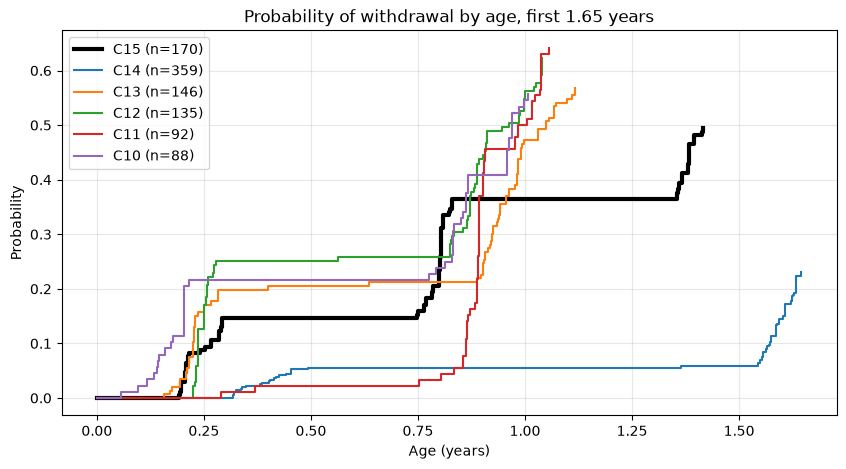

age,0.500,1.000,1.500
cohort,,,
C15,0.147,0.365,0.494
C14,0.056,0.056,0.058
C13,0.205,0.473,0.568
C12,0.252,0.563,0.622
C11,0.022,0.500,0.641
C10,0.216,0.545,0.557


P(wd)  ci_lower  ci_upper
cohort age                             
C15    0.500  0.147     0.100     0.206
       1.000  0.365     0.285     0.436
       1.500  0.494     0.418     0.571
C14    0.500  0.056     0.033     0.081
       1.000  0.056     0.033     0.081
       1.500  0.058     0.033     0.082

projects  P(wd by 1y)  P(wd by 1.5y)
cohort stratum                                          
C15    has storage       143        0.399          0.545
       no storage         27        0.185          0.222
C14    has storage       347        0.055          0.058
C13    has storage       133        0.466          0.571

In [30]:
# --- 8.3 Early behavior: does Cluster 15 withdraw like earlier clusters over the ages we can observe (up to ~1.6 years)?
fig, ax = plt.subplots(figsize=(10, 5))
rows = []
for cohort in ["C15", "C14", "C13", "C12", "C11", "C10"]:
    grp = analysis[analysis["cohort"] == cohort]
    c = sd.aj_cif(*arrs(grp)[:2], 2, arrs(grp)[2]); c = c[c.index <= 1.65]
    ax.step(c.index, c["cif"], where="post", lw=3 if cohort == "C15" else 1.5, label=f"{cohort} (n={len(grp)})", color="black" if cohort == "C15" else None)
    ci = sd.bootstrap_cif_at(*arrs(grp)[:2], 2, [0.5, 1.0, 1.5], arrs(grp)[2], n_boot=300, seed=SEED)
    for _, r in ci.iterrows():
        rows.append({"cohort": cohort, "age": r["age_years"], "P(wd)": r["estimate"], "ci_lower": r["ci_lower"], "ci_upper": r["ci_upper"]})
ax.set(title="Probability of withdrawal by age, first 1.65 years", xlabel="Age (years)", ylabel="Probability"); ax.legend()
plt.show()
display(pd.DataFrame(rows).pivot(index="cohort", columns="age", values="P(wd)").loc[["C15", "C14", "C13", "C12", "C11", "C10"]])
display(pd.DataFrame(rows).set_index(["cohort", "age"]).loc[["C15", "C14"]])

# Same comparison within technology strata (storage vs non-storage), to see whether the mix explains the difference.
strata = []
for cohort in ["C15", "C14", "C13"]:
    for flag, label in [(1, "has storage"), (0, "no storage")]:
        grp = analysis[(analysis["cohort"] == cohort) & (analysis["has_storage"] == flag)]
        if len(grp) >= 15:
            strata.append({"cohort": cohort, "stratum": label, "projects": len(grp), "P(wd by 1y)": sd.cif_at(*arrs(grp)[:2], 2, 1.0, arrs(grp)[2])[0],
                           "P(wd by 1.5y)": sd.cif_at(*arrs(grp)[:2], 2, 1.5, arrs(grp)[2])[0]})
display(pd.DataFrame(strata).set_index(["cohort", "stratum"]))

**Interpretation.**
* **Early withdrawal in Cluster 15 is in the range of recent clusters:** 36.5% by age 1 (95% interval 28% to 44%) and 49.4% by age 1.5 (42% to 57%), compared with 47% to 56% and 56% to 64% for Clusters 10 to 13. It is somewhat lower, with overlapping intervals.
* **Cluster 14 is the exception** (5.6% by 1.5 years), because its withdrawals came later (1.6 to 1.8 years; Section 6.4). If one pooled Cluster 14 with the others on the age scale, the model would struggle to explain its first 1.5 years.
* **Cluster 15's withdrawals arrived in three bursts** (April and May 2025, November and December 2025, June and July 2026), at ages of about 0.2, 0.75, and 1.3 years. Cluster 14's single large wave came later, at 1.6 to 1.8 years.
* **The storage pattern in Cluster 15 runs opposite to the pooled finding:** projects with storage had withdrawn more by 1.5 years than those without (54.5% versus 22.2%, but only 27 projects without storage). In Cluster 13 the storage projects' withdrawal is 57% by 1.5 years. So the "storage withdraws less" result, which held for the 2007 to 2016 queue, does not clearly hold in the recent regime (see Section 9.8).
* **Conclusion:** Cluster 15 is informative about the early recent-regime behavior and is *plausibly* compatible with Clusters 10 to 13, but it cannot test the long-run questions.

,withdrawals counted,max follow-up (y),P(wd by 1.0y),P(wd by 1.25y),P(wd by 1.5y)
assumed snapshot,,,,,
2026-07-14,84,1.415,0.365,0.365,NaN
2026-08-15,84,1.503,0.365,0.365,0.494
2026-09-24,84,1.613,0.365,0.365,0.494


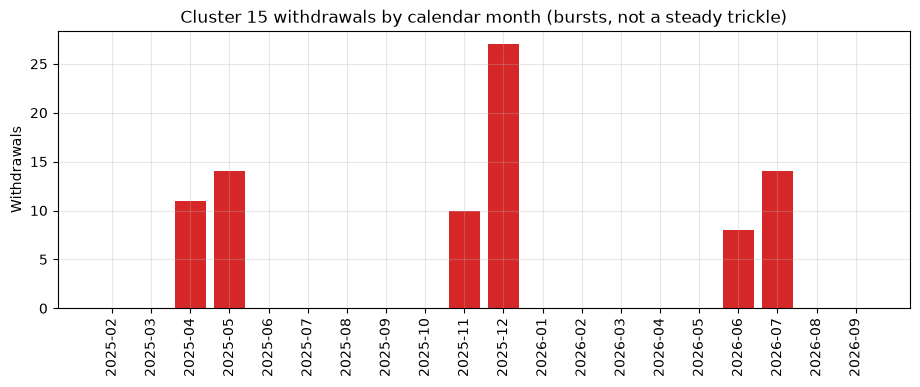

Latest dated Cluster 15 withdrawal: 2026-07-14 | months with zero withdrawals since queue entry: 14


In [31]:
# --- 8.4 Snapshot sensitivity: what if the true Cluster 15 export date is earlier than 2026-09-24?
c15 = analysis[analysis["cohort"] == "C15"].copy()
rows = []
for snap in [pd.Timestamp("2026-07-14"), pd.Timestamp("2026-08-15"), pd.Timestamp("2026-09-24")]:
    t = c15.copy()
    ends = t["end_date"].where(t["event"] > 0, snap)
    t["duration_years"] = (ends.clip(upper=snap) - t["queue_date"]).dt.days / sd.DAYS_PER_YEAR
    t = t[(t["event"] == 0) | (t["event_date"] <= snap)]
    row = {"assumed snapshot": snap.date(), "withdrawals counted": int((t["event"] == 2).sum()), "max follow-up (y)": t["duration_years"].max()}
    for a in [1.0, 1.25, 1.5]:  # NaN when nobody is observed that long (the estimate would be a carry-forward)
        row[f"P(wd by {a}y)"] = cif_summary(t, 2, [a], min_risk=5)[0]
    rows.append(row)
display(pd.DataFrame(rows).set_index("assumed snapshot"))

# Are there signs the export predates 2026-09-24? Withdrawal dates by month for Cluster 15 (bursts, then silence).
monthly15 = c15.loc[c15["event"] == 2, "event_date"].dt.to_period("M").value_counts().sort_index()
monthly15 = monthly15.reindex(pd.period_range("2025-02", "2026-09", freq="M"), fill_value=0)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(monthly15.index.astype(str), monthly15.values, color="tab:red"); ax.tick_params(axis="x", rotation=90)
ax.set(title="Cluster 15 withdrawals by calendar month (bursts, not a steady trickle)", ylabel="Withdrawals"); plt.show()
print("Latest dated Cluster 15 withdrawal:", c15["event_date"].max().date(), "| months with zero withdrawals since queue entry:", int((monthly15 == 0).sum()))

**Interpretation.**
* **The Cluster 15 early withdrawal estimates do not depend on the assumed snapshot:** all 84 withdrawals are dated on or before 2026-07-14, so moving the snapshot earlier within the range tested does not change the number of withdrawals or the curve up to the available follow-up.
* **What the snapshot changes is the *follow-up limit*** (1.42 years if the snapshot were 2026-07-14; 1.61 years at 2026-09-24). An earlier snapshot would make the 1.5-year estimate unavailable, which is why the table shows "NaN" there.
* The monthly bar chart shows that the withdrawals arrive in bursts with long silent gaps (for example June to October 2025 had none), so the silence from August to September 2026 is not evidence the export was earlier.
* **Conclusion:** the snapshot assumption is low-risk for the early curves. The modeling plan should still confirm the export date if possible, because the right-censoring point defines the at-risk set for the 86 active projects.

**Decision: how Cluster 15 enters the modeling plan (recommendation, finalized in the modeling plan).** The evidence in Sections 5, 6, and 8
supports the following structure, to be confirmed there:

* Use Cluster 15 in the model **as censored data pooled with older clusters** (it contributes at-risk time and 84 early withdrawals),
  because that is information about current-rule behavior no older cohort can provide.
* **Do not** use it as the sole test set for long-horizon claims: it cannot show operation, and its 1.6-year follow-up supports only
  an early-withdrawal evaluation.
* Evaluate the model separately on a held-out recent cluster window (Section 12) and report Cluster 15 results as a **short-horizon check**.

# Part C: Features and model readiness

## 9. Feature EDA for survival modeling

**Purpose.** Decide which queue-entry features carry usable signal for *time-to-event* outcomes, in what form, and what traps
(sparsity, collinearity, drift, effects that change over time) a model must avoid.

**Why it matters.** In the earlier classifier, features were judged by how well they separated two labels. In survival modeling
a feature can act on *each outcome separately* and *differently at different ages*: the same feature can speed up withdrawal and slow
down operation. The tool that reads this is the **cause-specific Cox model**, used here only as a *descriptive* instrument.

**Key terms.**
* *Cox proportional-hazards model*: models the hazard as a baseline hazard (a shape over age, left unspecified) multiplied by
  `exp(coefficients x features)`. The **hazard ratio (HR)** for a feature is the multiplier on the hazard when the feature increases by one unit (or flips from 0 to 1).
  HR = 0.5 means half the event rate at every age; HR = 2 means double.
* *Cause-specific Cox model*: one Cox model per outcome, in which the competing outcome simply censors the project.
* *Proportional-hazards (PH) assumption*: the HR is constant over age. If a feature's effect strengthens or fades with age, the plain
  model is misleading and needs time-varying effects or stratification.
* *Robust (sandwich) standard errors, clustered by cohort*: standard errors that allow projects in the same cluster to be correlated.
  With only 16 cohorts these are approximate but far more honest than naive ones.
* *Variance inflation factor (VIF)*: how much a coefficient's variance is inflated by correlation with the other features. Above about 5 is worrying.
* *Era confounding*: when a feature's apparent effect really reflects *when* the project was queued (rules and technology mix change over time).

All Cox fits below include **delayed entry** (Section 4) so older projects are counted at risk only from their age on 2007-01-01.

In [32]:
# --- 9.1 Feature inventory (queue-entry features only; excluded fields are audited in Section 10).
inventory = []
for col in sd.SURVIVAL_NUMERIC + sd.SURVIVAL_BINARY + sd.SURVIVAL_CATEGORICAL:
    kind = "numeric" if col in sd.SURVIVAL_NUMERIC else "binary" if col in sd.SURVIVAL_BINARY else "categorical"
    s = analysis[col]
    not_recorded = s.isna() | s.eq("Missing")  # service_type uses the explicit category 'Missing'
    inventory.append({"feature": col, "type": kind, "missing_share_all": not_recorded.mean(),
                      "missing_share_C15": not_recorded[is15].mean(), "distinct_values": s.nunique(),
                      "example": (s.dropna().iloc[0] if s.notna().any() else None)})
display(pd.DataFrame(inventory).set_index("feature"))

# Hidden missingness: service_type is recorded as a category 'Missing' in the group table of Section 6. Where is it missing?
analysis["service_missing"] = (analysis["service_type"] == "Missing").astype(int)
print("Share of projects with no service_type, by era:")
display(analysis.groupby("era", observed=True)["service_missing"].agg(["mean", "sum"]).T)
print("Share of projects with no service_type, by outcome:")
display(analysis.groupby(analysis["event"].map(sd.EVENT_LABELS))["service_missing"].agg(["mean", "sum"]).T)

,type,missing_share_all,missing_share_C15,distinct_values,example
feature,,,,,
log_net_mw,numeric,0.000,0.000,534,3.664
n_components,numeric,0.000,0.000,3,2
poi_kv,numeric,0.041,0.000,15,230.000
requested_horizon_years,numeric,0.003,0.000,757,1.615
is_solar,binary,0.000,0.000,2,0
is_hybrid,binary,0.000,0.000,2,1
has_storage,binary,0.000,0.000,2,1
zero_mw,binary,0.000,0.000,2,0
horizon_invalid,binary,0.000,0.000,2,0


Share of projects with no service_type, by era:


era,queued <=2008,2009-2012,2013-2016,2017-2023,2025 (Cluster 15)
mean,0.805,0.007,0.000,0.001,0.000
sum,338.000,4.000,0.000,1.000,0.000


Share of projects with no service_type, by outcome:


event,active (censored),operation,withdrawal
mean,0.000,0.148,0.171
sum,0.000,34.000,309.000


**Interpretation.**
* The queue-entry feature set is small: **4 numeric, 7 binary, and 7 categorical fields**, all available for 100% of Cluster 15.
* **Real missingness is limited:** `poi_kv` is 4% missing (all older projects) and the requested timeline is 0.3% missing.
* **The big hidden missingness is `service_type`:** 14% of projects have no service type recorded, concentrated in the earliest era (**80% of projects queued up to 2008; about 0% afterward**) and none of the active projects. A missing service type is therefore an **era marker**, not a project characteristic. Using it as a feature would let a model learn "old record" as a signal.
* There is no missing value problem for Cluster 15, so scoring it requires no imputation.

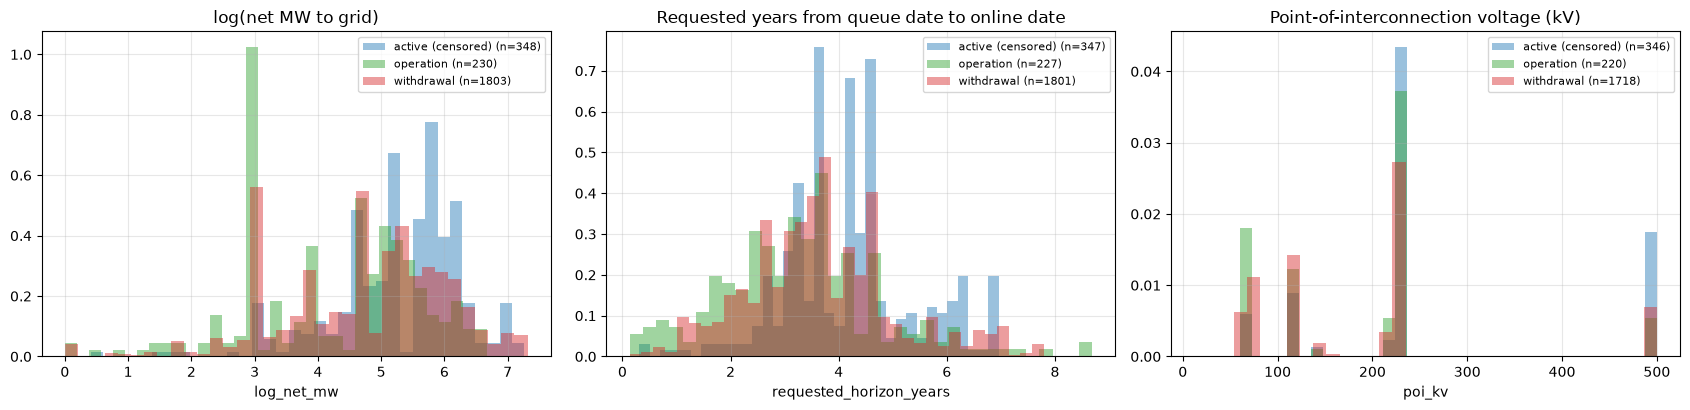

Values clipped at the 99.5th percentile for display only.


event                          active (censored)  operation  withdrawal
log_net_mw              count            348.000    230.000    1803.000
                        mean               5.292      4.255       4.704
                        std                1.009      1.343       1.332
                        min                0.405      0.000       0.000
                        25%                4.698      3.045       3.895
                        50%                5.525      4.615       4.844
                        75%                5.994      5.303       5.707
                        max                8.071      6.746       8.007
requested_horizon_years count            347.000    227.000    1801.000
                        mean               4.190      3.328       3.676
                        std                1.199      1.548       1.400
                        min                0.312      0.134       0.131
                        25%                3.463      2.419       2.754
                        50%                4.129      3.253       3.628
                        75%                4.630      4.088       4.463
                        max                6.962     10.790      13.582
poi_kv                  count            346.000    220.000    1718.000
                        mean             262.202    191.882     190.745
                        std              136.878    108.183     122.346
                        min               60.000     60.000      12.000
                        25%              230.000    115.000     115.000
                        50%              230.000    230.000     220.000
                        75%              230.000    230.000     230.000
                        max              525.000    500.000     525.000

In [33]:
# --- 9.2 Numeric feature distributions by outcome.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, label in [(axes[0], "log_net_mw", "log(net MW to grid)"), (axes[1], "requested_horizon_years", "Requested years from queue date to online date"),
                       (axes[2], "poi_kv", "Point-of-interconnection voltage (kV)")]:
    for ev, name in sd.EVENT_LABELS.items():
        v = analysis.loc[analysis["event"] == ev, col].dropna()
        ax.hist(v.clip(upper=v.quantile(0.995)), bins=35, alpha=0.45, density=True, label=f"{name} (n={len(v)})", color=EVENT_COLORS[ev])
    ax.set(title=label, xlabel=col); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Values clipped at the 99.5th percentile for display only.")
display(analysis.groupby(analysis["event"].map(sd.EVENT_LABELS))[["log_net_mw", "requested_horizon_years", "poi_kv"]].describe().T)

**Interpretation.**
* **Operational projects are smaller and request shorter timelines** (median 4.6 log-MW, about 100 MW, and 3.3 requested years) than active ones (median 5.5, about 250 MW, and 4.1 years), with withdrawn projects in between. These differences are partly era effects: active projects are recent, and recent projects are bigger.
* **Voltage is highly concentrated:** 230 kV is the most common level (the median for both resolved outcomes). Active projects connect at higher voltage (mean 262 kV versus 191 kV) because of recent 500 kV projects.
* **Distributions overlap heavily.** No numeric feature separates the three states cleanly; the signal is a shift in the center, not a boundary. Expect modest discrimination.
* Size has a small number of zero-MW records and a few extremes. Using log size, as here, handles the skew.

HR                    p           
cause                      operation withdrawal operation withdrawal
feature                                                             
log_net_mw (per SD)            0.683      0.963     0.000      0.392
requested_horizon (per SD)     0.705      0.934     0.000      0.002
poi_kv (per SD)                0.840      0.876     0.081      0.000
n_components                   0.229      0.540     0.000      0.001
is_solar                       1.396      1.074     0.010      0.444
is_hybrid                      0.227      0.516     0.000      0.000
has_storage                    0.234      0.566     0.000      0.000
poi_is_line                    1.287      1.356     0.118      0.000
fuel_gas                       1.762      1.482     0.068      0.023
fuel_wind                      0.558      0.963     0.001      0.839
service: Energy Only           0.443      0.684     0.000      0.072
service: Partial Capacity      0.384      0.098     0.000      0.000
service: not recorded          1.760      1.774     0.007      0.000
process: fast_track            3.587      0.945     0.000      0.512
process: serial                0.968      1.503     0.848      0.007
process: transition            0.956      0.369     0.696      0.000

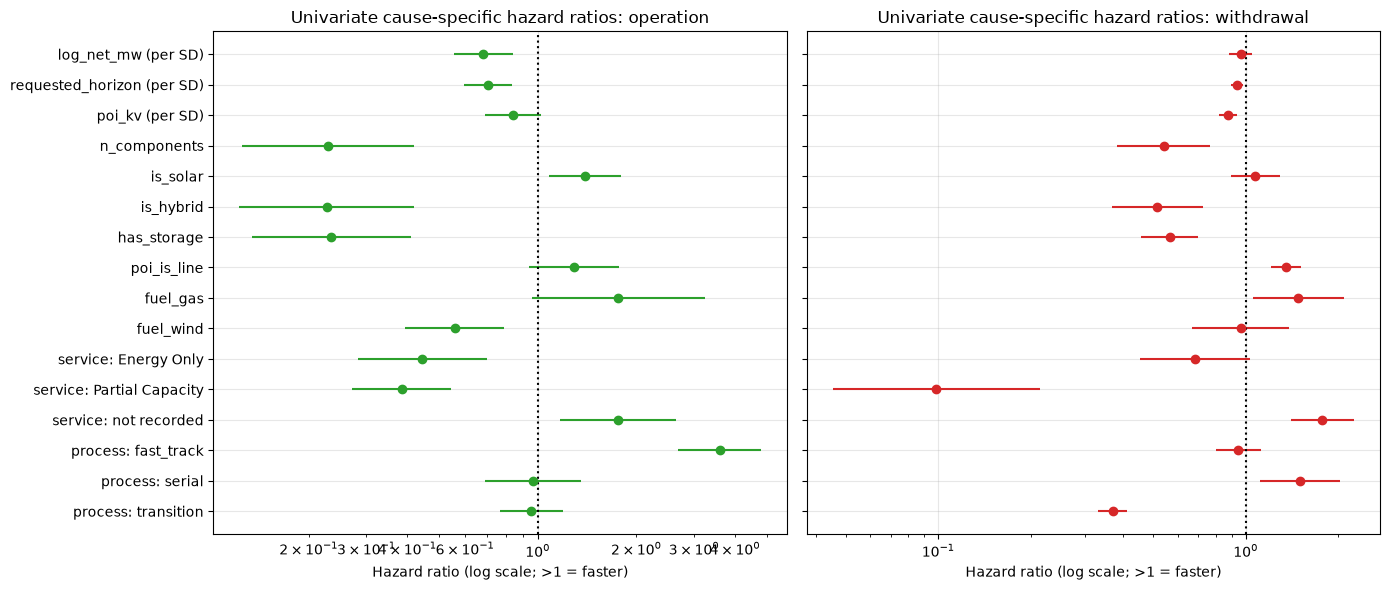

observed_group1  expected_group1    chi2  p_value
feature     cause                                                        
has_storage operation                73          151.262 120.541    0.000
            withdrawal              720          970.116 141.796    0.000
is_solar    operation               128          109.042   6.318    0.012
            withdrawal              851          819.151   2.281    0.131
is_hybrid   operation                42          108.848  83.240    0.000
            withdrawal              319          524.739 116.656    0.000
poi_is_line operation                44           35.759   2.263    0.132
            withdrawal              388          303.546  28.392    0.000

In [34]:
# --- 9.3 Build the modeling design matrix (descriptive use only) and run univariate cause-specific Cox models.
def design(frame):
    # Numeric features are standardized (z-scores) so hazard ratios mean 'per one standard deviation'.
    X = pd.DataFrame(index=frame.index)
    z = lambda s: (s - s.mean()) / s.std()
    X["log_net_mw (per SD)"] = z(frame["log_net_mw"])
    X["requested_horizon (per SD)"] = z(frame["requested_horizon_years"].fillna(frame["requested_horizon_years"].median()))
    X["poi_kv (per SD)"] = z(frame["poi_kv"].fillna(frame["poi_kv"].median()))
    X["n_components"] = frame["n_components"]
    for col in ["is_solar", "is_hybrid", "has_storage", "poi_is_line"]:
        X[col] = frame[col]
    X["fuel_gas"] = (frame["fuel_1"] == "Natural Gas").astype(int)
    X["fuel_wind"] = (frame["fuel_1"] == "Wind Turbine").astype(int)
    X["service: Energy Only"] = (frame["service_type"] == "Energy Only").astype(int)
    X["service: Partial Capacity"] = (frame["service_type"] == "Partial Capacity").astype(int)
    X["service: not recorded"] = (frame["service_type"] == "Missing").astype(int)  # 'Missing' is a category created at load time
    for g in ["fast_track", "serial", "transition"]:
        X[f"process: {g}"] = (frame["study_group"] == g).astype(int)
    return X


X_all = design(analysis)
MODEL_COLS = list(X_all.columns)


def fit_cox(frame, X, cause, cols, penalizer=0.0, use_entry=True, robust=True, strata=None):
    # Cause-specific Cox model; the competing outcome and active status are censored.
    df = X[cols].copy()
    df["T"], df["E"], df["entry"] = frame["duration_years"], (frame["event"] == cause).astype(int), frame["entry_years"]
    df["cohort"] = frame["cohort"]
    if strata is not None:
        df["stratum"] = strata
    df = df.loc[:, (df.nunique() > 1) | df.columns.isin(["T", "E", "entry", "cohort"])]
    kwargs = dict(duration_col="T", event_col="E")
    if use_entry:
        kwargs["entry_col"] = "entry"
    if robust:
        kwargs.update(cluster_col="cohort", robust=True)
    if strata is not None:
        kwargs["strata"] = ["stratum"]
    drop = [c for c in ["entry", "cohort"] if (c not in kwargs.values()) and c in df]
    cph = CoxPHFitter(penalizer=penalizer).fit(df.drop(columns=drop), **kwargs)
    return cph, df


rows = []
for cause, name in [(1, "operation"), (2, "withdrawal")]:
    for col in MODEL_COLS:
        try:
            cph, _ = fit_cox(analysis, X_all, cause, [col])
            s = cph.summary.loc[col]
            rows.append({"cause": name, "feature": col, "HR": s["exp(coef)"], "lower": s["exp(coef) lower 95%"], "upper": s["exp(coef) upper 95%"], "p": s["p"]})
        except Exception as exc:
            rows.append({"cause": name, "feature": col, "HR": np.nan, "lower": np.nan, "upper": np.nan, "p": np.nan})
uni = pd.DataFrame(rows)
uni_wide = uni.pivot(index="feature", columns="cause", values=["HR", "p"]).reindex(MODEL_COLS)
display(uni_wide)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, name, color in [(axes[0], "operation", "tab:green"), (axes[1], "withdrawal", "tab:red")]:
    u = uni[uni["cause"] == name].set_index("feature").reindex(MODEL_COLS)[::-1]
    ax.errorbar(u["HR"], range(len(u)), xerr=[u["HR"] - u["lower"], u["upper"] - u["HR"]], fmt="o", color=color)
    ax.axvline(1, color="k", ls=":"); ax.set_xscale("log"); ax.set_yticks(range(len(u))); ax.set_yticklabels(u.index)
    ax.set(title=f"Univariate cause-specific hazard ratios: {name}", xlabel="Hazard ratio (log scale; >1 = faster)")
plt.tight_layout(); plt.show()

# Log-rank tests for the binary features (a model-free check on the same question).
lr_rows = []
for col in ["has_storage", "is_solar", "is_hybrid", "poi_is_line"]:
    for cause, name in [(1, "operation"), (2, "withdrawal")]:
        r = sd.cause_logrank(*arrs(analysis)[:2], analysis[col], cause, arrs(analysis)[2])
        lr_rows.append({"feature": col, "cause": name, **r})
display(pd.DataFrame(lr_rows).set_index(["feature", "cause"]))

**Interpretation.**
* **Storage, hybrid projects, and multi-component projects have much lower hazards for both outcomes.** Operation: storage HR 0.23, hybrid 0.23, three-component projects 0.23 (per additional component); withdrawal: 0.57, 0.52, and 0.54. They stay in the queue longer: slower to operate *and* slower to withdraw.
* **Bigger projects are slower to operate** (HR 0.68 per standard deviation, p < 0.001) with essentially no effect on withdrawal (0.96, p = 0.39).
* **Process type is a strong signal:** fast-track projects operate 3.6 times faster, serial-process projects withdraw 1.5 times faster, and transition projects withdraw 0.37 times as fast. Partial Capacity projects have a withdrawal hazard of 0.098, practically never withdrawing.
* **"Service not recorded" is associated with faster operation and faster withdrawal (HRs 1.76 and 1.77),** which confirms it is an old-record marker rather than a project trait.
* The log-rank tests agree for the binary features: storage and hybrid projects have far fewer events than expected for both outcomes (for example 73 operations observed versus 151 expected under no storage effect).
* **All of these are marginal (unadjusted) effects** and are tangled with era (Section 7.5). The next steps adjust for that.

operation: events = 230, concordance (descriptive, in-sample) = 0.837


withdrawal: events = 1803, concordance (descriptive, in-sample) = 0.638


operation       withdrawal      
                           exp(coef)     p  exp(coef)     p
covariate                                                  
log_net_mw (per SD)            0.910 0.249      1.185 0.001
requested_horizon (per SD)     0.813 0.000      0.939 0.298
poi_kv (per SD)                1.150 0.011      0.840 0.000
is_hybrid                      0.459 0.000      0.837 0.307
has_storage                    0.461 0.001      0.597 0.007
is_solar                       1.221 0.303      0.982 0.880
fuel_gas                       1.291 0.130      1.008 0.946
fuel_wind                      0.539 0.012      0.778 0.016
service: Energy Only           0.246 0.000      0.655 0.073
service: Partial Capacity      0.618 0.054      0.129 0.000
service: not recorded          1.719 0.001      4.106 0.012
process: fast_track            2.718 0.000      0.764 0.022
process: serial                0.466 0.012      0.238 0.020
process: transition            0.903 0.348      0.272 0.000
poi_is_line                    1.179 0.244      1.303 0.000

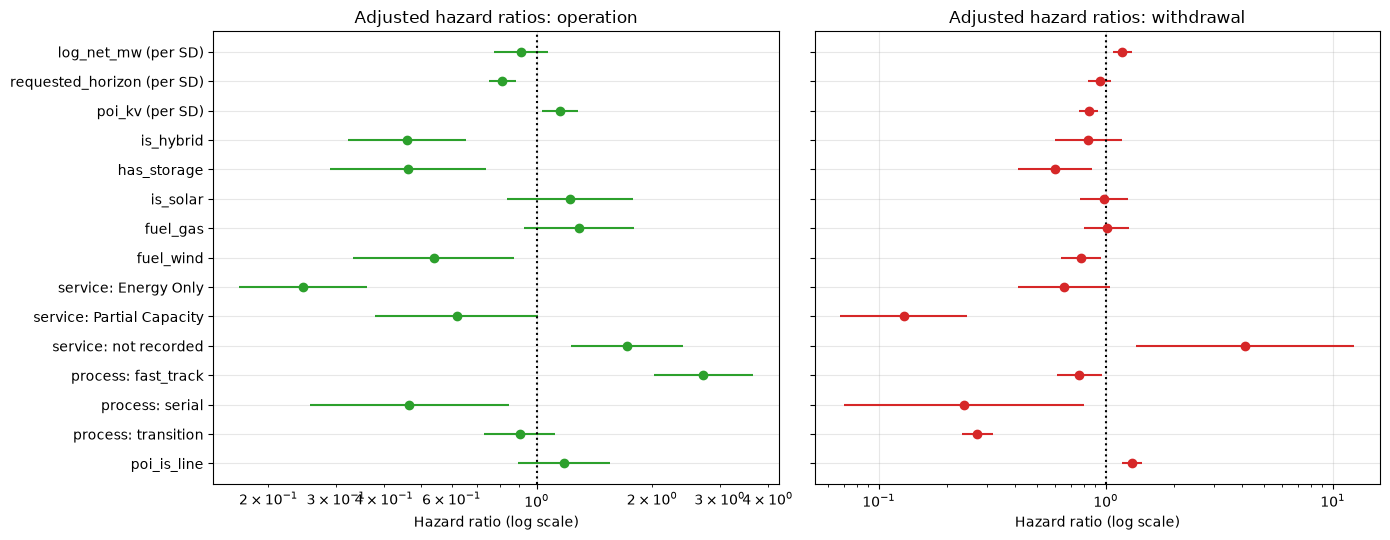

In [35]:
# --- 9.4 Multivariable cause-specific Cox: effects after adjusting for the other features.
MULTI = ["log_net_mw (per SD)", "requested_horizon (per SD)", "poi_kv (per SD)", "is_hybrid", "has_storage", "is_solar", "fuel_gas", "fuel_wind",
         "service: Energy Only", "service: Partial Capacity", "service: not recorded", "process: fast_track", "process: serial", "process: transition", "poi_is_line"]
multi = {}
for cause, name in [(1, "operation"), (2, "withdrawal")]:
    cph, _ = fit_cox(analysis, X_all, cause, MULTI, penalizer=0.01)
    multi[name] = cph
    print(f"{name}: events = {int(cph.event_observed.sum())}, concordance (descriptive, in-sample) = {cph.concordance_index_:.3f}")
mt = pd.concat({name: m.summary[["exp(coef)", "p"]] for name, m in multi.items()}, axis=1)
display(mt.reindex(MULTI))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for ax, (name, color) in zip(axes, [("operation", "tab:green"), ("withdrawal", "tab:red")]):
    s = multi[name].summary.reindex(MULTI)[::-1]
    ax.errorbar(s["exp(coef)"], range(len(s)), xerr=[s["exp(coef)"] - s["exp(coef) lower 95%"], s["exp(coef) upper 95%"] - s["exp(coef)"]], fmt="o", color=color)
    ax.axvline(1, color="k", ls=":"); ax.set_xscale("log"); ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index)
    ax.set(title=f"Adjusted hazard ratios: {name}", xlabel="Hazard ratio (log scale)")
plt.tight_layout(); plt.show()

**Interpretation.**
* **After adjustment, storage and hybrid effects remain for operation** (storage HR 0.46, hybrid 0.46) and **storage remains for withdrawal (HR 0.60);** hybrid alone no longer matters for withdrawal (HR 0.84, p = 0.31). Storage and hybrid are correlated (r = 0.57), so their effects are partly shared.
* **Energy-only service strongly slows operation (HR 0.25).** Fast-track operates 2.7 times faster. Wind is slower on both outcomes (0.54 and 0.78).
* **Size reverses sign for withdrawal once other features are controlled** (univariate 0.96, adjusted 1.19, p = 0.001), because size is correlated with voltage (r = 0.61), and higher voltage projects withdraw less (HR 0.84). Adjusted coefficients for correlated features should be interpreted with caution.
* **In-sample concordance is 0.84 for operation and 0.64 for withdrawal.** The operation figure is flattered by era markers (process type and "service not recorded"), not by physical project traits. The withdrawal figure is a more honest picture: modest.
* **These are associations, not causes.** For example, "storage halves the operation hazard" does not mean adding storage to a project halves its chances; storage projects are a different, more recent population.

,operation,withdrawal,violates_operation,violates_withdrawal
log_net_mw (per SD),0.000,0.732,True,False
requested_horizon (per SD),0.011,0.015,False,False
poi_kv (per SD),0.001,0.863,True,False
is_hybrid,0.274,0.054,False,False
has_storage,0.256,0.131,False,False
is_solar,0.049,0.011,False,False
fuel_gas,0.036,0.007,False,True
fuel_wind,0.277,0.360,False,False
service: Energy Only,0.430,0.000,False,True
service: Partial Capacity,0.026,0.447,False,False


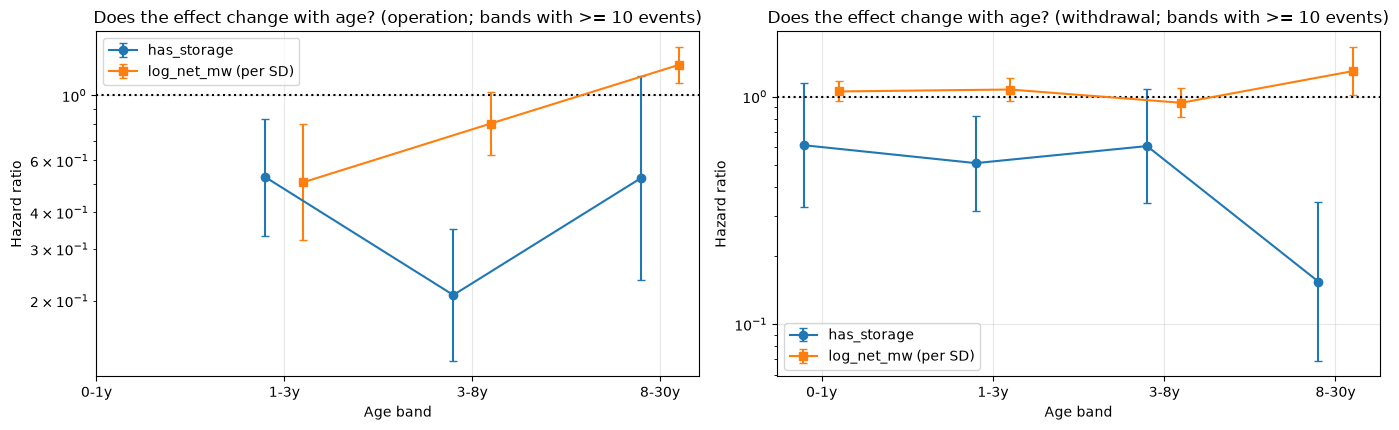

HR  lower  upper  events
cause      feature             band                             
operation  has_storage         0-1y  0.662  0.457  0.957       7
                               1-3y  0.526  0.333  0.832      17
                               3-8y  0.209  0.125  0.350     140
                               8-30y 0.523  0.236  1.161      66
           log_net_mw (per SD) 0-1y  0.727  0.469  1.126       7
                               1-3y  0.506  0.321  0.797      17
                               3-8y  0.802  0.629  1.022     140
                               8-30y 1.269  1.103  1.460      66
withdrawal has_storage         0-1y  0.611  0.326  1.145     910
                               1-3y  0.510  0.315  0.825     565
                               3-8y  0.606  0.339  1.081     298
                               8-30y 0.154  0.069  0.343      30
           log_net_mw (per SD) 0-1y  1.052  0.952  1.164     910
                               1-3y  1.073  0.958  1.202     565
                               3-8y  0.938  0.811  1.086     298
                               8-30y 1.292  1.012  1.650      30

In [36]:
# --- 9.5 Proportional-hazards check. lifelines' PH test does not support delayed entry, so it is run on the
# restricted table (queued >= 2007, everyone enters at age 0) with the same features.
restricted = analysis[analysis["queue_date"] >= WINDOW_START]
X_res = design(restricted)
ph_rows = {}
for cause, name in [(1, "operation"), (2, "withdrawal")]:
    cph, df = fit_cox(restricted, X_res, cause, MULTI, penalizer=0.01, use_entry=False, robust=False)
    res = proportional_hazard_test(cph, df.drop(columns=[c for c in ["cohort", "entry"] if c in df]), time_transform="log")
    ph_rows[name] = res.summary["p"]
ph = pd.DataFrame(ph_rows).reindex(MULTI)
display(ph.assign(violates_operation=ph["operation"] < 0.01, violates_withdrawal=ph["withdrawal"] < 0.01))

# Visual check: hazard ratio of the key features within age bands (piecewise Cox).
def band_hr(frame, cause, col, lo, hi, adjust=("log_net_mw (per SD)",)):
    sub = frame[(frame["duration_years"] > lo) & (frame["entry_years"] < hi)].copy()  # at risk at some age inside the band
    sub["entry_years"] = np.maximum(sub["entry_years"], lo)
    sub["event"] = np.where(sub["duration_years"] > hi, 0, sub["event"])
    sub["duration_years"] = np.minimum(sub["duration_years"], hi)
    X = design(sub)
    cph, _ = fit_cox(sub, X, cause, [col, *adjust], penalizer=0.01)
    s = cph.summary.loc[col]
    return {"HR": s["exp(coef)"], "lower": s["exp(coef) lower 95%"], "upper": s["exp(coef) upper 95%"], "events": int(cph.event_observed.sum())}


bands_hr = [(0, 1), (1, 3), (3, 8), (8, 30)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
band_table = []
for ax, (cause, name, color) in zip(axes, [(1, "operation", "tab:green"), (2, "withdrawal", "tab:red")]):
    for col, marker in [("has_storage", "o"), ("log_net_mw (per SD)", "s")]:
        pts = []
        for lo, hi in bands_hr:
            try:
                r = band_hr(analysis, cause, col, lo, hi, adjust=("log_net_mw (per SD)",) if col != "log_net_mw (per SD)" else ("has_storage",))
            except Exception:
                r = {"HR": np.nan, "lower": np.nan, "upper": np.nan, "events": 0}
            pts.append({"feature": col, "cause": name, "band": f"{lo}-{hi}y", **r})
        pts = pd.DataFrame(pts); band_table.append(pts)
        ok = pts["events"] >= 10
        ax.errorbar(np.arange(len(pts))[ok] + (0.1 if marker == "s" else -0.1), pts.loc[ok, "HR"],
                    yerr=[pts.loc[ok, "HR"] - pts.loc[ok, "lower"], pts.loc[ok, "upper"] - pts.loc[ok, "HR"]], fmt=marker + "-", label=col, capsize=3)
    ax.axhline(1, color="k", ls=":"); ax.set_yscale("log"); ax.set_xticks(range(len(bands_hr))); ax.set_xticklabels([f"{a}-{b}y" for a, b in bands_hr])
    ax.set(title=f"Does the effect change with age? ({name}; bands with >= 10 events)", xlabel="Age band", ylabel="Hazard ratio"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.concat(band_table).set_index(["cause", "feature", "band"]))

**Interpretation.**
* **Proportional hazards holds for the key binary features** (storage p = 0.26 for operation and 0.13 for withdrawal, hybrid p = 0.27 and 0.054) but **fails for project size and voltage in the operation model** (p < 0.001 and p = 0.001) and for gas fuel, energy-only service, and the transition process in the withdrawal model (p < 0.01).
* The age-band plot shows the same: **the effect of size on operation changes direction with age** (HR 0.73 and 0.51 early, 0.80 in years 3 to 8, then 1.27 after year 8, p < 0.05). A single hazard ratio for size would hide that.
* **The storage hazard ratio for operation is 0.66 early, 0.53 in years 1 to 3, 0.21 in years 3 to 8, and 0.52 after year 8** (wide interval): consistently below 1, but its strength varies by age.
* Operation hazard-ratio estimates before year 3 rest on only 24 events and should not be read closely.
* **Implications:** use stratification or interactions with age (or a model class with flexible time effects) for size and voltage. Storage can be modeled with a constant effect as a first approximation but not within eras (Section 9.8).

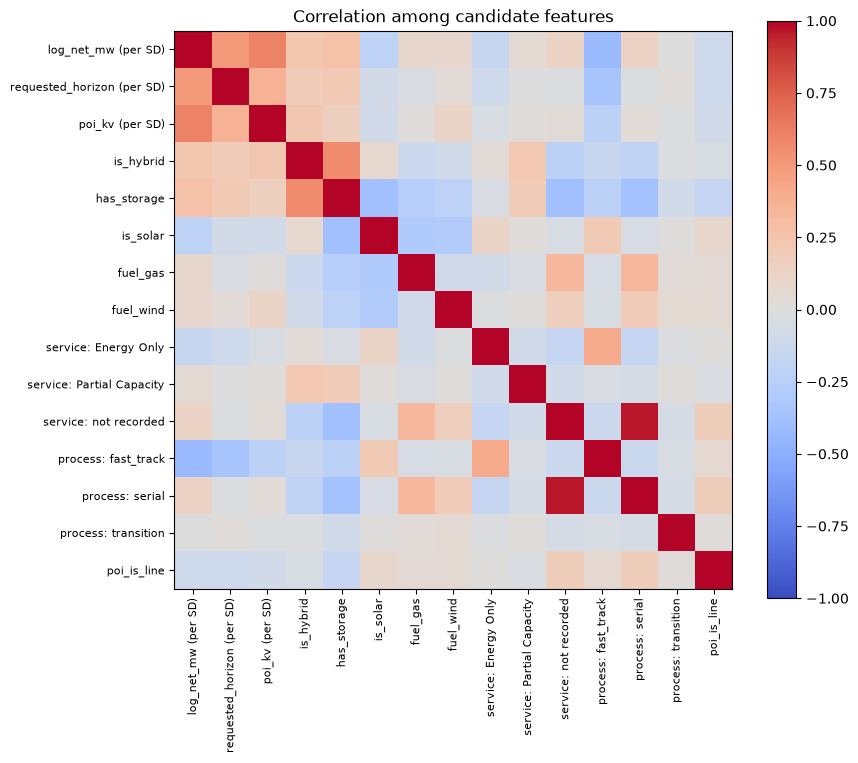

,VIF
process: serial,14.115
service: not recorded,14.049
has_storage,4.321
is_solar,2.931
log_net_mw (per SD),2.179
is_hybrid,2.173
fuel_gas,1.986
fuel_wind,1.838
poi_kv (per SD),1.643
process: fast_track,1.509


correlation
service: not recorded process: serial                   0.962
log_net_mw (per SD)   poi_kv (per SD)                   0.605
is_hybrid             has_storage                       0.566
log_net_mw (per SD)   requested_horizon (per SD)        0.500
                      process: fast_track              -0.420

In [37]:
# --- 9.6 Collinearity: correlation heatmap and variance inflation factors for the multivariable feature set.
Xc = X_all[MULTI]
corr = Xc.corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
plt.colorbar(im, ax=ax); ax.set_title("Correlation among candidate features"); plt.show()

vif = {}
for col in MULTI:
    others = Xc.drop(columns=col)
    r2 = LinearRegression().fit(others, Xc[col]).score(others, Xc[col])
    vif[col] = 1 / (1 - r2) if r2 < 1 else np.inf
display(pd.Series(vif, name="VIF").sort_values(ascending=False).to_frame())
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("correlation")
display(pairs[pairs.abs() > 0.4].sort_values(key=abs, ascending=False).to_frame())

**Interpretation.**
* **Two features are almost the same variable:** "service not recorded" and the serial process (r = 0.96, VIF about 14). Both identify the oldest records. Keep neither as a free predictor; era stratification covers it.
* **Moderate correlations that are real:** size and voltage (0.61), hybrid and storage (0.57, because hybrids contain storage), size and requested timeline (0.50), and size and fast-track (-0.42).
* After removing the era markers, the VIFs of the remaining features are all below about 4.3, so collinearity is manageable with penalization and does not need dropping features.
* **Rule for the modeling plan:** drop one of the two era markers (or replace both with explicit era strata), and keep storage and hybrid together with a note that their separate effects are not cleanly identified.

,levels,levels with >= 20 resolved projects,share of projects in thin levels (<20 resolved),share of C15 projects in thin or unseen levels
feature,,,,
fuel_1,14,6,0.017,0.012
type_1,13,7,0.018,0.012
service_type,4,4,0.000,0.000
utility,12,4,0.028,0.182
state,8,3,0.011,0.000
county,103,20,0.180,0.241
study_group,5,4,0.000,0.000


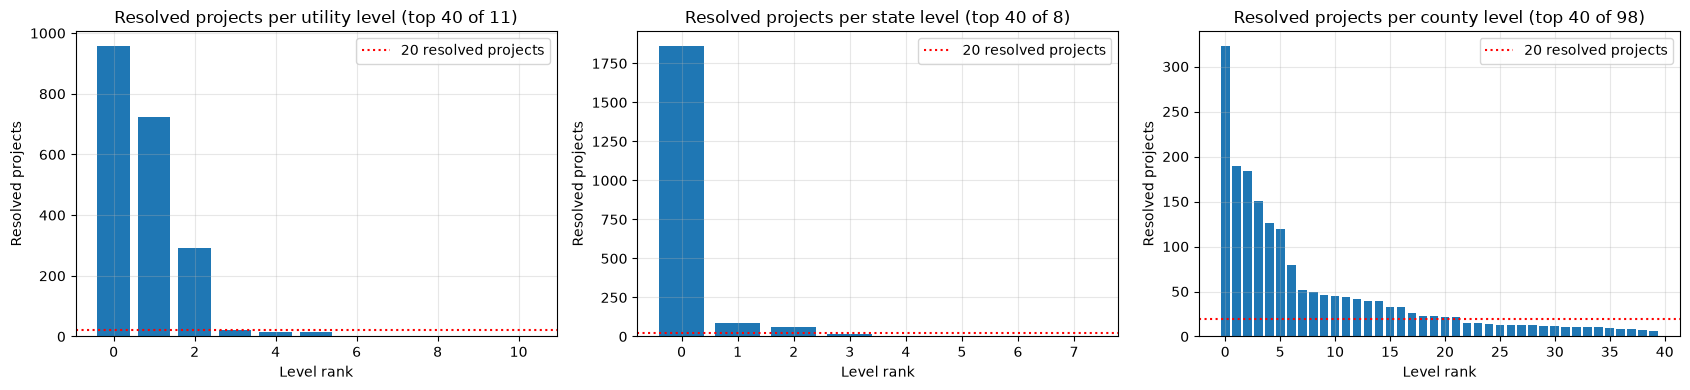

In [38]:
# --- 9.7 Categorical features: sparsity, events per level, and coverage in Cluster 15.
rows = []
older = analysis[~is15]
for col in sd.SURVIVAL_CATEGORICAL:
    ev_per_level = older[older["event"] > 0].groupby(col).size()
    level_n = analysis.groupby(col).size()
    thin_levels = ev_per_level[ev_per_level < 20].index
    c15_vals = analysis.loc[is15, col]
    rows.append({"feature": col, "levels": level_n.size, "levels with >= 20 resolved projects": int((ev_per_level >= 20).sum()),
                 "share of projects in thin levels (<20 resolved)": analysis[col].isin(thin_levels).mean(),
                 "share of C15 projects in thin or unseen levels": (c15_vals.isin(thin_levels) | ~c15_vals.isin(older[col].dropna().unique())).mean()})
display(pd.DataFrame(rows).set_index("feature"))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["utility", "state", "county"]):
    counts = analysis[analysis["event"] > 0].groupby(col).size().sort_values(ascending=False)
    ax.bar(range(min(len(counts), 40)), counts.values[:40]); ax.axhline(20, color="r", ls=":", label="20 resolved projects")
    ax.set(title=f"Resolved projects per {col} level (top 40 of {len(counts)})", xlabel="Level rank", ylabel="Resolved projects"); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation.**
* **County is too sparse to use directly:** 103 levels, only 20 have at least 20 resolved projects, and 18% of projects (24% of Cluster 15) sit in thin or unseen levels.
* **Utility is also thin:** 12 levels, only 4 with at least 20 resolved projects; 18% of Cluster 15 projects belong to utilities that are thin or never seen before (WAPA, HWT, LSPC).
* **Fuel and type are well covered** (1% to 2% of projects in thin levels) and state and service type are fine.
* **Recommendation:** group utilities and counties into a few regions (or drop them), treat rare and new levels as "other", and avoid one-hot encoding of county.

,,projects,storage_share,events,HR_storage,lower,upper
cause,era,,,,,,
operation,2007-2012,971,0.044,136,0.125,0.058,0.269
withdrawal,2007-2012,971,0.044,806,0.057,0.024,0.134
operation,2013-2016,398,0.447,61,0.396,0.145,1.081
withdrawal,2013-2016,398,0.447,306,0.501,0.334,0.751
operation,2017+ (incl. C15),1012,0.869,33,0.352,0.115,1.073
withdrawal,2017+ (incl. C15),1012,0.869,691,0.785,0.462,1.333


operation: Cochran Q = 4.1 on 2 d.f., p = 0.1291; pooled HR = 0.22
withdrawal: Cochran Q = 26.9 on 2 d.f., p = 0.0000; pooled HR = 0.44


HR_storage  lower  upper
cause      model                                           
operation  unadjusted (size only)       0.299  0.184  0.486
           stratified by era            0.310  0.170  0.565
withdrawal unadjusted (size only)       0.554  0.442  0.696
           stratified by era            0.489  0.342  0.700

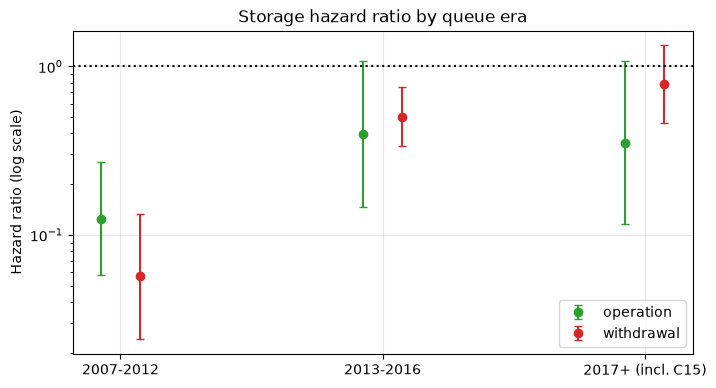

In [39]:
# --- 9.8 Era confounding: is the storage effect the same across eras?
cohort_era = pd.cut(analysis["queue_year"], [0, 2012, 2016, 2100], labels=["2007-2012", "2013-2016", "2017+ (incl. C15)"])
rows = []
for era_label in cohort_era.cat.categories:
    sub = analysis[cohort_era == era_label]
    for cause, name in [(1, "operation"), (2, "withdrawal")]:
        X_sub = design(sub)
        try:
            cph, _ = fit_cox(sub, X_sub, cause, ["has_storage", "log_net_mw (per SD)"], penalizer=0.01)
            s = cph.summary.loc["has_storage"]
            rows.append({"era": era_label, "cause": name, "projects": len(sub), "storage_share": sub["has_storage"].mean(), "events": int(cph.event_observed.sum()),
                         "HR_storage": s["exp(coef)"], "lower": s["exp(coef) lower 95%"], "upper": s["exp(coef) upper 95%"], "log_HR": s["coef"], "se": s["se(coef)"]})
        except Exception as exc:
            rows.append({"era": era_label, "cause": name, "projects": len(sub), "storage_share": sub["has_storage"].mean(), "events": int(sub["event"].eq(cause).sum())})
era_hr = pd.DataFrame(rows)
display(era_hr[["era", "cause", "projects", "storage_share", "events", "HR_storage", "lower", "upper"]].set_index(["cause", "era"]))

# Cochran's Q: are the era-specific log hazard ratios equal? (small p = the storage effect depends on era)
for name in ["operation", "withdrawal"]:
    e = era_hr[(era_hr["cause"] == name) & era_hr["se"].notna()]
    w = 1 / e["se"] ** 2
    pooled = (w * e["log_HR"]).sum() / w.sum()
    q = (w * (e["log_HR"] - pooled) ** 2).sum()
    print(f"{name}: Cochran Q = {q:.1f} on {len(e) - 1} d.f., p = {stats.chi2.sf(q, len(e) - 1):.4f}; pooled HR = {np.exp(pooled):.2f}")

# How much does adjusting for era change the pooled storage effect?
cmp_rows = []
for cause, name in [(1, "operation"), (2, "withdrawal")]:
    for label, strata in [("unadjusted (size only)", None), ("stratified by era", cohort_era.astype(str))]:
        cph, _ = fit_cox(analysis, X_all, cause, ["has_storage", "log_net_mw (per SD)"], penalizer=0.01, strata=strata)
        s = cph.summary.loc["has_storage"]
        cmp_rows.append({"cause": name, "model": label, "HR_storage": s["exp(coef)"], "lower": s["exp(coef) lower 95%"], "upper": s["exp(coef) upper 95%"]})
display(pd.DataFrame(cmp_rows).set_index(["cause", "model"]))

fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (name, color) in enumerate([("operation", "tab:green"), ("withdrawal", "tab:red")]):
    e = era_hr[(era_hr["cause"] == name) & era_hr["se"].notna()]
    ax.errorbar(np.arange(len(e)) + (k - 0.5) * 0.15, e["HR_storage"], yerr=[e["HR_storage"] - e["lower"], e["upper"] - e["HR_storage"]], fmt="o", color=color, label=name, capsize=3)
ax.axhline(1, color="k", ls=":"); ax.set_yscale("log"); ax.set_xticks(range(3)); ax.set_xticklabels(cohort_era.cat.categories)
ax.set(title="Storage hazard ratio by queue era", ylabel="Hazard ratio (log scale)"); ax.legend(); plt.show()

**Interpretation.**
* **The storage hazard ratio for withdrawal depends strongly on era:** 0.06 for 2007 to 2012 (only 4% storage, about 43 projects, so this reflects a small special group), 0.50 for 2013 to 2016, and **0.79 (95% interval 0.46 to 1.33, not different from 1) for 2017 and later.** Heterogeneity is highly significant (Cochran's Q p < 0.0001).
* For operation the estimates are 0.13, 0.40, and 0.35, in the same direction but statistically indistinguishable across eras (p = 0.13); the later two have wide intervals including 1.
* **The pooled value (0.55 for withdrawal) describes no era well,** and stratifying by era shifts it to 0.49. In the recent regime, which is the one the screener will face, **storage is no longer clearly protective against withdrawal.**
* This is the most important feature-level finding in the notebook. Storage seemed to be a strong reliable feature in the pooled data and in the earlier classifier; it is actually **an effect that fades as storage becomes the norm.**
* **Implication:** the model must either let the storage effect depend on era, or be trained on the recent regime only, and evaluated on later clusters. A single global storage coefficient would overstate its value for Cluster 15.

**Decision: how to handle era in the later model (recommendation).** Because effects (especially storage) are era-dependent, do not
treat "era" as an ordinary covariate. Use one or more of: *stratify the baseline hazard by era or cohort group*; fit models on the
recent regime (about 2013 onward); include explicit interactions; and evaluate always on *later* cohorts than the training cohorts.

## 10. Leakage and eligibility audit

**Purpose.** For every column in the workbooks, state whether it may be used as a model input at the moment the screener scores a project,
and prove the exclusions with data.

**Why it matters.** Survival data are *more* prone to leakage than ordinary tabular data. Any field filled in after the queue date (a study
result, an agreement status) exists only for projects that *survived long enough to reach that milestone*. Using it as a baseline feature
gives the model knowledge of the future, a mistake called **immortal-time bias**: the project's survival time is credited to the feature
that merely *reflects* survival.

**Key terms.**
* *Queue-entry feature*: information available when the project is first screened.
* *Post-entry milestone*: information created later (study results, agreement status, updated schedules).
* *Time-varying covariate*: the legitimate way to use a milestone: the feature changes value at the date it is reached, and a project is
  only credited with it *from then on*. This requires the date of each milestone; the workbooks provide mostly statuses without dates.

In [40]:
audit_rows = []
cat_notes = {
    "queue-entry (usable)": ["log_net_mw", "n_components", "poi_kv", "requested_horizon_years", "is_solar", "is_hybrid", "has_storage", "zero_mw",
                             "horizon_invalid", "poi_kv_missing", "poi_is_line", "fuel_1", "type_1", "service_type", "utility", "state", "county", "study_group"],
}
for col in sd.SURVIVAL_FEATURES:
    audit_rows.append({"column": col, "class": "queue-entry (usable)", "why": "Filed at or before queue entry; present for both workbooks"})
for col, why in cd.LEAKAGE_COLUMNS.items():
    audit_rows.append({"column": col, "class": "excluded: post-entry or outcome", "why": why})
audit_rows += [
    {"column": "queue_date / queue_year", "class": "time origin / era descriptor", "why": "Defines the clock. Queue year is an era proxy: allowed for stratification and evaluation splits, not as a free predictor"},
    {"column": "cohort", "class": "grouping variable", "why": "Used for clustering, stratification, and splits; a future cohort has no history, so it cannot be a predictor"},
    {"column": "ir_receive_date", "class": "excluded", "why": "Receipt date is recorded inconsistently across sheets (see the classifier notebook); used only as an alternative origin in Section 6.5"},
    {"column": "snapshot_date, source, source_sheet, duration, event", "class": "excluded: construction fields", "why": "Created by the survival-table build; they restate the outcome and follow-up"},
    {"column": "voltage_kv (Cluster 15 only)", "class": "queue-entry (merged into poi_kv)", "why": "Cluster 15's explicit kV used where the station-string parse is missing"},
]
display(pd.DataFrame(audit_rows).set_index("column"))

,class,why
column,,
log_net_mw,queue-entry (usable),Filed at or before queue entry; present for bo...
n_components,queue-entry (usable),Filed at or before queue entry; present for bo...
poi_kv,queue-entry (usable),Filed at or before queue entry; present for bo...
requested_horizon_years,queue-entry (usable),Filed at or before queue entry; present for bo...
is_solar,queue-entry (usable),Filed at or before queue entry; present for bo...
is_hybrid,queue-entry (usable),Filed at or before queue entry; present for bo...
has_storage,queue-entry (usable),Filed at or before queue entry; present for bo...
zero_mw,queue-entry (usable),Filed at or before queue entry; present for bo...
horizon_invalid,queue-entry (usable),Filed at or before queue entry; present for bo...


**Interpretation.**
* **18 columns are usable** (all known at queue entry and present in both workbooks); **19 are excluded** because they are filled in after entry, restate the outcome, or are identifiers.
* Some columns have a **special status**: `queue_year` and `cohort` describe *when*, and are used for stratification, clustering, and splitting rather than as predictors.
* The receipt-date field is excluded as a predictor but used as an alternative time origin in the sensitivity analysis.

event,active (censored),operation,withdrawal
ia_status,0.828,0.974,0.049
phase1_study,0.992,0.943,0.460
phase2_study,0.989,0.943,0.224
feasibility_study,0.031,0.117,0.127
optional_study,0.000,0.022,0.002
tpd_allocation_percentage,0.191,0.074,0.000
off_peak_deliverability,0.687,0.904,0.118
current_online_date,1.000,0.000,0.997
suspension_status,0.004,0.000,0.000
reason_for_withdrawal,0.000,0.000,0.399


,class,AUC
field,,
current_online_date is present,post-entry,0.999
ia_status is present,post-entry,0.963
off_peak_deliverability is present,post-entry,0.893
phase2_study is present,post-entry,0.860
phase1_study is present,post-entry,0.742
pto_study_region is present,post-entry,0.730
reason_for_withdrawal is present,post-entry,0.700
log_net_mw,queue-entry,0.586
requested_horizon_years,queue-entry,0.566


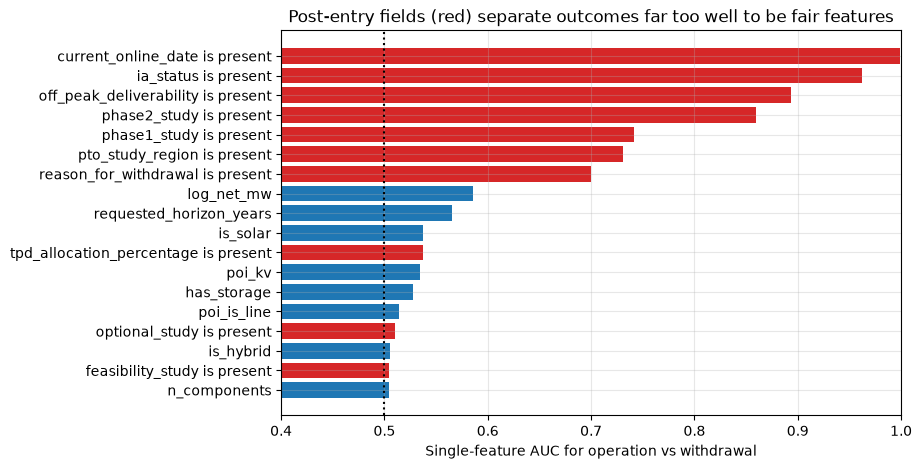

age_band,"(0, 1]","(1, 2]","(2, 3]","(3, 5]","(5, 30]"
share with Phase I study recorded,0.219,0.535,0.647,0.885,0.945
withdrawn projects,848.000,404.000,139.000,182.000,146.000


In [41]:
# Proof 1: excluded post-entry fields are present or absent depending on the outcome (the data-recording process, not project merit).
c14_rows = projects.loc[analysis.index].query("source == 'C14 workbook'")
leak_cols = ["ia_status", "phase1_study", "phase2_study", "feasibility_study", "optional_study", "tpd_allocation_percentage", "off_peak_deliverability",
             "current_online_date", "suspension_status", "reason_for_withdrawal", "pto_study_region"]
presence = pd.DataFrame({col: c14_rows[col].notna().groupby(analysis.loc[c14_rows.index, "event"].map(sd.EVENT_LABELS)).mean() for col in leak_cols}).T
display(presence)

# Proof 2: single-feature separation of operation vs withdrawal among resolved Cluster 14-workbook projects (AUC; 0.5 = no information).
resolved = analysis.loc[c14_rows.index][analysis.loc[c14_rows.index, "event"] > 0]
y = (resolved["event"] == 1).astype(int)
auc_rows = []
for col in leak_cols:
    ind = projects.loc[resolved.index, col].notna().astype(int)
    if ind.nunique() > 1:
        a = roc_auc_score(y, ind); auc_rows.append({"field": f"{col} is present", "class": "post-entry", "AUC": max(a, 1 - a)})
for col in ["log_net_mw", "requested_horizon_years", "poi_kv", "has_storage", "is_solar", "is_hybrid", "poi_is_line", "n_components"]:
    v = resolved[col].fillna(resolved[col].median())
    a = roc_auc_score(y, v); auc_rows.append({"field": col, "class": "queue-entry", "AUC": max(a, 1 - a)})
auc_table = pd.DataFrame(auc_rows).sort_values("AUC", ascending=False).set_index("field")
display(auc_table)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(auc_table.index[::-1], auc_table["AUC"][::-1], color=["tab:red" if c == "post-entry" else "tab:blue" for c in auc_table["class"][::-1]])
ax.axvline(0.5, color="k", ls=":"); ax.set(xlim=(0.4, 1.0), xlabel="Single-feature AUC for operation vs withdrawal", title="Post-entry fields (red) separate outcomes far too well to be fair features")
plt.show()

# Proof 3: immortal-time bias. A milestone field is more often filled in for projects that lasted longer.
w = analysis.loc[c14_rows.index]
w = w[w["event"] == 2]
w = w.assign(has_phase1=projects.loc[w.index, "phase1_study"].notna(), age_band=pd.cut(w["duration_years"], [0, 1, 2, 3, 5, 30]))
display(w.groupby("age_band", observed=True)["has_phase1"].agg(["mean", "size"]).rename(columns={"mean": "share with Phase I study recorded", "size": "withdrawn projects"}).T)

**Interpretation.**
* **Post-entry fields reveal the outcome through their pattern of presence.** An interconnection-agreement status exists for 97% of operational projects, 83% of active ones, and only 5% of withdrawn ones. Phase I study results exist for 94% of operational projects but 46% of withdrawn ones.
* **Single-feature AUCs make the leakage concrete:** a "has agreement status" flag alone separates operation from withdrawal with AUC 0.96; the current online date flag gives 0.999. **The best queue-entry feature (size) has AUC 0.59,** and the rest are 0.50 to 0.57. Queue-entry signal is real but weak, so there will always be a temptation to use leaky features. They must be kept out.
* **Immortal-time bias is visible in the last table:** among withdrawn projects, a Phase I study is recorded for 22% of projects that withdrew in their first year but **95% of those that lasted beyond five years.** A project does not survive because it has a Phase I study; it has a Phase I study because it survived long enough to get one.
* **Legitimate use of these fields** would be as time-varying covariates that switch on at the date each milestone is reached. The workbooks carry the status but not those dates, so this is currently not possible.

## 11. Sample-size and event-count feasibility

**Purpose.** Work out how many parameters each outcome's model can support and how large an effect must be to be detectable.

**Why it matters.** In survival analysis the effective sample size is not the number of projects; it is the **number of events of the
outcome being modeled**. A queue with 2,381 projects and 230 operations supports a model for operation of roughly 230 events' worth,
not 2,381. Overfitting risk is set by the *rarest* outcome.

**Key terms.**
* *Events per variable (EPV)*: events divided by the number of model parameters. A common guideline is at least 10 (Cox models can
  work with fewer when penalized).
* *Minimum detectable hazard ratio (MDHR)*: the smallest HR a feature could show at 80% power and 5% significance. For a binary
  feature with prevalence p among d events: HR_min = exp(2.8 / sqrt(d x p x (1 - p))) (Schoenfeld approximation).

,projects,operations,withdrawals,censored,EPV-10 parameter budget: operation,EPV-10 parameter budget: withdrawal
training window,,,,,,
All (delayed entry 2007+),2381,230,1803,348,23,180
Queued 2013 or later,1410,94,997,319,9,99
Queued 2017 or later,1012,33,691,288,3,69
Cluster 13 and later,675,2,447,226,0,44
Excluding Cluster 15,2211,230,1719,262,23,171


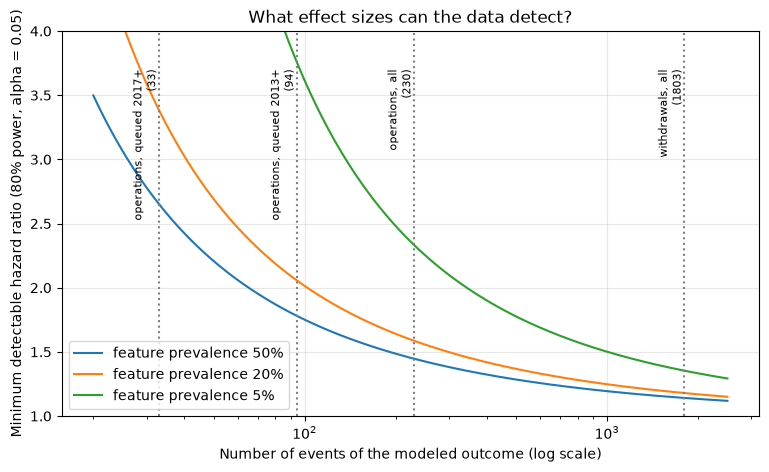

,events,MDHR at prevalence 50%,MDHR at prevalence 20%,MDHR at prevalence 5%
setting,,,,
"operations, all",230,1.447,1.587,2.333
"operations, queued 2013+",94,1.782,2.059,3.763
"operations, queued 2017+",33,2.651,3.382,9.360
"withdrawals, all",1803,1.141,1.179,1.353


,operation events,has_storage prevalence among operations,is_solar prevalence among operations,is_hybrid prevalence among operations,MDHR (storage)
training window,,,,,
All (delayed entry 2007+),230,0.317,0.557,0.183,1.487
Queued 2013 or later,94,0.660,0.436,0.319,1.839
Queued 2017 or later,33,0.667,0.273,0.273,2.812
Cluster 13 and later,2,0.500,0.500,0.500,52.447
Excluding Cluster 15,230,0.317,0.557,0.183,1.487


In [42]:
# --- 11.1 Events by outcome and period.
window_defs = {"All (delayed entry 2007+)": analysis, "Queued 2013 or later": analysis[analysis["queue_year"] >= 2013],
               "Queued 2017 or later": analysis[analysis["queue_year"] >= 2017], "Cluster 13 and later": analysis[analysis["cohort"].isin(["C13", "C14", "C15"])],
               "Excluding Cluster 15": analysis[~is15]}
ev_rows = []
for name, tab in window_defs.items():
    ops, wds = int((tab["event"] == 1).sum()), int((tab["event"] == 2).sum())
    ev_rows.append({"training window": name, "projects": len(tab), "operations": ops, "withdrawals": wds, "censored": int((tab["event"] == 0).sum()),
                    "EPV-10 parameter budget: operation": ops // 10, "EPV-10 parameter budget: withdrawal": wds // 10})
display(pd.DataFrame(ev_rows).set_index("training window"))

# --- 11.2 Minimum detectable hazard ratio.
def mdhr(d, p, z=2.8):
    return np.exp(z / np.sqrt(d * p * (1 - p)))

events_grid = np.unique(np.round(np.geomspace(20, 2500, 300)))
fig, ax = plt.subplots(figsize=(9, 5))
for p in [0.5, 0.2, 0.05]:
    ax.plot(events_grid, mdhr(events_grid, p), label=f"feature prevalence {p:.0%}")
marks = {"operations, all": 230, "operations, queued 2013+": int((window_defs['Queued 2013 or later']['event'] == 1).sum()),
         "operations, queued 2017+": int((window_defs['Queued 2017 or later']['event'] == 1).sum()), "withdrawals, all": 1803}
for lab, d in marks.items():
    ax.axvline(d, color="gray", ls=":"); ax.text(d, 3.7, f"{lab}\n({d})", rotation=90, va="top", ha="right", fontsize=8)
ax.set_xscale("log"); ax.set(ylim=(1, 4), xlabel="Number of events of the modeled outcome (log scale)", ylabel="Minimum detectable hazard ratio (80% power, alpha = 0.05)", title="What effect sizes can the data detect?")
ax.legend(); plt.show()

tbl = []
for name, d in marks.items():
    tbl.append({"setting": name, "events": d, **{f"MDHR at prevalence {p:.0%}": mdhr(d, p) for p in [0.5, 0.2, 0.05]}})
display(pd.DataFrame(tbl).set_index("setting"))

# Actual prevalence of the key binary features among operation events, by training window.
prev_rows = []
for name, tab in window_defs.items():
    ops = tab[tab["event"] == 1]
    prev_rows.append({"training window": name, "operation events": len(ops), **{f"{c} prevalence among operations": ops[c].mean() for c in ["has_storage", "is_solar", "is_hybrid"]},
                      "MDHR (storage)": mdhr(len(ops), max(min(ops["has_storage"].mean(), 0.99), 0.01))})
display(pd.DataFrame(prev_rows).set_index("training window"))

**Interpretation.**
* **Withdrawal is well powered:** 1,803 events support up to about 180 parameters under the 10-events-per-variable rule and can detect hazard ratios of 1.14 to 1.35 depending on prevalence.
* **Operation is not:** **230 events support about 23 parameters in the full data, 9 for projects queued 2013 or later (94 events), 3 for 2017 or later (33 events), and 0 for Cluster 13 onward (2 events).** The smallest hazard ratio we could detect with 80% power is about 1.45 for a common feature (50% prevalence) but 1.8 with 94 events and 2.7 with 33.
* So **the operation model must be small, penalized, and mostly fitted to older data.** Any era-specific operation effect (such as storage in the recent regime) is essentially undetectable with 33 or fewer events.
* The first plot makes this visual: the curves for common features drop as events increase, but the operation counts in the recent regime sit where only large effects are detectable.

## 12. Evaluation-design feasibility

**Purpose.** Decide *before modeling* whether a trustworthy out-of-sample test can be built, and what it can and cannot measure.

**Why it matters.** The earlier classifier showed that a random split overstates performance when the queue changes over time.
Survival models face the same issue plus a new one: the test set's outcomes may not exist yet. Evaluating "probability of operation within
5 years" for a project queued 2 years ago is impossible.

**Key terms.**
* *Snapshot backtest*: pretend it is an earlier date T; build the training data exactly as it would have looked on T (only events dated
  by T, everyone else censored at T), then score projects that were active on T and check what actually happened afterward.
* *Forward chaining*: always train on the past and test on the future.
* *Time-dependent AUC / Brier score / calibration*: discrimination and accuracy of predicted probabilities *at a fixed horizon* (for example,
  "probability of withdrawal within 3 years"), computed with weights that account for censoring.

,queued by T,operations known at T,withdrawals known at T,active at T (to be scored),ops within 3y,wds within 3y,ops within 5y,wds within 5y
snapshot T,,,,,,,,
2014-01-01,1032,52,739,241,56,93,69.000,101.000
2016-01-01,1245,94,893,258,32,97,44.000,113.000
2018-01-01,1459,120,1076,263,22,82,47.000,96.000
2020-01-01,1693,139,1240,314,32,88,59.000,92.000
2022-01-01,2205,161,1426,618,41,189,NaN,NaN
2023-01-01,2207,175,1535,497,43,132,NaN,NaN


events in test                      95% half-width of AUC 0.70                     
target     operation within 5y withdrawal within 3y        operation within 5y withdrawal within 3y
snapshot T                                                                                         
2014-01-01              69.000               93.000                      0.077                0.070
2016-01-01              44.000               97.000                      0.092                0.068
2018-01-01              47.000               82.000                      0.089                0.071
2020-01-01              59.000               88.000                      0.080                0.068
2022-01-01                 NaN              189.000                        NaN                0.047
2023-01-01                 NaN              132.000                        NaN                0.055

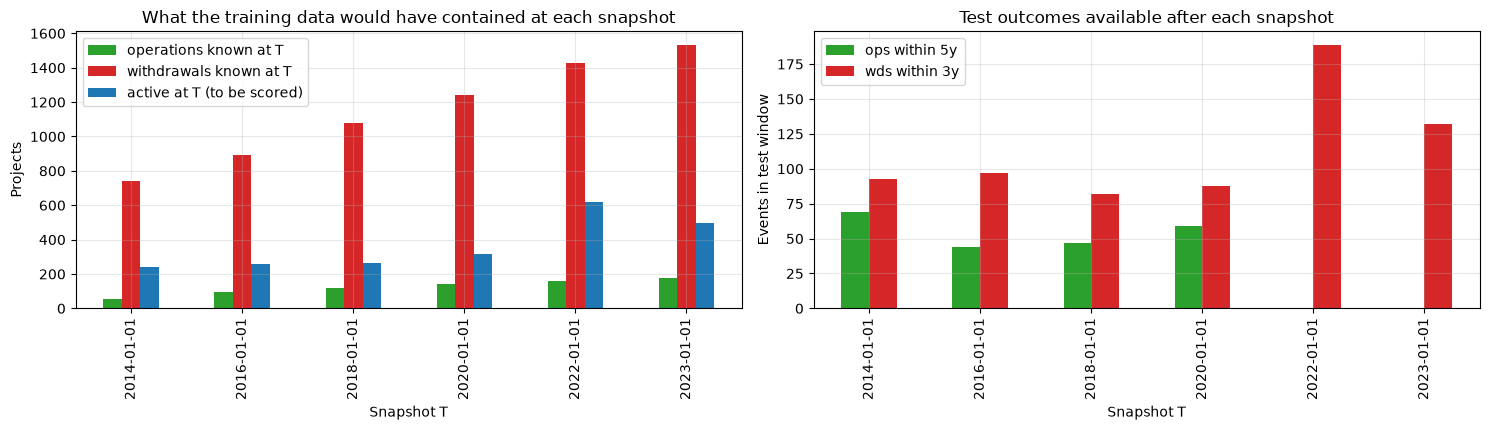

In [43]:
# --- 12.1 Reconstruct the training and test data at past snapshots.
backtest_dates = [pd.Timestamp(f"{y}-01-01") for y in [2014, 2016, 2018, 2020, 2022, 2023]]
rows = []
for T in backtest_dates:
    known = analysis[analysis["queue_date"] <= T]
    known_ev = known["event_date"].notna() & (known["event_date"] <= T)
    at_risk_T = known[~known_ev]
    row = {"snapshot T": T.date(), "queued by T": len(known), "operations known at T": int((known_ev & (known["event"] == 1)).sum()),
           "withdrawals known at T": int((known_ev & (known["event"] == 2)).sum()), "active at T (to be scored)": len(at_risk_T)}
    for H in [3, 5]:
        horizon_end = T + pd.DateOffset(years=H)
        if horizon_end > sd.C15_ASSUMED_SNAPSHOT:
            row.update({f"ops within {H}y": np.nan, f"wds within {H}y": np.nan})
            continue
        in_window = at_risk_T["event_date"].notna() & (at_risk_T["event_date"] <= horizon_end)
        row[f"ops within {H}y"] = int((in_window & (at_risk_T["event"] == 1)).sum())
        row[f"wds within {H}y"] = int((in_window & (at_risk_T["event"] == 2)).sum())
    rows.append(row)
backtest = pd.DataFrame(rows).set_index("snapshot T")
display(backtest)

def hanley_mcneil_halfwidth(auc, n_pos, n_neg):
    # 95% half-width of an AUC estimate (Hanley and McNeil 1982); used to ask how precisely a test could measure discrimination.
    if not (n_pos > 1 and n_neg > 1):
        return np.nan
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    se = np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc ** 2) + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg))
    return 1.96 * se

prec = []
for T, r in backtest.iterrows():
    for cause, col in [("operation within 5y", "ops within 5y"), ("withdrawal within 3y", "wds within 3y")]:
        H = int(col.split("within ")[1][0])
        n_pos = r[col]
        n_neg = r["active at T (to be scored)"] - n_pos if pd.notna(n_pos) else np.nan
        prec.append({"snapshot T": T, "target": cause, "events in test": n_pos, "non-events in test": n_neg,
                     "95% half-width of AUC 0.70": hanley_mcneil_halfwidth(0.70, n_pos, n_neg) if pd.notna(n_pos) else np.nan})
prec = pd.DataFrame(prec).pivot(index="snapshot T", columns="target", values=["events in test", "95% half-width of AUC 0.70"])
display(prec)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
backtest[["operations known at T", "withdrawals known at T", "active at T (to be scored)"]].plot(kind="bar", ax=axes[0], color=["tab:green", "tab:red", "tab:blue"])
axes[0].set(title="What the training data would have contained at each snapshot", xlabel="Snapshot T", ylabel="Projects")
backtest[["ops within 5y", "wds within 3y"]].plot(kind="bar", ax=axes[1], color=["tab:green", "tab:red"])
axes[1].set(title="Test outcomes available after each snapshot", xlabel="Snapshot T", ylabel="Events in test window")
plt.tight_layout(); plt.show()

**Interpretation.**
* **Snapshot backtests are feasible.** For each snapshot between 2014 and 2023 we can rebuild what the training data would have looked like (for example, on 2020-01-01: 1,693 queued projects, 139 operations and 1,240 withdrawals known, 314 projects still active) and see what happened afterward.
* **Withdrawal tests have strong support:** 82 to 189 withdrawals in the 3-year window after each snapshot, so AUC could be measured to within about +/- 0.05 to 0.07.
* **Operation tests are thinner:** 44 to 69 operations within 5 years, which gives an AUC precision of about +/- 0.08 to 0.09, and only possible for snapshots up to 2020 (later snapshots do not have 5 years of follow-up). Even the best snapshot gives wide intervals.
* **A useful by-product: the chance that an active project eventually operates is much higher once it has survived.** For the 2014 snapshot, 69 of 241 active projects (29%) operated within 5 years; for 2018, 47 of 263 (18%). That compares with a population-wide probability of operation by year 5 of 3.3% from age 0. The screener must therefore score projects *conditional on their current age*.

In [44]:
# --- 12.2 Why splits must respect clusters and time: how events are spread over cohorts.
by_cohort = pd.crosstab(analysis["cohort"], analysis["event"].map(sd.EVENT_LABELS)).reindex(cohort_order).dropna(how="all")
by_cohort["share of all operations"] = by_cohort["operation"] / by_cohort["operation"].sum()
display(by_cohort.T)
share_last = by_cohort.loc[["C13", "C14", "C15"], "operation"].sum() / by_cohort["operation"].sum()
print(f"Share of all operations that occurred in Clusters 13-15 (the most recent test candidates): {share_last:.1%}")

# --- 12.3 Metric feasibility.
metric_feasibility = pd.DataFrame([
    ("Early withdrawal, 1-3 years", "Time-dependent AUC and calibration of P(withdraw by 1y/3y)", "Feasible", "Hundreds of events in every recent test window"),
    ("Operation within 3-5 years", "Time-dependent AUC for P(operate by 5y)", "Marginal", "Few operations per window; wide intervals (see 12.1)"),
    ("Operation within 8-10 years", "Calibration of long-horizon operation probability", "Only for old cohorts", "Test cohorts that old were queued before 2016, a different regime"),
    ("Cluster 15 test", "Short-horizon withdrawal only", "Feasible, short horizon", "No operations; only 1.6 years of follow-up"),
    ("Overall ranking", "Concordance index", "Feasible, but dominated by withdrawal ordering", "Operation ordering is a small part of the pairs"),
    ("Cluster-level uncertainty", "Block bootstrap by cohort", "Required", "Projects within a cluster share shocks (Section 7)"),
], columns=["target", "metric", "feasibility", "reason"])
with pd.option_context("display.max_colwidth", 80):
    display(metric_feasibility.set_index("target"))

cohort,Pre-cluster,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11,C12,C13,C14,C15
event,,,,,,,,,,,,,,,,
active (censored),22.000,2.000,1.000,1.000,5.000,1.000,3.000,6.000,9.000,11.000,14.000,17.000,30.000,36.000,104.000,86.000
operation,103.000,5.000,12.000,7.000,13.000,5.000,10.000,12.000,22.000,16.000,8.000,8.000,7.000,2.000,0.000,0.000
withdrawal,486.000,18.000,44.000,40.000,171.000,70.000,48.000,64.000,88.000,96.000,66.000,67.000,98.000,108.000,255.000,84.000
share of all operations,0.448,0.022,0.052,0.030,0.057,0.022,0.043,0.052,0.096,0.070,0.035,0.035,0.030,0.009,0.000,0.000


Share of all operations that occurred in Clusters 13-15 (the most recent test candidates): 0.9%


,metric,feasibility,reason
target,,,
"Early withdrawal, 1-3 years",Time-dependent AUC and calibration of P(withdraw by 1y/3y),Feasible,Hundreds of events in every recent test window
Operation within 3-5 years,Time-dependent AUC for P(operate by 5y),Marginal,Few operations per window; wide intervals (see 12.1)
Operation within 8-10 years,Calibration of long-horizon operation probability,Only for old cohorts,"Test cohorts that old were queued before 2016, a different regime"
Cluster 15 test,Short-horizon withdrawal only,"Feasible, short horizon",No operations; only 1.6 years of follow-up
Overall ranking,Concordance index,"Feasible, but dominated by withdrawal ordering",Operation ordering is a small part of the pairs
Cluster-level uncertainty,Block bootstrap by cohort,Required,Projects within a cluster share shocks (Section 7)


**Interpretation.**
* **Only 0.9% of all operations (2 of 230) happened in Clusters 13 to 15,** the most obvious candidates for a final test set. A test restricted to the newest clusters can evaluate early withdrawal but cannot evaluate operation at all.
* **Operation can only be evaluated on older snapshots** (2014 to 2020), when the world was different, so a good score there is weak evidence about the current regime.
* The feasibility table summarizes what can be tested: withdrawal over 1 to 3 years (yes, well), operation over 3 to 5 years (marginal), operation over 8 to 10 years (only on old cohorts), and Cluster 15 (short-horizon withdrawal only).
* **Design rules for the modeling plan:** split by time or by cohort block, never at random; use the snapshot backtests as the primary evaluation; bootstrap clusters (not projects) for intervals; and report operation metrics with the intervals in 12.1 beside them.

# Part D: Conclusions

## 13. Results and recommendations

**Purpose.** Turn the evidence in Sections 1 to 12 into (a) an honest verdict on whether these data can support a competing-risks survival
model, (b) a recommended modeling approach, (c) what results to expect, and (d) what the model can and cannot do for the agentic
interconnection-risk screener.

**How to read this section.** Numbers quoted here come from the live outputs above; the next cell recomputes the main ones so they can be
checked against the text.

In [45]:
# Key numbers quoted in the conclusions, recomputed live.
ops_total, wds_total, cens_total = [int((analysis["event"] == k).sum()) for k in (1, 2, 0)]
ev_by_era = analysis.groupby("era", observed=True)["event"].value_counts().unstack(fill_value=0)
scorecard = pd.Series({
    "projects in main analysis table": len(analysis),
    "operations / withdrawals / active": f"{ops_total} / {wds_total} / {cens_total}",
    "projects dropped (unknown event date + ended before 2007)": (len(raw_table) - len(analysis)),
    "median time in queue (years)": round(float(km_any.index[km_any['survival'] <= 0.5][0]), 2),
    "P(withdrawn by 1y / 3y / 5y)": " / ".join(f"{v:.3f}" for v in sd.cif_at(d_all, e_all, 2, [1, 3, 5], ent_all)),
    "P(operating by 3y / 5y / 8y / 10y)": " / ".join(f"{v:.3f}" for v in sd.cif_at(d_all, e_all, 1, [3, 5, 8, 10], ent_all)),
    "naive 1-KM P(operating by 8y) vs correct": f"{float(sd.step_value(naive_op, 8)[0]):.3f} vs {float(sd.cif_at(d_all, e_all, 1, 8, ent_all)[0]):.3f}",
    "operations queued 2013+ / 2017+ / Clusters 13-15": f"{int(((analysis['queue_year'] >= 2013) & (analysis['event'] == 1)).sum())} / {int(((analysis['queue_year'] >= 2017) & (analysis['event'] == 1)).sum())} / {int((analysis['cohort'].isin(['C13', 'C14', 'C15']) & (analysis['event'] == 1)).sum())}",
    "Cluster 15: projects / active / withdrawn": f"{int(is15.sum())} / {int(((analysis['cohort']=='C15') & (analysis['event']==0)).sum())} / {int(((analysis['cohort']=='C15') & (analysis['event']==2)).sum())}",
    "Cluster 15 follow-up (years)": round(float(analysis.loc[is15, 'duration_years'].max()), 2),
    "adversarial AUC: C15 vs C09-C14": round(float(adv.loc["C15 vs C09-C14", "AUC"]), 3),
    "adversarial AUC: adjacent-cluster benchmarks": f"{adv.iloc[2:]['AUC'].min():.2f}-{adv.iloc[2:]['AUC'].max():.2f}",
})
display(scorecard.to_frame("value"))

,value
projects in main analysis table,2381
operations / withdrawals / active,230 / 1803 / 348
projects dropped (unknown event date + ended before 2007),67
median time in queue (years),1.560
P(withdrawn by 1y / 3y / 5y),0.391 / 0.638 / 0.719
P(operating by 3y / 5y / 8y / 10y),0.011 / 0.033 / 0.087 / 0.115
naive 1-KM P(operating by 8y) vs correct,0.339 vs 0.087
operations queued 2013+ / 2017+ / Clusters 13-15,94 / 33 / 2
Cluster 15: projects / active / withdrawn,170 / 86 / 84
Cluster 15 follow-up (years),1.610


### 13.1 Strengths of the dataset for survival modeling

1. **A clean, well-defined time origin and event structure.** Every project has a queue date and one of three states. The
   survival table reconciles exactly with the workbooks (252 operational, 1,764 withdrawn, 262 active in the older workbook; 86 active and
   84 withdrawn in Cluster 15), and every active project is censored exactly at the snapshot, so censoring is administrative and plausibly
   non-informative.
2. **Large withdrawal sample.** 1,803 withdrawals in the main table is ample for a stable cause-specific model of *early exit*, with detectable
   hazard ratios as low as about 1.14 to 1.35 (Section 11).
3. **Real competing-risks structure.** Withdrawal is early and fast (about 39% by one year); operation is late and slow (about 3% by year 5
   and about 12% by year 10). Treating them as one outcome or ignoring withdrawals as competing would be badly wrong (Section 0 and 6).
4. **Includes the unfinished projects.** The 348 active projects (including all of Cluster 15) contribute information that the
   binary classifier had to discard.
5. **Robust headline estimates.** The overall curves changed by at most a few percentage points under every data-handling alternative tested
   (Section 6.5).
6. **Queue-entry features exist for both workbooks,** with a clean leakage boundary (Section 10).

### 13.2 Limitations and risks

1. **Operation is rare, old, and almost absent from the recent regime.** 230 operations overall, but only 94 among projects queued 2013 or
   later, 33 for 2017 or later, and 2 in Clusters 13 to 15. The model of the outcome the screener cares about most is learned mainly from the
   pre-2013 queue.
2. **Process rules create calendar-driven bursts, so age alone does not define risk.** Withdrawals cluster at cohort milestones
   (Section 7): Cluster 14 withdrew almost nobody in its first 1.5 years and then shed about 130 projects in three months, whereas
   Clusters 10 to 13 and 15 had lost 49% to 64% by then. The baseline hazard shape therefore differs by cluster, which violates
   the single-baseline assumption of a standard survival model.
3. **Left truncation.** Records before about 2007 are incomplete. Delayed entry fixes the main distortion, but the oldest projects (queued
   2000 to 2006) rest on the assumption that all survivors into 2007 were recorded.
4. **Cluster 15 is short.** 1.6 years of follow-up, no operations, one shared queue date, and a snapshot date that is assumed. It supports only
   early-withdrawal evidence. It also looks different from older clusters (adversarial AUC 0.89 versus 0.74 to 0.79 for adjacent clusters),
   with more 500 kV interconnections, longer requested timelines, and more energy-only service.
5. **Effects are not constant.** The storage effect on withdrawal moves from a hazard ratio of about 0.06 (2007 to 2012, only about 43 storage projects)
   to 0.5 (2013 to 2016) to 0.8 (2017 and later, not statistically different from 1). Several proportional-hazards checks fail
   (Section 9.5), and storage share rose from 4% to 87% across eras, so era and technology are tangled.
6. **Dependence.** Projects share cluster shocks, so ordinary confidence intervals are too narrow; only 16 cohorts limit how well that
   can be corrected.
7. **Few and mostly era-linked features.** The usable features are size, technology, voltage, service type, requested timeline, and location.
   The strongest "feature" signals (service type not recorded, serial process) are era markers, not project characteristics.
   Post-entry milestones, which probably carry the most signal, are excluded as leakage and are not available as dated time-varying fields.

### 13.3 Applicability verdict

| Question the screener might ask | Can survival modeling support it? | Why |
|---|---|---|
| "How likely is this project to withdraw within the next 1 to 3 years?" | **Yes, with the best evidence** | Over 1,800 withdrawals, many in recent cohorts, short horizons that Cluster 15 can verify |
| "How does this project compare with its peers?" (ranking) | **Yes, moderate** | Feature effects are real (storage, hybrid, size, service type) but modest; expect partial discrimination |
| "What fraction of projects like this eventually operate?" | **Yes, as a base rate** | Nonparametric AJ curves by group are reliable where enough projects are at risk |
| "Will *this* project operate within 5 years?" | **Only weakly** | Few recent operations; the signal comes from the older regime; wide intervals (Section 12) |
| "What happens to a Cluster 15 project over 8 to 10 years?" | **Extrapolation, not validated** | No Cluster 15 operation exists; long horizons rely on older clusters whose rules and technology mix differ |
| "What is the probability, given it has survived 2 years, that it operates?" | **Possible** (landmark or conditional CIF) | The screener scores projects at many ages; the model must support entry at age > 0 |

**Bottom line.** The data are **well suited to modeling early withdrawal timing and to producing honest, age-aware base rates**, and
**poorly suited to learning what makes a project operate**. A survival model is the right framework (it uses the active and Cluster 15
projects, respects timing, and handles competing outcomes), but it will not magically create operation signal that the data do not
contain. I expect it to improve *coverage and calibration of the time dimension*, not to dramatically improve discrimination of eventual success over the binary classifier.

### 13.4 Recommended modeling approach (for the next plan)

1. **Primary model: cause-specific Cox models** (one for withdrawal, one for operation) with delayed entry from 2007-01-01, cohort-clustered
   robust standard errors, **baseline hazard stratified by era or cohort group**, and a small, pre-specified feature set (size, storage/hybrid,
   technology group, voltage, service type, requested timeline). Convert to cumulative incidence at fixed horizons (1, 3, 5, and 8 years).
2. **Challenger: discrete-time hazard model** (logistic or gradient boosting on person-period data with age band and cohort-phase effects).
   It can absorb the burst timing that a proportional-hazards model cannot and handles ties naturally.
3. **Optional challenger: random survival forest / gradient-boosted survival model,** only if delayed entry can be handled (for example, by fitting on
   projects queued 2007 or later). Its main value is detecting interactions.
4. **Do not** use a single parametric (Weibull) model; the hazards are non-monotone and bursty (Section 6.2).
5. **Report always:** the nonparametric AJ curve for the comparison group next to any model prediction, and cluster-block bootstrap intervals.
6. **Prediction target for the agent:** CIFs for withdrawal and operation at fixed horizons, **conditional on the project's current age**
   (a project already 3 years old should be scored from age 3, not from age 0).

### 13.5 Expected results (calibrated expectations, not promises)

* **Withdrawal within 1 to 3 years:** moderate discrimination (time-dependent AUC roughly 0.60 to 0.70). The cause-specific Cox fit shows an in-sample
  concordance of about 0.64 for withdrawal; out-of-sample should be lower. Calibration at the *level* of risk will depend mainly on whether the model
  captures the cluster's milestone timing (Cluster 14 versus Cluster 15), not on project features.
* **Operation within 5 years:** weak to moderate discrimination, roughly 0.65 to 0.75, with test-set half-widths of about +/- 0.08 to 0.09 even
  at the best snapshot (Section 12.1). The in-sample concordance of 0.84 for operation is inflated by era markers (process type, service type not recorded) and should not be expected out of sample.
* **Forward-looking level of risk:** plan for the possibility of the same direction of error as the binary model, because operation probabilities learned from older clusters
  overstate success in a regime where almost nothing has yet operated (Section 11).
* **Modest gain over the binary classifier on rank-ordering eventual success;** larger gain on time-to-withdrawal questions the classifier could not answer at all.

### 13.6 Usefulness for the agentic interconnection-risk screener

* **Useful:** age-aware withdrawal risk, peer base rates ("projects with storage: 63% withdrew within 5 years and about 1% operated by year 5"), expected time horizons,
  and a principled way to say "this project is old and still active, which itself raises the chance it will operate" (conditional probabilities).
* **Use with care:** project-specific operation probabilities; they are screening signals, not forecasts. They should be presented with intervals and the
  comparison curve.
* **Do not claim:** a validated 8 to 10 year success probability for a Cluster 15 project.

### 13.7 Decisions carried forward

| Decision | Choice | Where established |
|---|---|---|
| Time origin | Queue date | Section 3 |
| Snapshot dates | 2026-09-24 for both workbooks (Cluster 15 assumed; no effect on early curves) | Sections 1 and 8.4 |
| Left truncation | Delayed entry from 2007-01-01; restriction as robustness check | Section 4 |
| Missing event dates | Drop 52 (main); imputation changes no headline estimate by more than about 1 point | Sections 3 and 6.5 |
| Non-positive durations | Set to 1 day (4 projects) | Section 3 |
| Cluster 15 | Pool as censored data; use as short-horizon withdrawal check only; do not use for operation | Section 8 |
| Features | Queue-entry features only; exclude post-entry milestones | Section 10 |
| Era | Stratify baseline hazard by era/cohort group; evaluate on later cohorts | Sections 7 and 9.8 |
| Standard errors | Cluster-robust / block bootstrap by cohort | Sections 7 and 12 |
| Old 137-ID holdout | Not protected; new splits defined in the modeling plan | Agreed with project owner |

### 13.8 Questions and cautions for the modeling plan

1. **What is the screener's primary output?** A fixed-horizon table (1, 3, 5, 8 year CIFs) is recommended. Confirm it, because it determines the metrics.
2. **Can dated milestone information be obtained** (Phase I and II study result dates, agreement dates)? Those would be legitimate time-varying
   covariates and probably the single biggest accuracy gain; the current workbooks do not have dates.
3. **How should the screener treat projects older than their cluster's usual timeline?** The conditional-on-survival question matters because most projects a user
   will ask about are already some years old.
4. **Cluster 15 exact export date.** Confirm it if possible; the early curves are insensitive to it, but the follow-up limit is not.
5. **Cautions.** (a) Do not tune on Cluster 15 and report on Cluster 15. (b) Never split randomly; split by time or by cohort block. (c) Report intervals that respect clustering.
   (d) Keep the Aalen-Johansen curves in the final product as the reference every model must beat. (e) Do not interpret hazard ratios causally (for example, "adding storage
   halves withdrawal risk"): they are associations confounded by era and by developer behavior not captured in the data.

### 13.9 Reconciliation and integrity checks

The final cell re-verifies, with assertions, the counts and identities that the whole analysis depends on. If any fails, the notebook stops.

In [46]:
# 1. Counts reconcile with the source workbooks.
src = projects.groupby("source_sheet")["outcome"].agg(["size"])
assert projects["outcome"].value_counts().to_dict() == {"withdrawn": 1848, "active": 348, "operational": 252}, "Outcome counts changed"
assert (projects.groupby(["source", "outcome"]).size().to_dict() ==
        {("C14 workbook", "active"): 262, ("C14 workbook", "operational"): 252, ("C14 workbook", "withdrawn"): 1764,
         ("C15 workbook", "active"): 86, ("C15 workbook", "withdrawn"): 84}), "Workbook counts changed"

# 2. Survival-table integrity (also asserted when the table was built).
sd.assert_survival_table(table_all); sd.assert_survival_table(analysis)
assert raw_table["event_after_snapshot"].sum() == 0 and int(raw_table["event_date_missing"].sum()) == 52
assert len(raw_table) - len(analysis) == 67  # 52 unknown event dates + 15 projects that ended before 2007

# 3. Competing-risks identity: CIF_operation + CIF_withdrawal + S(t) = 1 at every event time.
total = sd.aj_cif(d_all, e_all, 1, ent_all)["cif"] + sd.aj_cif(d_all, e_all, 2, ent_all)["cif"] + sd.aj_cif(d_all, e_all, 1, ent_all)["survival_any"]
assert np.allclose(total, 1.0), "CIFs and S(t) do not add to one"

# 4. Cross-check the estimator against lifelines on the real data (no delayed entry, small jitter-free subset: restricted table).
res = analysis[analysis["queue_date"] >= WINDOW_START]
rd, re_ = res["duration_years"].to_numpy(), res["event"].to_numpy()
ours = sd.cif_at(rd, re_, 2, [1, 3, 5])
lf = AalenJohansenFitter(calculate_variance=False, seed=1).fit(rd, re_, event_of_interest=2).cumulative_density_.iloc[:, 0]
theirs = [lf[lf.index <= h].iloc[-1] for h in [1, 3, 5]]
assert np.allclose(ours, theirs, atol=0.01), (ours, theirs)

# 5. Every active project is censored at its snapshot; durations are positive; entry precedes the end.
assert (analysis.loc[analysis["event"] == 0, "end_date"] == analysis.loc[analysis["event"] == 0, "snapshot_date"]).all()
assert (analysis["duration_years"] > analysis["entry_years"]).all()
print("All integrity checks passed.")
print("Our Aalen-Johansen withdrawal CIF at 1/3/5 years:", np.round(ours, 4), "| lifelines:", np.round(theirs, 4))

All integrity checks passed.
Our Aalen-Johansen withdrawal CIF at 1/3/5 years: [0.3971 0.6468 0.728 ] | lifelines: [0.3971 0.6468 0.728 ]
